# 02 · Feature analysis and leakage-safe preprocessing

**Question.** Which permitted observations carry complementary information about the hidden current aggregate, and can their preparation remain invariant to current-target and future perturbations?

Only the refined Plegma development artifacts from Notebook 01 are opened. Exploratory feature decisions use the first fold's training portion, while preprocessing is fitted independently for each fold. No predictive model is fitted here. Protected calibration, temporal, group and external targets remain inaccessible. Training-dependent sensor duplication, scaling, imputation, mask statistics and rankings are saved together with the identifiers of the training observations used to fit them. Sensor-set tensors retain individual channels; a fixed semantic summary supplies tabular controls.

In [1]:
from pathlib import Path
import hashlib, json, re, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "Notebooks":
    ROOT = ROOT.parent
assert ROOT.is_dir()
REFINED = ROOT / "Data/Interim/development_minutes_refined"
RUN = "guldana_n3_20261007_v01"
TABLES = ROOT / "Tables" / RUN / "02_features"
FIGURES = ROOT / "Figures/PNG" / RUN
for directory in [TABLES, FIGURES, ROOT / "Data/Interim/timestamp_index"]:
    directory.mkdir(parents=True, exist_ok=True)
font_path = font_manager.findfont("Times New Roman", fallback_to_default=False)
assert Path(font_path).is_file()
mpl.rcParams.update({"font.family": "Times New Roman", "font.size": 18,
                     "axes.titlesize": 20, "axes.labelsize": 18,
                     "xtick.labelsize": 18, "ytick.labelsize": 18,
                     "legend.fontsize": 18, "figure.dpi": 350,
                     "savefig.dpi": 350, "axes.unicode_minus": True,
                     "pdf.fonttype": 42, "ps.fonttype": 42})
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 80)


# Keep HTML tables compact; publication font requirements apply to Matplotlib figures.
def table(frame, name, caption, precision=4):
    frame.to_csv(TABLES / (name + ".csv"), index=False)
    frame.to_latex(TABLES / (name + ".tex"), index=False, caption=caption,
                   float_format=lambda x: f"{x:.{precision}f}")
    def signed_number(x):
        rounded = round(float(x), precision)
        return f"{0.0 if rounded == 0 else rounded:.{precision}f}".replace("-", "−")
    formatters = {col: signed_number for col in frame.select_dtypes(include="floating").columns}
    display(frame.style.format(formatters, na_rep="Unavailable").hide(axis="index").set_caption(caption))
# Figure export verifies the real font, all text sizes and PNG density before inline display.
from IPython.display import Image
from PIL import Image as PILImage
import matplotlib.dates as mdates
from matplotlib.text import Text
FIGURE_PNG = ROOT / "Figures/PNG" / RUN
FIGURE_PDF = ROOT / "Figures/PDF" / RUN
FIGURE_PNG.mkdir(parents=True, exist_ok=True)
FIGURE_PDF.mkdir(parents=True, exist_ok=True)
figure_qa = []
def save_figure(fig, name):
    fig.canvas.draw()
    texts = [t for t in fig.findobj(Text) if t.get_visible() and t.get_text().strip()]
    for text_item in texts:
        assert 18 <= text_item.get_fontsize() <= 20, (text_item.get_text(), text_item.get_fontsize())
        resolved = font_manager.findfont(text_item.get_fontproperties(), fallback_to_default=False)
        assert font_manager.FontProperties(fname=resolved).get_name() == "Times New Roman"
    png = FIGURE_PNG / f"{name}.png"
    pdf = FIGURE_PDF / f"{name}.pdf"
    fig.savefig(png, dpi=350, bbox_inches="tight", pad_inches=.06)
    fig.savefig(pdf, dpi=350, bbox_inches="tight", pad_inches=.06)
    with PILImage.open(png) as im:
        assert all(abs(d - 350) < .02 for d in im.info["dpi"])
        figure_qa.append({"Figure": name, "Width px": im.width, "Height px": im.height, "DPI": im.info["dpi"][0],
                          "Font": "Times New Roman", "Text items checked": len(texts)})
    plt.close(fig)
    display(Image(filename=str(png)))


gate = json.loads((ROOT / "Manifests/nb01_gate.json").read_text())
assert gate["status"] == "primary_development_data_adequate_for_nb02"
schema = json.loads((ROOT / "Configs/sensor_schema.json").read_text())
semantic_map = pd.read_csv(ROOT / "Data/Interim/sensor_semantic_map.csv")
PREP = ROOT / "Models/preprocessing" / RUN
PREP.mkdir(parents=True,exist_ok=True)


In [3]:
# Complete scientific tables: semantic groups, unchanged values, mathematical minus.
# This display-only setup does not fit models or modify numerical exports.
import copy as _table_copy
import re as _table_re
import pandas as _table_pd
from bs4 import BeautifulSoup as _TableSoup, NavigableString as _TableText
from pandas.io.formats.style import Styler as _TableStyler
from IPython.display import HTML as _TableHTML
import hashlib as _table_hashlib, json as _table_json
_table_layout_bytes = (ROOT / "Configs/article_table_layout.json").read_bytes()
assert _table_hashlib.sha256(_table_layout_bytes).hexdigest() == "fbbb6522e8c59dbde1eea0021da0a6f72e3257d1c6d0c8d49e74c5bd3a6a9d8c"
_ARTICLE_TABLE_GROUPS = _table_json.loads(_table_layout_bytes)
_ARTICLE_NUMBER = _table_re.compile(r"^\s*[+−-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+−-]?\d+)?%?\s*$")
def _article_table_layout(tag, additions):
    declarations = dict(part.strip().split(":", 1) for part in tag.get("style", "").split(";") if ":" in part)
    declarations.update(additions)
    tag["style"] = ";".join(key + ":" + value for key, value in declarations.items()) + ";"
def _article_table_html(html):
    soup = _TableSoup(html, "html.parser")
    for table in list(soup.find_all("table")):
        head = table.find("thead")
        body = table.find("tbody")
        if head is None or body is None:
            continue
        heads = [tag.get_text(strip=True) for tag in head.find_all("th")]
        rule = _ARTICLE_TABLE_GROUPS.get("|".join(heads))
        if rule is not None and len(head.find_all("tr")) == 1:
            rows = body.find_all("tr", recursive=False)
            if all(len(row.find_all(["th", "td"], recursive=False)) == len(heads) for row in rows):
                assert set(sum(rule["columns"], [])) == set(heads)
                original_styles = [style.get_text() for style in soup.find_all("style")]
                for number, (columns, label) in enumerate(zip(rule["columns"], rule["labels"]), 1):
                    part = _table_copy.deepcopy(table)
                    keep = [heads.index(name) for name in columns]
                    for row in part.find_all("tr"):
                        for index, tag in enumerate(row.find_all(["th", "td"], recursive=False)):
                            if index not in keep:
                                tag.decompose()
                    caption = part.find("caption")
                    if caption is None:
                        caption = soup.new_tag("caption")
                        part.insert(0, caption)
                    caption.append(" " + label)
                    suffix = "_article_part_" + str(number)
                    original_id = table.get("id")
                    for tag in [part] + part.find_all(True):
                        if tag.has_attr("id"):
                            tag["id"] = (tag["id"].replace(original_id, original_id + suffix, 1)
                                         if original_id and tag["id"].startswith(original_id) else tag["id"] + suffix)
                    if original_id:
                        for style_text in original_styles:
                            if "#" + original_id in style_text:
                                copied_style = soup.new_tag("style")
                                copied_style.string = style_text.replace("#" + original_id, "#" + original_id + suffix)
                                table.insert_before(copied_style)
                    table.insert_before(part)
                table.decompose()
    for table in soup.find_all("table"):
        _article_table_layout(table, {"max-width":"100%", "table-layout":"auto", "margin-bottom":"1.4em"})
        for tag in table.find_all(["th", "td", "caption"]):
            _article_table_layout(tag, {"white-space":"normal", "vertical-align":"top"})
            if tag.name == "caption":
                _article_table_layout(tag, {"text-align":"left", "caption-side":"top"})
            for old_break in list(tag.find_all("wbr")):
                old_break.decompose()
            for node in list(tag.descendants):
                if not isinstance(node, _TableText) or node.parent.name in {"code", "pre", "script", "style"}:
                    continue
                text = str(node)
                if tag.name == "td" and _ARTICLE_NUMBER.fullmatch(text):
                    text = text.replace("-", "−")
                chunks = _table_re.split("(?<=_)", text)
                for index, chunk in enumerate(chunks):
                    node.insert_before(_TableText(chunk))
                    if index + 1 < len(chunks):
                        node.insert_before(soup.new_tag("wbr"))
                node.extract()
    return str(_TableSoup(str(soup), "html.parser"))
def _article_styler_html(value):
    with _table_pd.option_context("styler.render.max_elements", max(1, value.data.size + len(value.data)),
                                  "styler.render.max_rows", None, "styler.render.max_columns", None):
        html = value.to_html(max_rows=len(value.data), max_columns=len(value.data.columns))
    assert not _TableSoup(html, "html.parser").select(".row_trim, .col_trim"), "Scientific table was truncated"
    return _article_table_html(html)
def _article_frame_html(value):
    return _article_table_html(value.to_html(max_rows=None, max_cols=None))
def _article_HTML_html(value):
    result = value._repr_html_()
    if isinstance(result, tuple):
        return _article_table_html(result[0]), result[1]
    return _article_table_html(result)
_table_format = get_ipython().display_formatter.formatters["text/html"]
_table_format.for_type(_TableStyler, _article_styler_html)
_table_format.for_type(_table_pd.DataFrame, _article_frame_html)
_table_format.for_type(_TableHTML, _article_HTML_html);


## 1. Development representation and fold boundaries

Minute values are means of actual valid observations. Invalid and absent values remain NaN; an observed zero remains zero with availability true. Only past aggregate values are available to inputs. Current aggregate coverage, validity and any residual or aggregate-normalized statistic are excluded. Current environmental observations are allowed only where their timestamps and quality are valid. Source-local clock encodings are deterministic.

In [2]:
# Load development-only minute artifacts, preserving IDs and separate validity states.
houses = {}
cohort_rows = []
for house in range(1,11):
    path = REFINED / f"plegma_house_{house:02d}.parquet"
    assert hashlib.sha256(path.read_bytes()).hexdigest() == gate["refined_files"][str(path.relative_to(ROOT))]
    data = pd.read_parquet(path)
    ids = pd.read_parquet(ROOT / f"Manifests/observation_ids/plegma_house_{house:02d}.parquet")
    ids = ids.loc[ids.split.eq("development")].set_index("timestamp")
    values = data.pivot(index="timestamp",columns="sensor",values="mean").reindex(ids.index)
    available = data.pivot(index="timestamp",columns="sensor",values="available").reindex(ids.index).fillna(False).astype(bool)
    coverage = data.pivot(index="timestamp",columns="sensor",values="coverage_fraction").reindex(ids.index)
    states = data.pivot(index="timestamp",columns="sensor",values="state").reindex(ids.index)
    assert values.index.equals(ids.index) and not {"A","V"}.intersection(values.columns)
    assert np.isfinite(values.where(available).stack()).all()
    eligible = available.P_agg & ~ids.context_only
    houses[house] = {"values":values,"available":available,"coverage":coverage,"states":states,"ids":ids,"eligible":eligible}
    cohort_rows.append({"House":house,"Eligible targets":int(eligible.sum()),
        "Fold 1 train":int((eligible & ids.fold_1.eq("train")).sum()),
        "Fold 1 inner validation":int((eligible & ids.fold_1.eq("inner_validation")).sum()),
        "Fold 1 outer validation":int((eligible & ids.fold_1.eq("outer_validation")).sum())})
cohort = pd.DataFrame(cohort_rows)
table(cohort,"nb02_development_cohort","Table 1. Development targets and first-fold roles entering feature analysis.",precision=0)
assert cohort["Eligible targets"].sum() == gate["eligible_development_targets"]

House,Eligible targets,Fold 1 train,Fold 1 inner validation,Fold 1 outer validation
1,438243,147315,23285,89198
2,206516,69002,12100,41541
3,440000,143698,26370,89550
4,347843,118470,20366,70778
5,259127,87677,15290,52334
6,173554,38409,11945,40926
7,308641,104544,19070,62799
8,209110,70690,12225,41966
9,234501,79850,13465,47318
10,130043,44870,7918,19923


**Interpretation.** The loaded development target counts exactly match Notebook 01. Fold 1 training sizes vary markedly across houses; later diagnostics use equal-house sampling where appropriate, while preprocessing fitting retains every eligible training row.

## 2. Training-only duplicate recognition

Exact stream equality is tested among power auxiliaries using only training minutes, with at least 1,440 paired values and 20 distinct values to avoid declaring idle appliances duplicates. Equality must hold for the full available-mask pattern and every jointly observed value in that training portion. Connected duplicate groups become one numerically represented stream with canonical type `unknown` if their metadata labels conflict. A stable original-name order chooses a representative without inspecting the hidden aggregate. The same stored map is applied unchanged to validation. Coincident equal values at prediction time do not trigger new fitting.

In [3]:
# Duplicate maps are fitted independently within each fold's training role.
from itertools import combinations

def fit_duplicate_map(house, train_mask):
    info = houses[house]
    meta = semantic_map.query("house == @house and role == 'auxiliary_power'")
    sensors = sorted(meta.original_sensor)
    parent = {s:s for s in sensors}
    def find(s):
        while parent[s] != s: s = parent[s]
        return s
    evidence = []
    v = info["values"].loc[train_mask,sensors]
    for a,b in combinations(sensors,2):
        paired = v[[a,b]].dropna()
        enough = len(paired)>=1440 and paired[a].nunique()>=20
        exact = enough and v[a].notna().equals(v[b].notna()) and np.array_equal(paired[a].to_numpy(),paired[b].to_numpy())
        if exact:
            pa,pb = find(a),find(b)
            parent[max(pa,pb)] = min(pa,pb)
            evidence.append({"House":house,"Sensor A":a,"Sensor B":b,"Paired train minutes":len(paired),"Distinct values":paired[a].nunique()})
    groups = {}
    types = meta.set_index("original_sensor").canonical_type.to_dict()
    for s in sensors: groups.setdefault(find(s),[]).append(s)
    mapping = {rep:{"members":members,"type":types[rep] if len({types[s] for s in members})==1 else "unknown"}
               for rep,members in groups.items()}
    return mapping,evidence

duplicate_maps, duplicate_evidence = {}, []
for fold in [1,2,3]:
    duplicate_maps[fold] = {}
    for house,info in houses.items():
        mask = info["ids"][f"fold_{fold}"].eq("train")
        mapping,evidence = fit_duplicate_map(house,mask)
        duplicate_maps[fold][house] = mapping
        duplicate_evidence.extend({"Fold":fold,**row} for row in evidence)
duplicate_table = pd.DataFrame(duplicate_evidence)
table(duplicate_table,"fold_duplicate_streams","Table 2. Exact auxiliary-stream duplicates established independently in training portions.",precision=0)

Fold,House,Sensor A,Sensor B,Paired train minutes,Distinct values
1,8,ac_1,dishwasher,65095,4556
2,8,ac_1,dishwasher,98128,7187
3,8,ac_1,dishwasher,131272,9350


## 3. Causal feature contract

Features comprise current auxiliary values and availability by semantic type, environmental values with explicit missingness, deterministic calendar encodings, and shifted aggregate history up to 360 minutes. Rolling statistics always use `shift(1)` and never a centered window. Last-observation values expire at 360 minutes; they are imputations accompanied by age, not newly measured targets. Current target quality is used only to choose evaluation labels. All modeled inputs are invariant to the current aggregate value and quality.

Separate day/week retrievals are supplied to every model as equally permitted scalar context, including the naive controls. Each retrieval requires matching chronological partition labels at its source and current timestamp; it is missing otherwise. Thus these long lags never overlap training and validation partitions. Their availability and fallback will be reported. Sequence windows and purge remain 360 minutes. Streaming evaluation permits previously observed values from the same evaluation period; this differs from a one-shot forecast and will be stated explicitly.

In [4]:
# Causal tabular representation; no training statistics are computed here.
POWER_TYPES = [t for t in schema["power_types"] if t != "aggregate"]
CONTEXT = {"temperature (C)":"indoor_temperature","humidity (%)":"indoor_humidity"}
MAX_HISTORY = 360

def age_since_observed(valid, limit=MAX_HISTORY):
    positions = np.arange(len(valid),dtype=np.int64)
    last = np.maximum.accumulate(np.where(np.asarray(valid),positions,-limit-1))
    return np.minimum(positions-last,limit+1).astype(np.float32)

def causal_features(values, available, coverage, mapping, aggregate_hidden=None, auxiliary_keep=None, partitions=None):
    v = values.copy()
    a = available.copy()
    if aggregate_hidden is not None:
        a.loc[aggregate_hidden,"P_agg"] = False
    if auxiliary_keep is not None:
        for s in mapping:
            if s in auxiliary_keep: a[s] &= np.asarray(auxiliary_keep[s],dtype=bool)
    v = v.where(a)
    x = {}
    hour = v.index.hour + v.index.minute/60
    for name,phase in [("hour",hour/24),("weekday",v.index.dayofweek/7),("year",(v.index.dayofyear-1)/365.2425)]:
        x[f"{name}_sin"] = np.sin(2*np.pi*phase)
        x[f"{name}_cos"] = np.cos(2*np.pi*phase)
    past = v.P_agg.shift(1)
    for lag in [1,2,5,15,30,60,120,240,360]:
        x[f"aggregate_lag_{lag}"] = v.P_agg.shift(lag)
    # Separate day/week retrievals are available to every model, only within the same partition.
    for lag in [1440,10080]:
        same_partition = partitions.eq(partitions.shift(lag)) if partitions is not None else pd.Series(False,index=v.index)
        x[f"aggregate_lag_{lag}"] = v.P_agg.shift(lag).where(same_partition)
    for width in [15,60,240,360]:
        roll = past.rolling(width,min_periods=1)
        for stat in ["mean","std","min","max"]: x[f"aggregate_{stat}_{width}"] = getattr(roll,stat)()
        x[f"aggregate_coverage_{width}"] = past.notna().rolling(width,min_periods=1).mean()
    x["aggregate_age"] = np.minimum(age_since_observed(past.notna())+1,MAX_HISTORY+1)
    x["aggregate_last"] = past.ffill(limit=MAX_HISTORY-1)
    representatives = list(mapping)
    x["current_aux_count"] = a[representatives].sum(axis=1) if representatives else 0
    x["installed_aux_count"] = len(representatives)
    for canonical in POWER_TYPES:
        sensors = [s for s in representatives if mapping[s]["type"]==canonical]
        tag = canonical.replace("/","_")
        if sensors:
            x[f"current_{tag}_sum"] = v[sensors].sum(axis=1,min_count=1)
            x[f"current_{tag}_count"] = a[sensors].sum(axis=1)
            x[f"installed_{tag}_count"] = len(sensors)
        else:
            x[f"current_{tag}_sum"] = np.nan
            x[f"current_{tag}_count"] = 0
            x[f"installed_{tag}_count"] = 0
        past_type = v[sensors].sum(axis=1,min_count=1).shift(1) if sensors else pd.Series(np.nan,index=v.index)
        for width in [15,60,240]:
            x[f"past_{tag}_mean_{width}"] = past_type.rolling(width,min_periods=1).mean()
        x[f"past_{tag}_std_240"] = past_type.rolling(240,min_periods=2).std()
        x[f"past_{tag}_last"] = past_type.ffill(limit=MAX_HISTORY-1)
        x[f"past_{tag}_coverage_240"] = (a[sensors].mean(axis=1).shift(1).rolling(240,min_periods=1).mean()
                                                       if sensors else 0)
    x["current_aux_sum"] = v[representatives].sum(axis=1,min_count=1) if representatives else np.nan
    for sensor,canonical in CONTEXT.items():
        x[f"current_{canonical}"] = v[sensor] if sensor in v else np.nan
        x[f"{canonical}_age"] = age_since_observed(a[sensor]) if sensor in a else MAX_HISTORY+1
    return pd.DataFrame(x,index=v.index).astype(np.float32)

# A small deterministic example makes the observable contract inspectable.
example_house = 1
example_inputs = causal_features(houses[1]["values"].iloc[:500],houses[1]["available"].iloc[:500],
                                houses[1]["coverage"].iloc[:500],duplicate_maps[1][1])
feature_contract = pd.DataFrame([{"Family":"Calendar", "Count":6,"Availability":"Known timestamp"},
    {"Family":"Aggregate history", "Count":33,"Availability":"Shifted context ≤360 min; day/week retrieval within partition"},
    {"Family":"Auxiliary semantic summaries", "Count":3*len(POWER_TYPES)+3,"Availability":"Current permitted auxiliary measurements"},
    {"Family":"Auxiliary history", "Count":6*len(POWER_TYPES),"Availability":"Past values and coverage only"},
    {"Family":"Environment", "Count":4,"Availability":"Current valid value and observed age"}])
assert feature_contract.Count.sum()==example_inputs.shape[1]
table(feature_contract,"causal_feature_contract","Table 3. Observable tabular feature families before fold-local fitting.",precision=0)

Family,Count,Availability
Calendar,6,Known timestamp
Aggregate history,33,Shifted context ≤360 min; day/week retrieval within partition
Auxiliary semantic summaries,45,Current permitted auxiliary measurements
Auxiliary history,84,Past values and coverage only
Environment,4,Current valid value and observed age


**Interpretation and information parity.** Training-only recognition merges the same conflicting House 8 pair in every fold; paired support is calculated in the preceding table. No other pair meets the prespecified duplicate rule. Tabular controls also receive past auxiliary summaries; individual sensor histories remain available to sequence models. Summary compression is a model representation choice, not permission to use different source information.

## 4. Functional causality checks

The tests perturb real development inputs, including current aggregate values and quality, all future channels, masked aggregate intervals and source-column order. They inspect numerical feature invariance at the query time. A positive-control change to an observed current auxiliary must change an input, preventing a vacuous all-constant test. These are finite regression tests plus explicit shifted construction; they do not prove every future model implementation safe.

In [5]:
# Functional causality tests on actual measurements and explicit synthetic boundary cases.
check_rows = []
for house in [1,3,8,10]:
    info = houses[house]
    start = 5000
    v = info["values"].iloc[start:start+1500].copy()
    a = info["available"].loc[v.index].copy()
    cov = info["coverage"].loc[v.index].copy()
    parts = info["ids"].loc[v.index,"fold_1"]
    mapping = duplicate_maps[1][house]
    t = 900
    base = causal_features(v,a,cov,mapping,partitions=parts).iloc[t]
    v_current = v.copy();v_current.iloc[t,v.columns.get_loc("P_agg")] = 99999
    changed = causal_features(v_current,a,cov,mapping,partitions=parts).iloc[t]
    np.testing.assert_allclose(base,changed,equal_nan=True,rtol=0,atol=0)
    a_current = a.copy();a_current.iloc[t,a.columns.get_loc("P_agg")] = ~a_current.iloc[t,a.columns.get_loc("P_agg")]
    cov_current = cov.copy();cov_current.iloc[t,cov.columns.get_loc("P_agg")] = 99999
    changed = causal_features(v,a_current,cov_current,mapping,partitions=parts).iloc[t]
    np.testing.assert_allclose(base,changed,equal_nan=True,rtol=0,atol=0)
    vf = v.copy();vf.iloc[t+1:] = 98765
    af = a.copy();af.iloc[t+1:] = ~af.iloc[t+1:]
    changed = causal_features(vf,af,cov,mapping,partitions=parts).iloc[t]
    np.testing.assert_allclose(base,changed,equal_nan=True,rtol=0,atol=0)
    perm = list(v.columns)[::-1]
    changed = causal_features(v[perm],a[perm],cov[perm],mapping,partitions=parts).iloc[t]
    np.testing.assert_allclose(base,changed,equal_nan=True,rtol=0,atol=0)
    hidden = pd.Series(False,index=v.index);hidden.iloc[t-30:t+1] = True
    masked_base = causal_features(v,a,cov,mapping,aggregate_hidden=hidden,partitions=parts).iloc[t]
    vm = v.copy();vm.loc[hidden,"P_agg"] = 88888
    changed = causal_features(vm,a,cov,mapping,aggregate_hidden=hidden,partitions=parts).iloc[t]
    np.testing.assert_allclose(masked_base,changed,equal_nan=True,rtol=0,atol=0)
    representative = next(iter(mapping))
    vc = v.copy();ac = a.copy();vc.loc[v.index[t],representative]=.321;ac.loc[v.index[t],representative]=True
    positive = causal_features(vc,ac,cov,mapping,partitions=parts).iloc[t]
    assert not np.allclose(base.fillna(-999),positive.fillna(-999))
    check_rows.append({"House":house,"Query timestamp":str(v.index[t]),"Features compared":len(base),
                       "Hidden/future perturbations":5,"Observed-auxiliary positive control":1})
# Day/week retrieval cannot cross a partition boundary.
sindex = pd.date_range("2020-01-01",periods=11000,freq="min")
sv = pd.DataFrame({"P_agg":np.arange(11000,dtype=float),"fridge":.1},index=sindex)
sa = sv.notna();sp = pd.Series("train",index=sindex);sp.iloc[5000:]="outer_validation"
sx = causal_features(sv,sa,sa.astype(float),{"fridge":{"type":"refrigerator/freezer","members":["fridge"]}},partitions=sp)
assert pd.isna(sx.iloc[5500].aggregate_lag_1440) and sx.iloc[7000].aggregate_lag_1440==5560
assert pd.isna(sx.iloc[10900].aggregate_lag_10080)
assert not set(schema["forbidden_features"]).intersection(example_inputs.columns)
causality_evidence = pd.DataFrame(check_rows)
table(causality_evidence,"causality_perturbation_design","Table 4. Executed perturbation comparisons; invariance is enforced by exact assertions.",precision=0)

House,Query timestamp,Features compared,Hidden/future perturbations,Observed-auxiliary positive control
1,2022-07-19 02:20:00,172,5,1
3,2022-07-15 12:56:00,172,5,1
8,2023-03-05 02:20:00,172,5,1
10,2023-04-25 10:18:00,172,5,1


**Interpretation.** Every inspected perturbation comparison leaves the feature vector unchanged at the inspected household queries, and each observed-auxiliary positive control changes an input. The synthetic day/week boundary checks also reject cross-partition retrieval. These concrete checks support the stated feature contract without claiming a general formal proof of all future implementations.

## 5. Fold-local fitted preprocessing

For every fold, eligible training rows alone determine medians, interquartile scales, constant-feature removal and missingness indicators. If a feature has zero IQR but nonzero variance, its training standard deviation supplies the scale; truly constant features are removed. All-missing training features have a documented zero fill and are removed unless their missingness varies. No validation values contribute. Scaled inputs are not clipped. Target scaling uses the training aggregate mean and standard deviation only.

The saved JSON contains numeric fitted parameters and exact feature order; training observation IDs are stored separately. This permits reload without pickling a notebook-local class. A cached feature table contains deterministic calculations only; its long-lag retrieval is recomputed for the applicable fold partition before fitting or validation. Sensor deduplication maps must match their independently fitted versions before sharing a deterministic cache.

In [6]:
# Full training-population fitting, explicit lineage, and serialization without opaque classes.
FEATURE_CACHE = ROOT / "Data/Interim/causal_features" / RUN
FEATURE_CACHE.mkdir(parents=True,exist_ok=True)
for house in houses:
    assert duplicate_maps[1][house] == duplicate_maps[2][house] == duplicate_maps[3][house]

def house_features(house,fold):
    info = houses[house]
    path = FEATURE_CACHE / f"plegma_house_{house:02d}.parquet"
    if path.is_file():
        x = pd.read_parquet(path)
    else:
        x = causal_features(info["values"],info["available"],info["coverage"],duplicate_maps[fold][house])
        x.to_parquet(path,compression="zstd")
    partitions = info["ids"][f"fold_{fold}"]
    for lag in [1440,10080]:
        x[f"aggregate_lag_{lag}"] = info["values"].P_agg.shift(lag).where(partitions.eq(partitions.shift(lag))).astype(np.float32)
    return x

class FoldSafePreprocessor:
    def __init__(self,state=None): self.state = state
    def fit(self,x,y):
        median = x.median().fillna(0)
        spread = x.quantile(.75)-x.quantile(.25)
        filled = x.fillna(median)
        std = filled.std(ddof=0)
        variable = std.gt(1e-8)
        missing = x.isna().any() & x.notna().any()
        scale = spread.where(spread.gt(1e-8),std).where(variable,1).fillna(1)
        self.state = {"input_columns":list(x.columns),"value_columns":list(x.columns[variable]),
            "missing_columns":list(x.columns[missing]),"median":median.to_dict(),"scale":scale.to_dict(),
            "target_mean":float(y.mean()),"target_scale":float(y.std(ddof=0)),"fit_rows":len(x)}
        assert self.state["target_scale"]>0
        return self
    def transform(self,x):
        assert list(x.columns)==self.state["input_columns"]
        values = self.state["value_columns"];missing=self.state["missing_columns"]
        median=pd.Series(self.state["median"]);scale=pd.Series(self.state["scale"])
        z=((x[values].fillna(median)-median[values])/scale[values]).astype(np.float32)
        z=pd.concat([z,x[missing].isna().astype(np.float32).add_prefix("missing__")],axis=1)
        assert np.isfinite(z.to_numpy()).all()
        return z
    def save(self,path): path.write_text(json.dumps(self.state,indent=2,allow_nan=False)+"\n")
    @classmethod
    def load(cls,path): return cls(json.loads(path.read_text()))

preprocessors,fit_summary_rows = {},[]
analysis_parts=[]
def fit_fold_preprocessing(fold):
    xs,ys,lineage = [],[],[]
    for house,info in houses.items():
        x = house_features(house,fold)
        selected = info["eligible"] & info["ids"][f"fold_{fold}"].eq("train")
        xs.append(x.loc[selected])
        ys.append(info["values"].loc[selected,"P_agg"])
        lineage.append(info["ids"].loc[selected,["observation_id"]].assign(house=house))
        if fold==1:
            # Balanced deterministic sample for costly dependence diagnostics, never for fitting preprocessing.
            positions=np.flatnonzero(selected.to_numpy())
            positions=positions[np.linspace(0,len(positions)-1,min(3000,len(positions)),dtype=int)]
            sample=x.iloc[positions].copy();sample["target"]=info["values"].P_agg.iloc[positions].to_numpy()
            sample["house"]=house;sample["timestamp"]=sample.index
            analysis_parts.append(sample.reset_index(drop=True))
    xtrain=pd.concat(xs,ignore_index=True);ytrain=pd.concat(ys,ignore_index=True)
    fitted=FoldSafePreprocessor().fit(xtrain,ytrain)
    fitted.state["fold"]=fold
    fitted.state["duplicate_maps"]={str(h):m for h,m in duplicate_maps[fold].items()}
    ids=pd.concat(lineage).reset_index()
    ids_path=PREP/f"fold_{fold}_fit_ids.parquet";ids.to_parquet(ids_path,index=False)
    fitted.state["fit_id_sha256"]=hashlib.sha256(ids_path.read_bytes()).hexdigest()
    path=PREP/f"fold_{fold}_preprocessing.json";fitted.save(path)
    loaded=FoldSafePreprocessor.load(path)
    example=xtrain.iloc[::max(1,len(xtrain)//1000)]
    np.testing.assert_array_equal(fitted.transform(example),loaded.transform(example))
    preprocessors[fold]=fitted
    fit_summary_rows.append({"Fold":fold,"Training targets":len(xtrain),"Input columns":xtrain.shape[1],
        "Retained value columns":len(fitted.state["value_columns"]),"Missingness indicators":len(fitted.state["missing_columns"]),
        "Target scale (kW)":fitted.state["target_scale"]})
    table(pd.DataFrame(fit_summary_rows),"fold_preprocessing_fit","Table 5. Fold-specific fitted preprocessing dimensions and training populations.")

In [7]:
# Fit and inspect the first fold before continuing to later folds.
fit_fold_preprocessing(1)
analysis = pd.concat(analysis_parts,ignore_index=True)
analysis.to_parquet(TABLES / "balanced_train_dependence_sample.parquet",index=False)
assert len(analysis)==30000 and analysis.groupby("house").size().eq(3000).all()

Fold,Training targets,Input columns,Retained value columns,Missingness indicators,Target scale (kW)
1,904525,172,107,73,0.6497


**Interpretation.** Fold 1 preprocessing uses the complete eligible training population. The preceding computed schema table gives the retained value columns, added missingness indicators, transformed width and fitted target scale. The balanced dependence sample contains 3,000 training observations from each house and is used only for computationally costly diagnostics; it does not replace the full fitting population.

The next cell adds the indicator columns in a single batch and checks exact numerical parity with the column-wise transform. This changes allocation behavior, not fitted parameters or input values.

In [8]:
# Batch indicator columns and verify exact parity with the original numerical transform.
def batched_transform(self,x):
    assert list(x.columns)==self.state["input_columns"]
    values=self.state["value_columns"];missing=self.state["missing_columns"]
    med=pd.Series(self.state["median"]);scale=pd.Series(self.state["scale"])
    z=((x[values].fillna(med)-med[values])/scale[values]).astype(np.float32)
    indicators=x[missing].isna().astype(np.float32).add_prefix("missing__")
    z=pd.concat([z,indicators],axis=1)
    assert np.isfinite(z.to_numpy()).all()
    return z
parity_x=analysis[preprocessors[1].state["input_columns"]].iloc[:100]
with warnings.catch_warnings():
    warnings.simplefilter("ignore",pd.errors.PerformanceWarning)
    old_transform=preprocessors[1].transform(parity_x)
FoldSafePreprocessor.transform=batched_transform
np.testing.assert_array_equal(old_transform,preprocessors[1].transform(parity_x))

## 6. Linear, rank and nonlinear dependence

Pearson measures linear association, Spearman rank association and nearest-neighbour mutual information captures broader dependence. Each statistic uses paired observed values; NaN auxiliary sums are not converted to zero for these tests. Balanced household sampling limits domination by record length, but time dependence and common operating schedules prevent a causal interpretation. No IID p-values are reported. A single shuffled-target MI reference is a diagnostic noise floor, not a significance test. Conditional correlations remove training-sample household-by-hour means from both variables.

Feature,Paired n,Pearson r,Spearman rho,MI (nat),Shuffled MI (nat),House/hour centered r
Aggregate: lag 1 min,29179,0.9593,0.9703,3.1748,0.0018,0.9569
Aggregate: past 15 min,29999,0.8247,0.8685,1.4293,0.0045,0.8132
Aggregate: past 240 min,29999,0.3344,0.5961,0.6160,0.0017,0.3023
Aggregate: past variability,29999,0.3423,0.4744,0.6300,0.0035,0.3117
Aggregate: previous day,28125,0.1118,0.4076,0.4597,0.0072,0.0534
Aggregate: previous week,24166,0.1006,0.3381,0.3524,0.0000,0.0432
Current submeter sum,29745,0.7535,0.4695,0.9611,0.0000,0.7618
Available auxiliary count,30000,0.0149,0.0991,0.1175,0.0000,0.0362
Current water heater,12676,0.8256,0.1446,0.1640,0.0000,0.8071
Current refrigerator,23301,0.0965,0.5425,0.8349,0.0010,0.0717


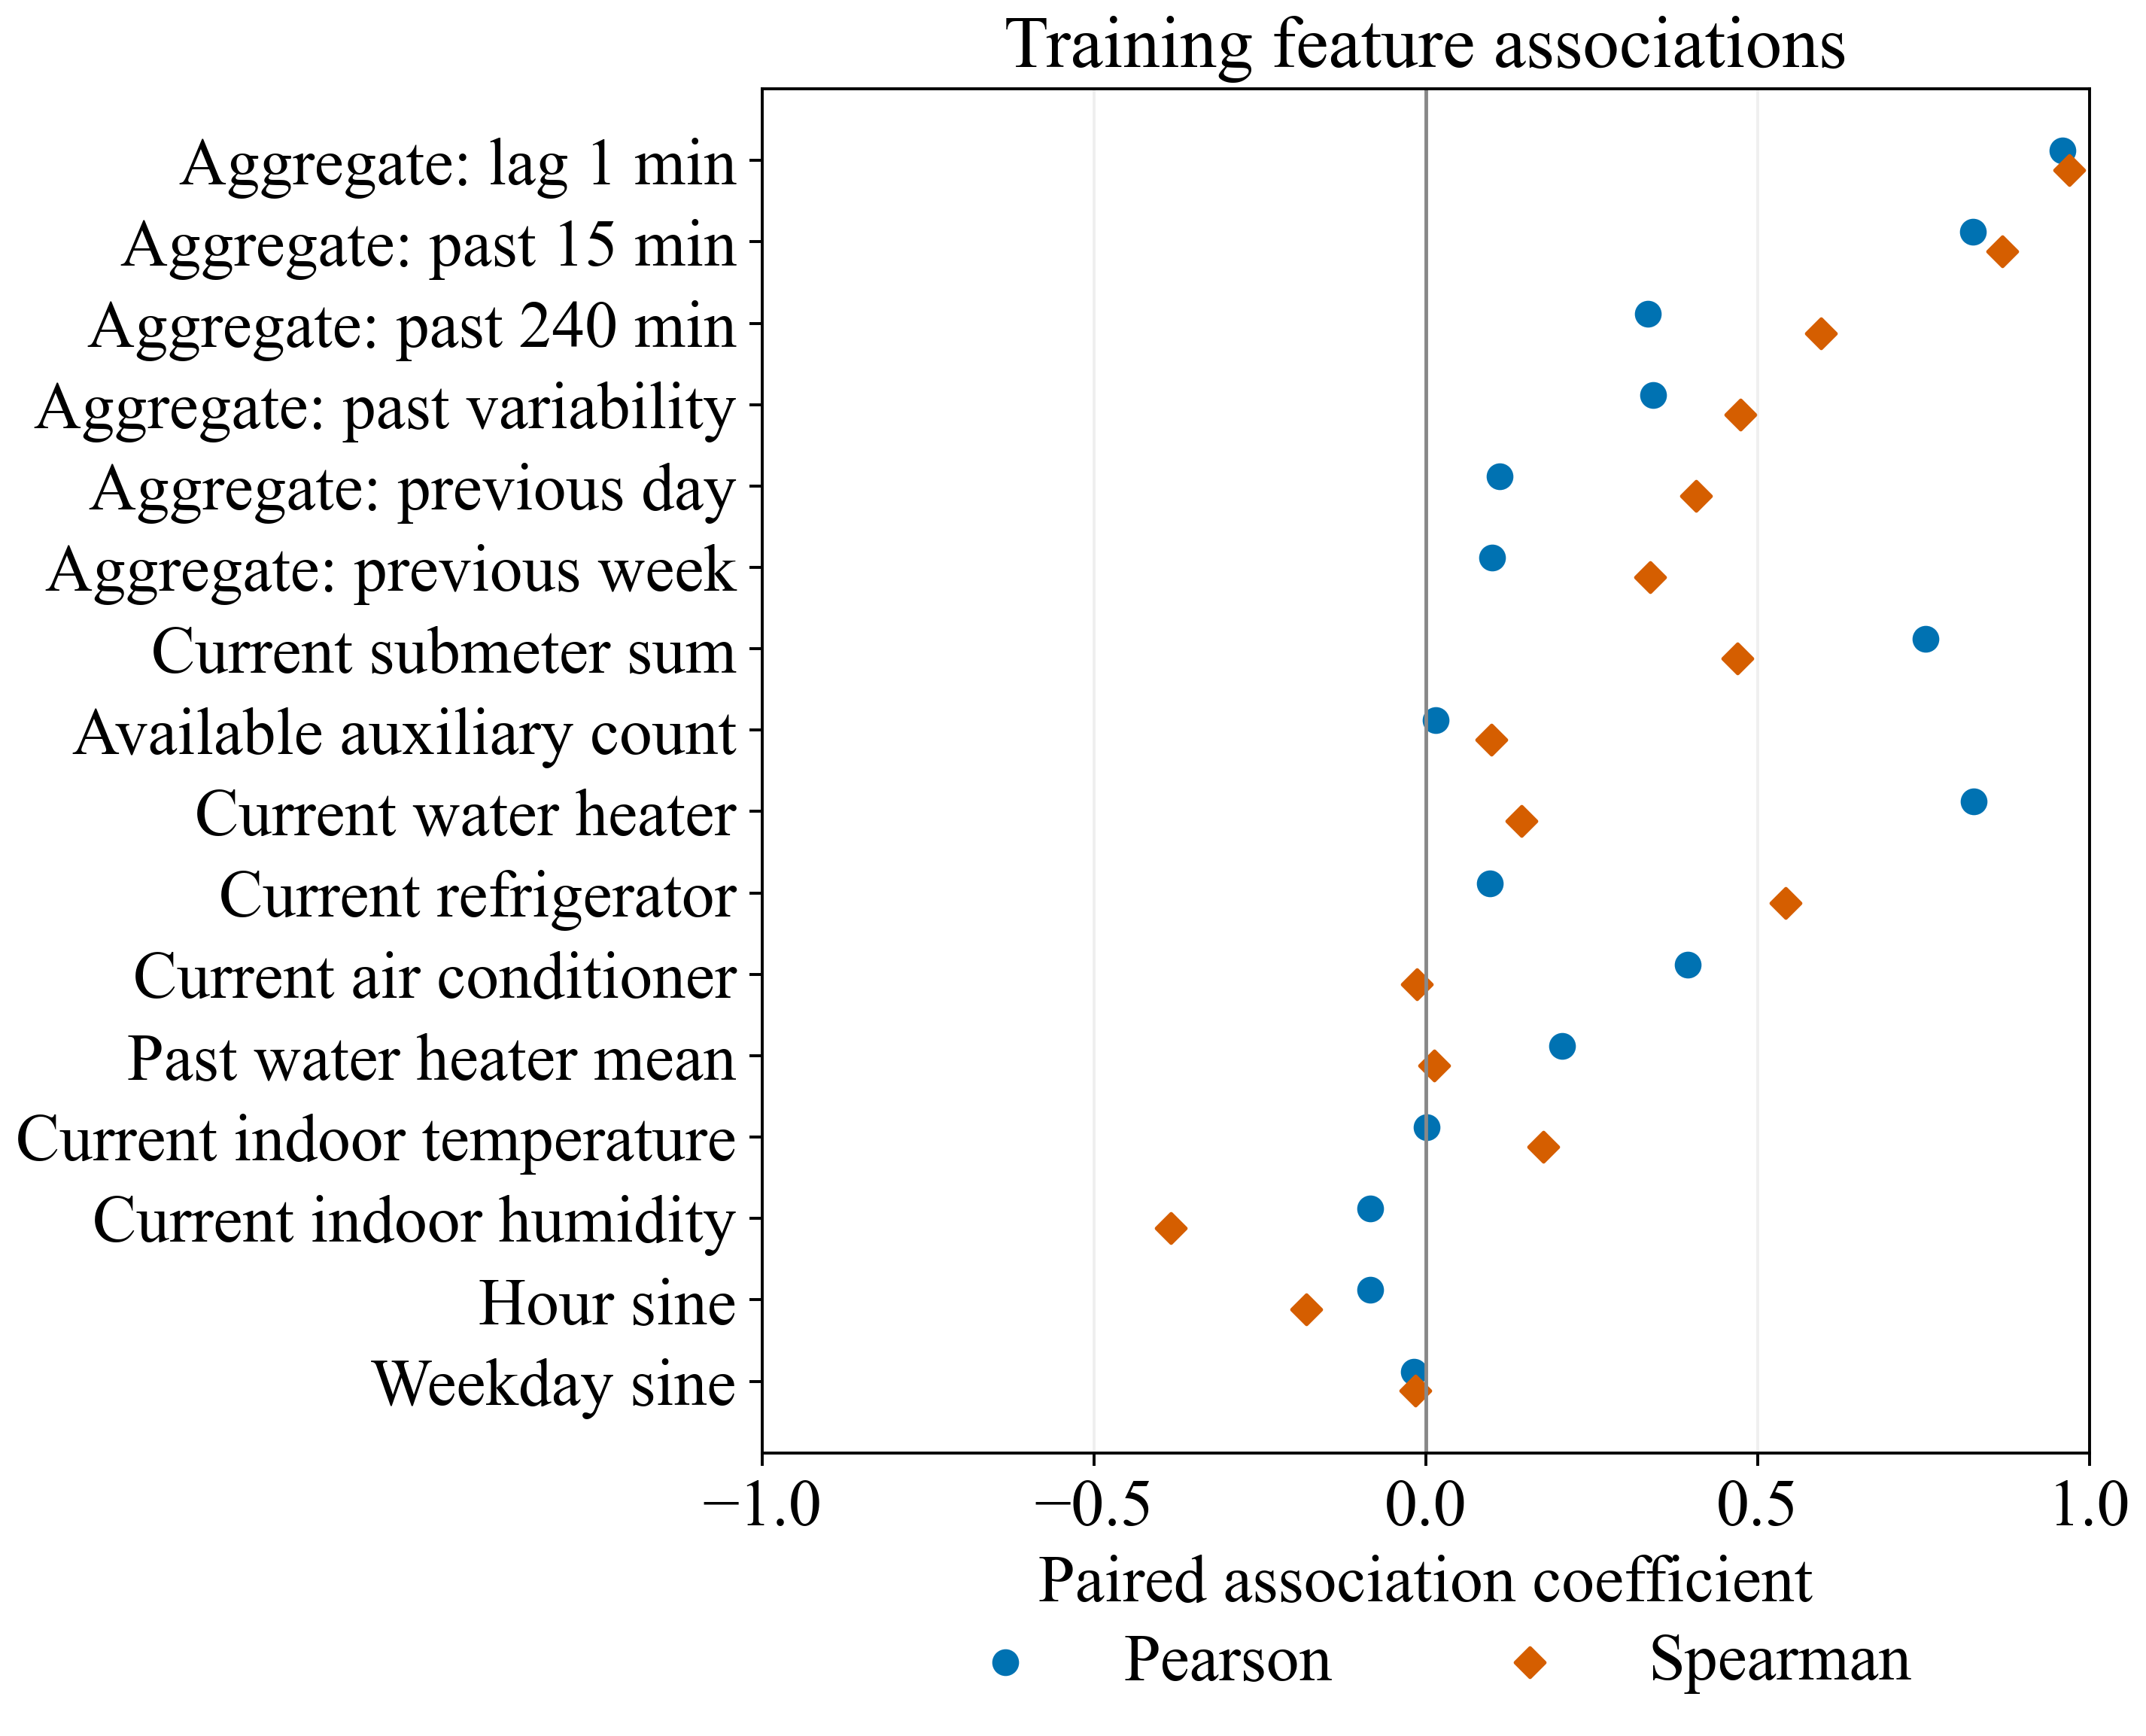

In [9]:
# Dependence is estimated solely from the first-fold training sample.
from scipy.stats import pearsonr, spearmanr
from sklearn.feature_selection import mutual_info_regression
feature_labels={"aggregate_lag_1":"Aggregate: lag 1 min","aggregate_mean_15":"Aggregate: past 15 min",
    "aggregate_mean_240":"Aggregate: past 240 min","aggregate_std_240":"Aggregate: past variability",
    "aggregate_lag_1440":"Aggregate: previous day","aggregate_lag_10080":"Aggregate: previous week",
    "current_aux_sum":"Current submeter sum","current_aux_count":"Available auxiliary count",
    "current_water_heater_sum":"Current water heater","current_refrigerator_freezer_sum":"Current refrigerator",
    "current_HVAC_air_conditioner_sum":"Current air conditioner","past_water_heater_mean_240":"Past water heater mean",
    "current_indoor_temperature":"Current indoor temperature","current_indoor_humidity":"Current indoor humidity",
    "hour_sin":"Hour sine","weekday_sin":"Weekday sine"}
dependence_rows=[]
rng=np.random.default_rng(17)
for name,label in feature_labels.items():
    pair=analysis[[name,"target","house","timestamp"]].dropna().copy()
    x,y=pair[name].to_numpy(),pair.target.to_numpy()
    discrete=name in {"current_aux_count","weekday_sin"}
    enough=len(pair)>=100 and np.unique(x).size>=3
    if enough:
        mi=mutual_info_regression(x[:,None],y,discrete_features=discrete,n_neighbors=5,random_state=17)[0]
        null=mutual_info_regression(x[:,None],rng.permutation(y),discrete_features=discrete,n_neighbors=5,random_state=17)[0]
        pair["hour"]=pair.timestamp.dt.hour
        centered=pair[[name,"target"]]-pair.groupby(["house","hour"])[[name,"target"]].transform("mean")
        conditional=centered.corr().iloc[0,1]
        r,rho=pearsonr(x,y).statistic,spearmanr(x,y).statistic
    else:r=rho=mi=null=conditional=np.nan
    dependence_rows.append({"Feature":label,"Code":name,"Paired n":len(pair),"Pearson r":r,"Spearman rho":rho,
                            "MI (nat)":mi,"Shuffled MI (nat)":null,"House/hour centered r":conditional})
dependence=pd.DataFrame(dependence_rows)
table(dependence.drop(columns="Code"),"training_feature_dependence","Table 6. Training-only feature dependence; paired sample size varies with availability.")
fig,ax=plt.subplots(figsize=(9,7))
pos=np.arange(len(dependence))
ax.scatter(dependence["Pearson r"],pos-.12,label="Pearson",color="#0072B2",s=40)
ax.scatter(dependence["Spearman rho"],pos+.12,label="Spearman",color="#D55E00",marker="D",s=32)
ax.set_yticks(pos,labels=dependence.Feature)
ax.invert_yaxis();ax.set_xlim(-1,1);ax.axvline(0,color="#888888",linewidth=1)
ax.set_xlabel("Paired association coefficient")
ax.set_title("Training feature associations")
ax.grid(axis="x",alpha=.2)
ax.legend(loc="lower center",bbox_to_anchor=(.5,-.22),ncol=2,frameon=False)
fig.subplots_adjust(left=.42,right=.98,top=.92,bottom=.18)
save_figure(fig,"08_training_feature_associations")

**Interpretation.** Lag-1 aggregate values have the strongest associations. Current water heating has high Pearson correlation but low pooled rank correlation, illustrating sensitivity to intermittent large loads and heterogeneous houses. Environment estimates have much smaller observed-pair support and should not be treated as equally precise; all coefficients and support counts are computed above. The shuffled MI values are reference noise levels, not p-values.

## 7. Conditional curves and within-house structure

Quantile bins and conditional centering are fitted on training observations only. The curves below show conditional mean target against current submeter sum after within-house centering; they are descriptive and include unequal naturally observed sensor sets. A sum does not identify unmonitored load. Separate household associations guard against interpreting between-house differences as an individual-house mechanism.

House,Aggregate: lag 1 min,Aggregate: past 240 min,Current refrigerator,Current submeter sum,Current water heater
1,0.9591,0.5441,0.5276,0.7191,0.7746
2,0.9716,0.5382,0.6134,0.6265,0.0372
3,0.9355,0.6445,0.4784,0.5700,0.2838
4,0.9465,0.3648,0.5985,0.3958,0.0557
5,0.9511,0.4142,0.4906,0.3124,0.8036
6,0.9745,0.6358,0.4688,0.5768,0.2654
7,0.9335,0.4110,0.4425,0.2726,0.0589
8,0.9759,0.5663,0.4224,0.4942,Unavailable
9,0.9775,0.5116,0.4889,0.4302,0.1570
10,0.9575,0.4834,0.5183,0.4441,0.0560


input_mean,target_mean,target_q25,target_q75,n
−0.1718,−0.1602,−0.3805,−0.2022,2480
−0.1427,−0.1368,−0.2141,−0.1520,2478
−0.1323,−0.1405,−0.2412,−0.1653,2754
−0.1136,−0.1169,−0.2235,−0.1000,2683
−0.1026,−0.0964,−0.2126,−0.1395,1999
−0.0858,−0.1093,−0.2192,−0.1015,2479
−0.0666,−0.0837,−0.1888,−0.1280,2550
−0.0547,−0.0628,−0.1359,−0.0829,2562
−0.0426,−0.0743,−0.2877,−0.1580,2324
−0.0223,−0.0345,−0.1662,−0.0567,2478


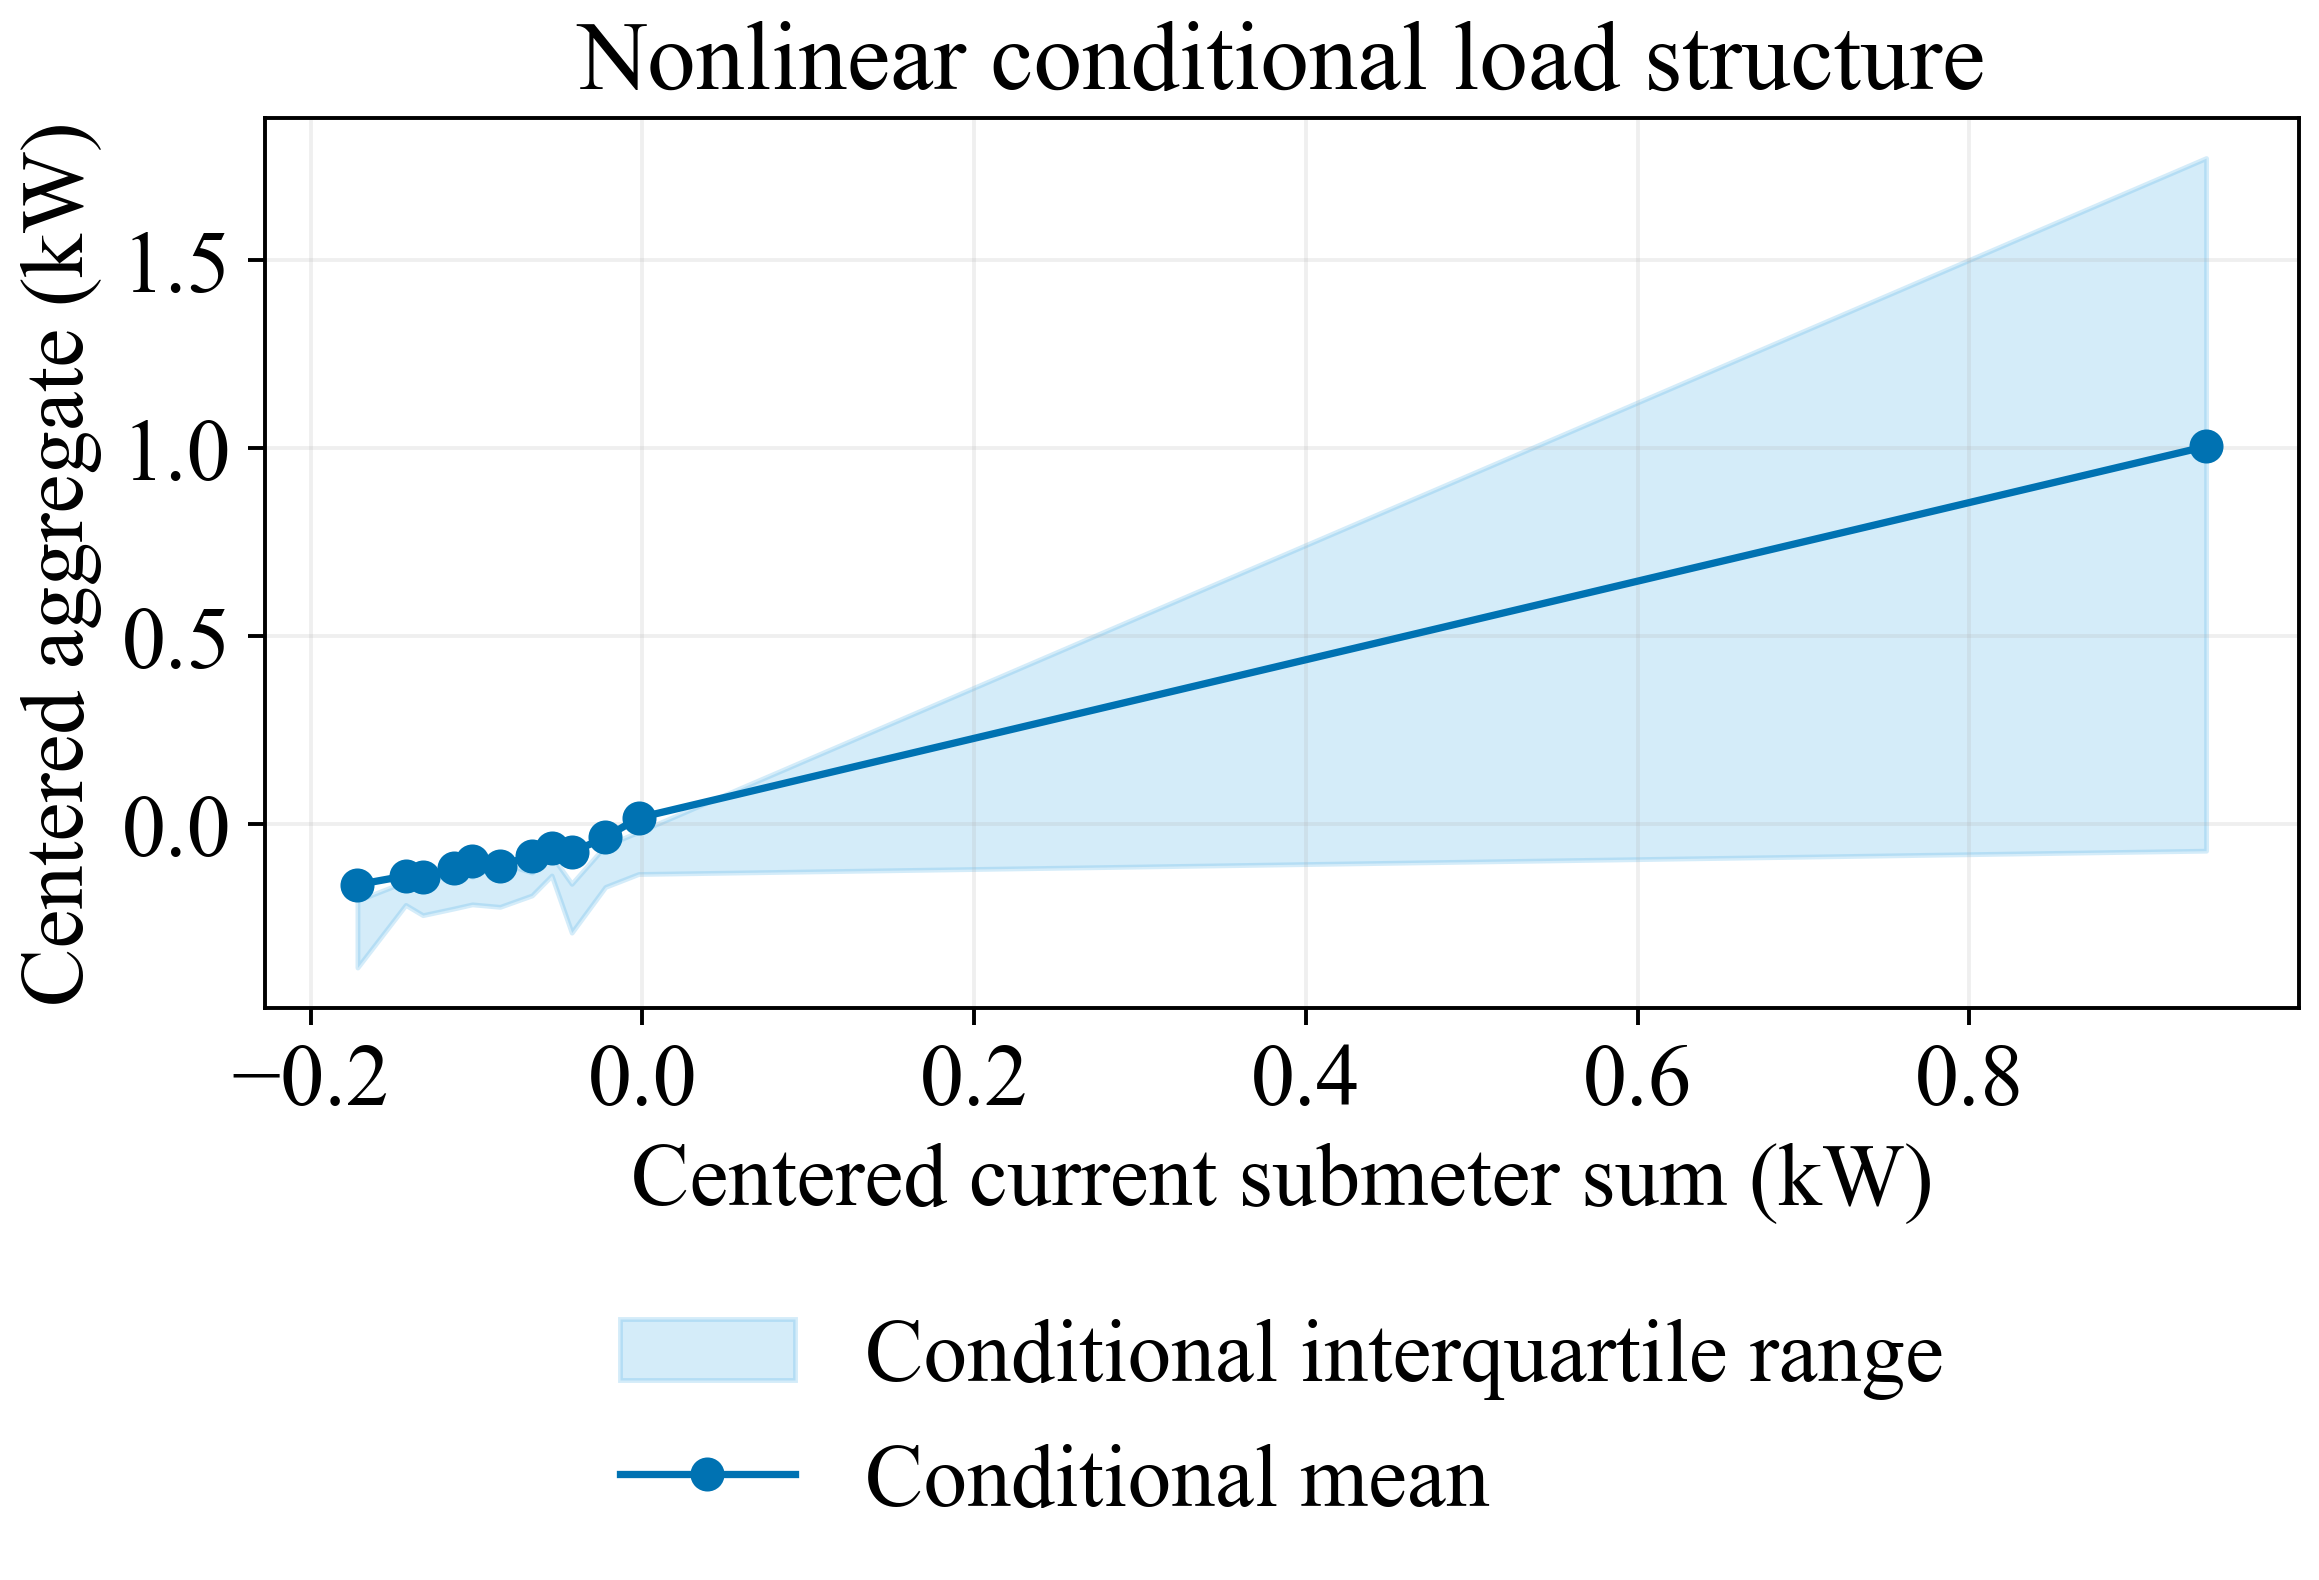

In [10]:
# Nonlinear conditional curves and correlations retain household context.
within_rows=[]
selected=["aggregate_lag_1","aggregate_mean_240","current_aux_sum","current_water_heater_sum","current_refrigerator_freezer_sum"]
for house,group in analysis.groupby("house"):
    for name in selected:
        pair=group[[name,"target"]].dropna()
        within_rows.append({"House":house,"Feature":feature_labels[name],"Paired n":len(pair),
                           "Spearman rho":pair.corr(method="spearman").iloc[0,1] if len(pair)>=30 and pair[name].nunique()>1 else np.nan})
within=pd.DataFrame(within_rows)
within_matrix=within.pivot(index="House",columns="Feature",values="Spearman rho")
table(within_matrix.reset_index(),"within_house_rank_dependence","Table 7. Within-house training Spearman associations, without imputed sensor values.")
within.to_csv(TABLES / "within_house_rank_dependence_counts.csv",index=False)
curve=analysis[["house","current_aux_sum","target"]].dropna().copy()
for column in ["current_aux_sum","target"]:
    curve[column+"_centered"]=curve[column]-curve.groupby("house")[column].transform("mean")
curve["bin"]=pd.qcut(curve.current_aux_sum_centered,q=12,duplicates="drop")
nonlinear=curve.groupby("bin",observed=True).agg(
    input_mean=("current_aux_sum_centered","mean"),target_mean=("target_centered","mean"),
    target_q25=("target_centered",lambda s:s.quantile(.25)),target_q75=("target_centered",lambda s:s.quantile(.75)),n=("target","size")).reset_index(drop=True)
table(nonlinear,"conditional_submeter_curve","Table 8. Within-house-centered submeter/aggregate relationship in training quantile bins.")
fig,ax=plt.subplots(figsize=(7,4.8))
ax.fill_between(nonlinear.input_mean,nonlinear.target_q25,nonlinear.target_q75,alpha=.25,color="#56B4E9",label="Conditional interquartile range")
ax.plot(nonlinear.input_mean,nonlinear.target_mean,marker="o",color="#0072B2",label="Conditional mean")
ax.set_xlabel("Centered current submeter sum (kW)")
ax.set_ylabel("Centered aggregate (kW)")
ax.set_title("Nonlinear conditional load structure")
ax.grid(alpha=.2)
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.26),frameon=False)
fig.subplots_adjust(left=.15,right=.98,top=.9,bottom=.37)
save_figure(fig,"09_conditional_submeter_curve")

**Interpretation.** Current submeter-sum rank association varies strongly across houses, with the lowest value in House 7 and the highest in House 1. The final quantile bin has a broad target IQR and dominates the upper-load mean. These curves describe available sensor sets and do not establish that submeter sum is sufficient to reconstruct unmonitored load.

## 8. Redundancy and train-fitted projection

Variance inflation factors are diagnostic for a small prespecified continuous feature panel after training-median imputation. They are not a universal threshold for deleting useful nonlinear inputs. Ridge and regularized controls will address collinearity explicitly. PCA is fitted only on standardized first-fold training data and is used for structure visualization, not automatic model input reduction. House identity colours points for interpretation but is absent from the fitted feature matrix.

Feature,VIF
Aggregate: lag 1 min,4.6472
Aggregate: past 15 min,3.8505
Aggregate: past 240 min,4.7006
Aggregate: past variability,4.5699
Current submeter sum,11.2820
Available auxiliary count,1.0408
Current water heater,8.4870
Current refrigerator,1.0993
Current air conditioner,2.5257
Hour sine,1.0461


Explained variance threshold,Components
0.80,29
0.90,48
0.95,63


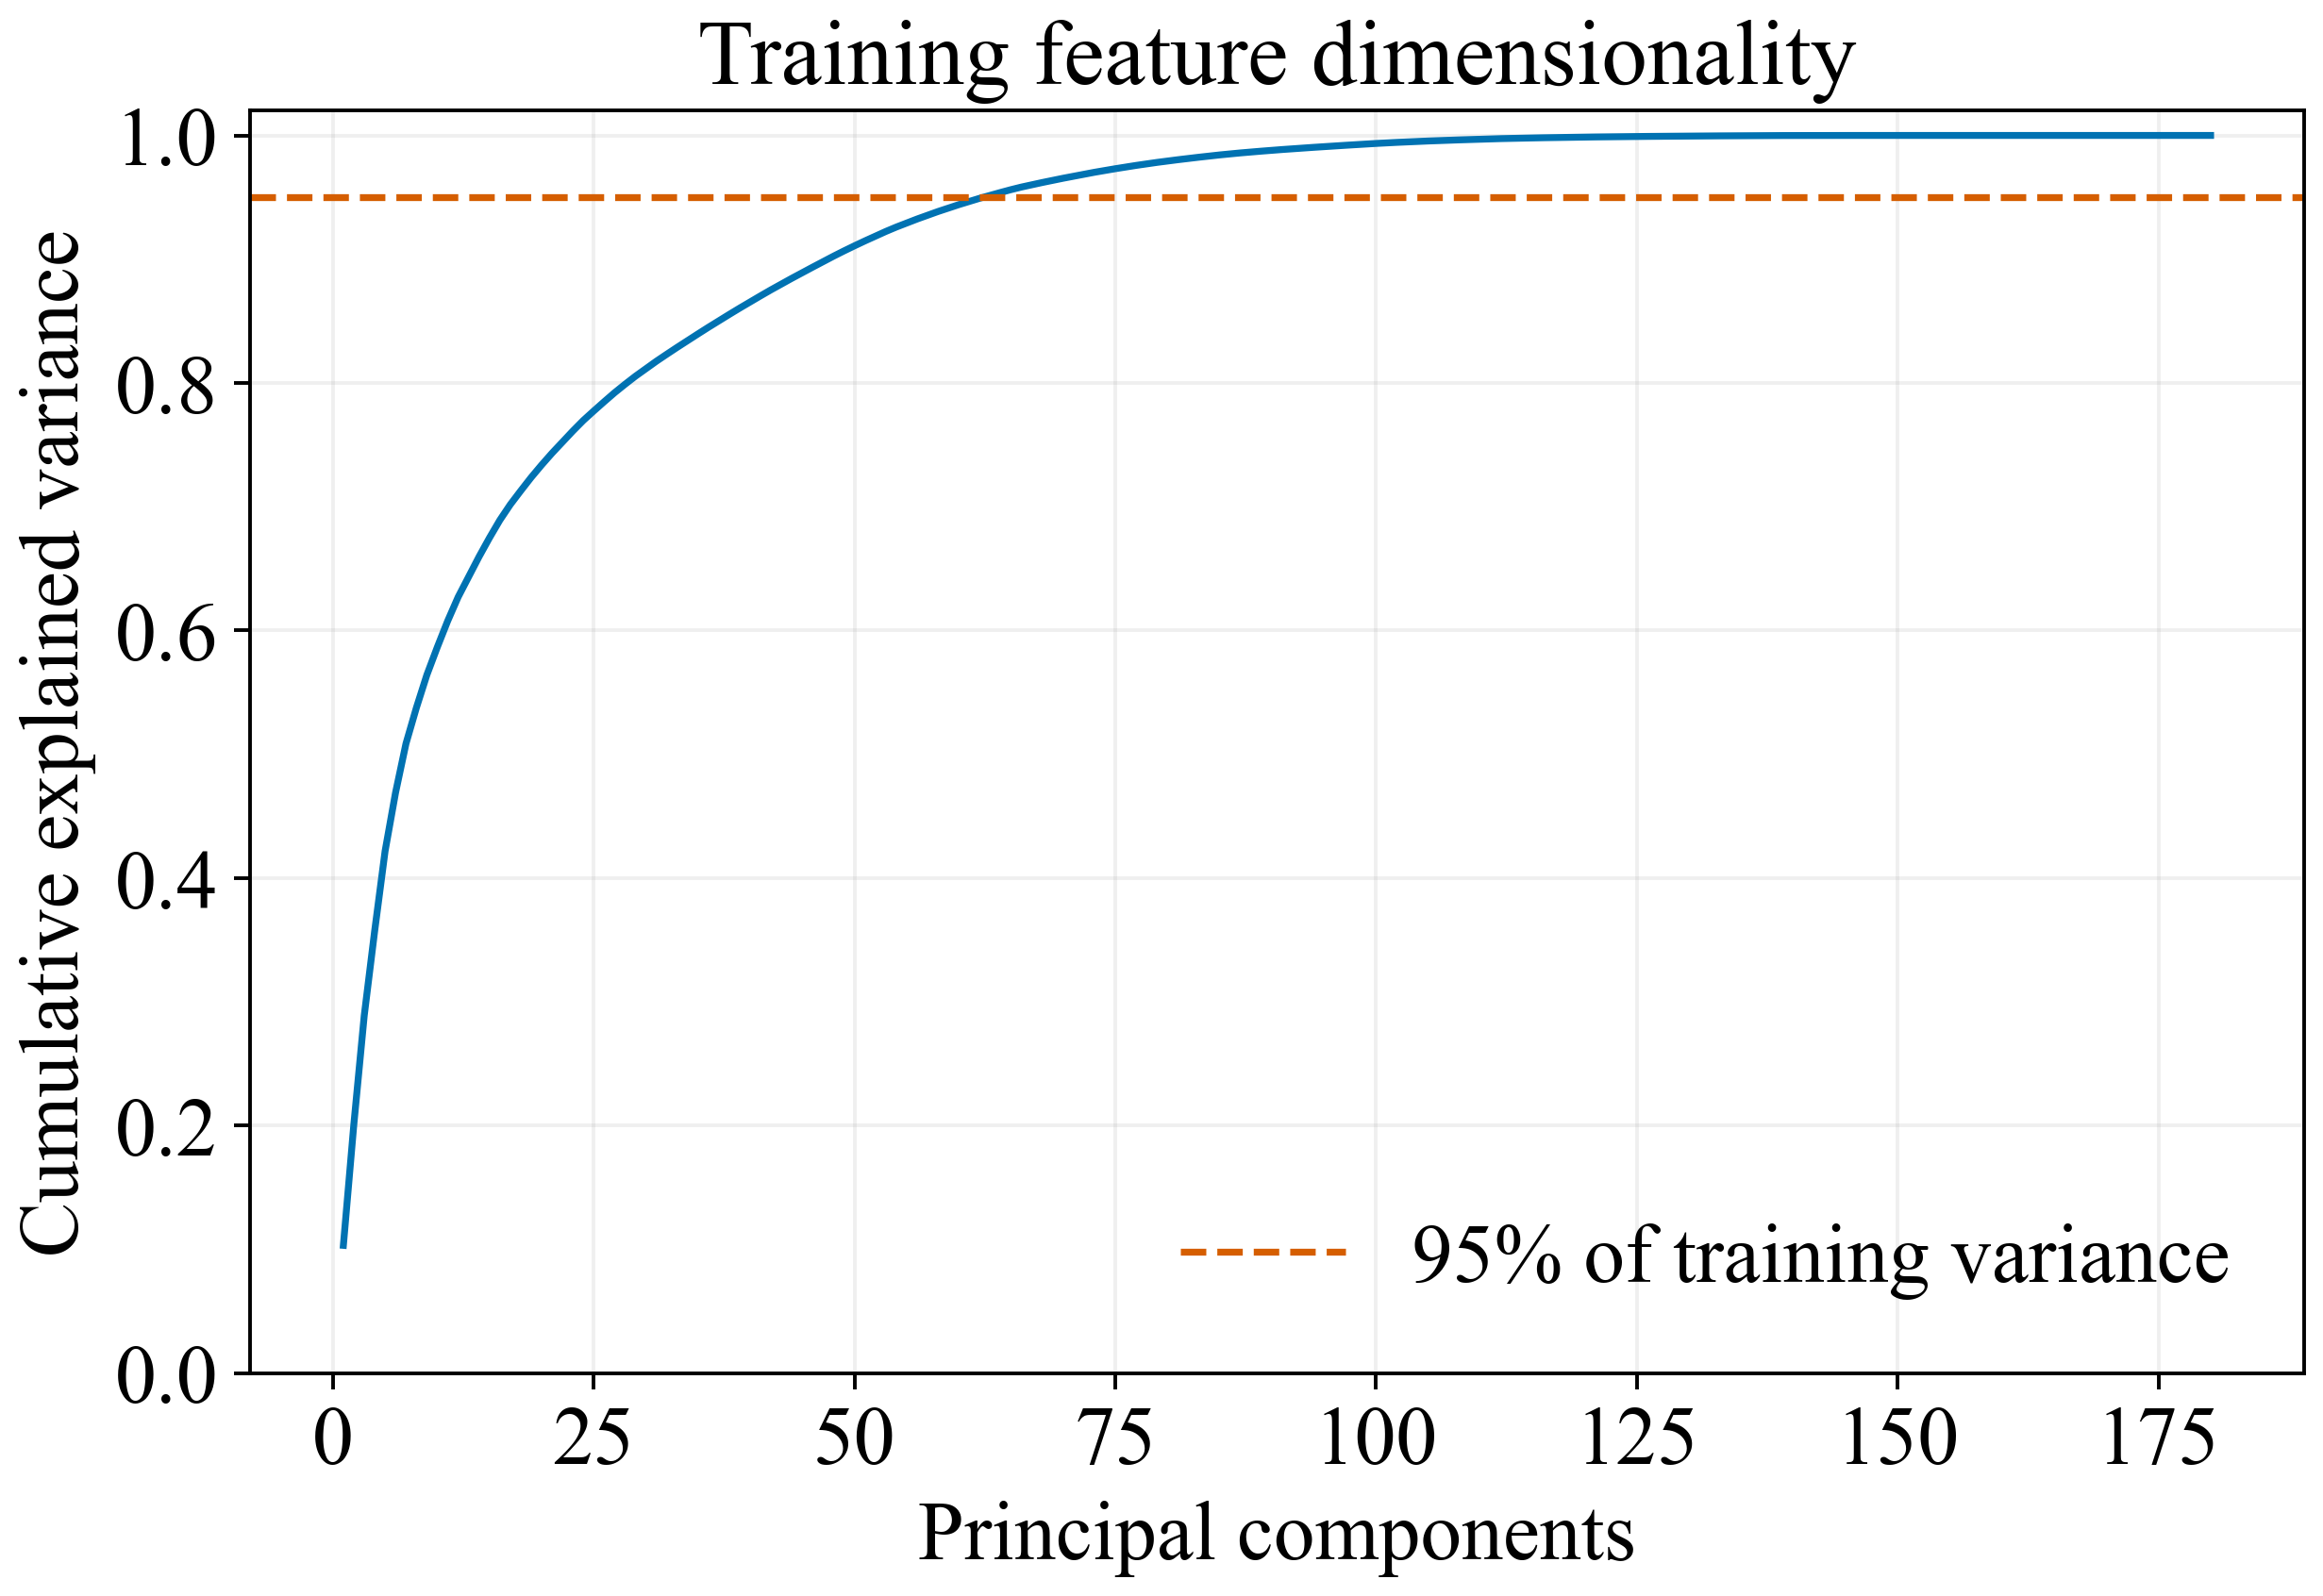

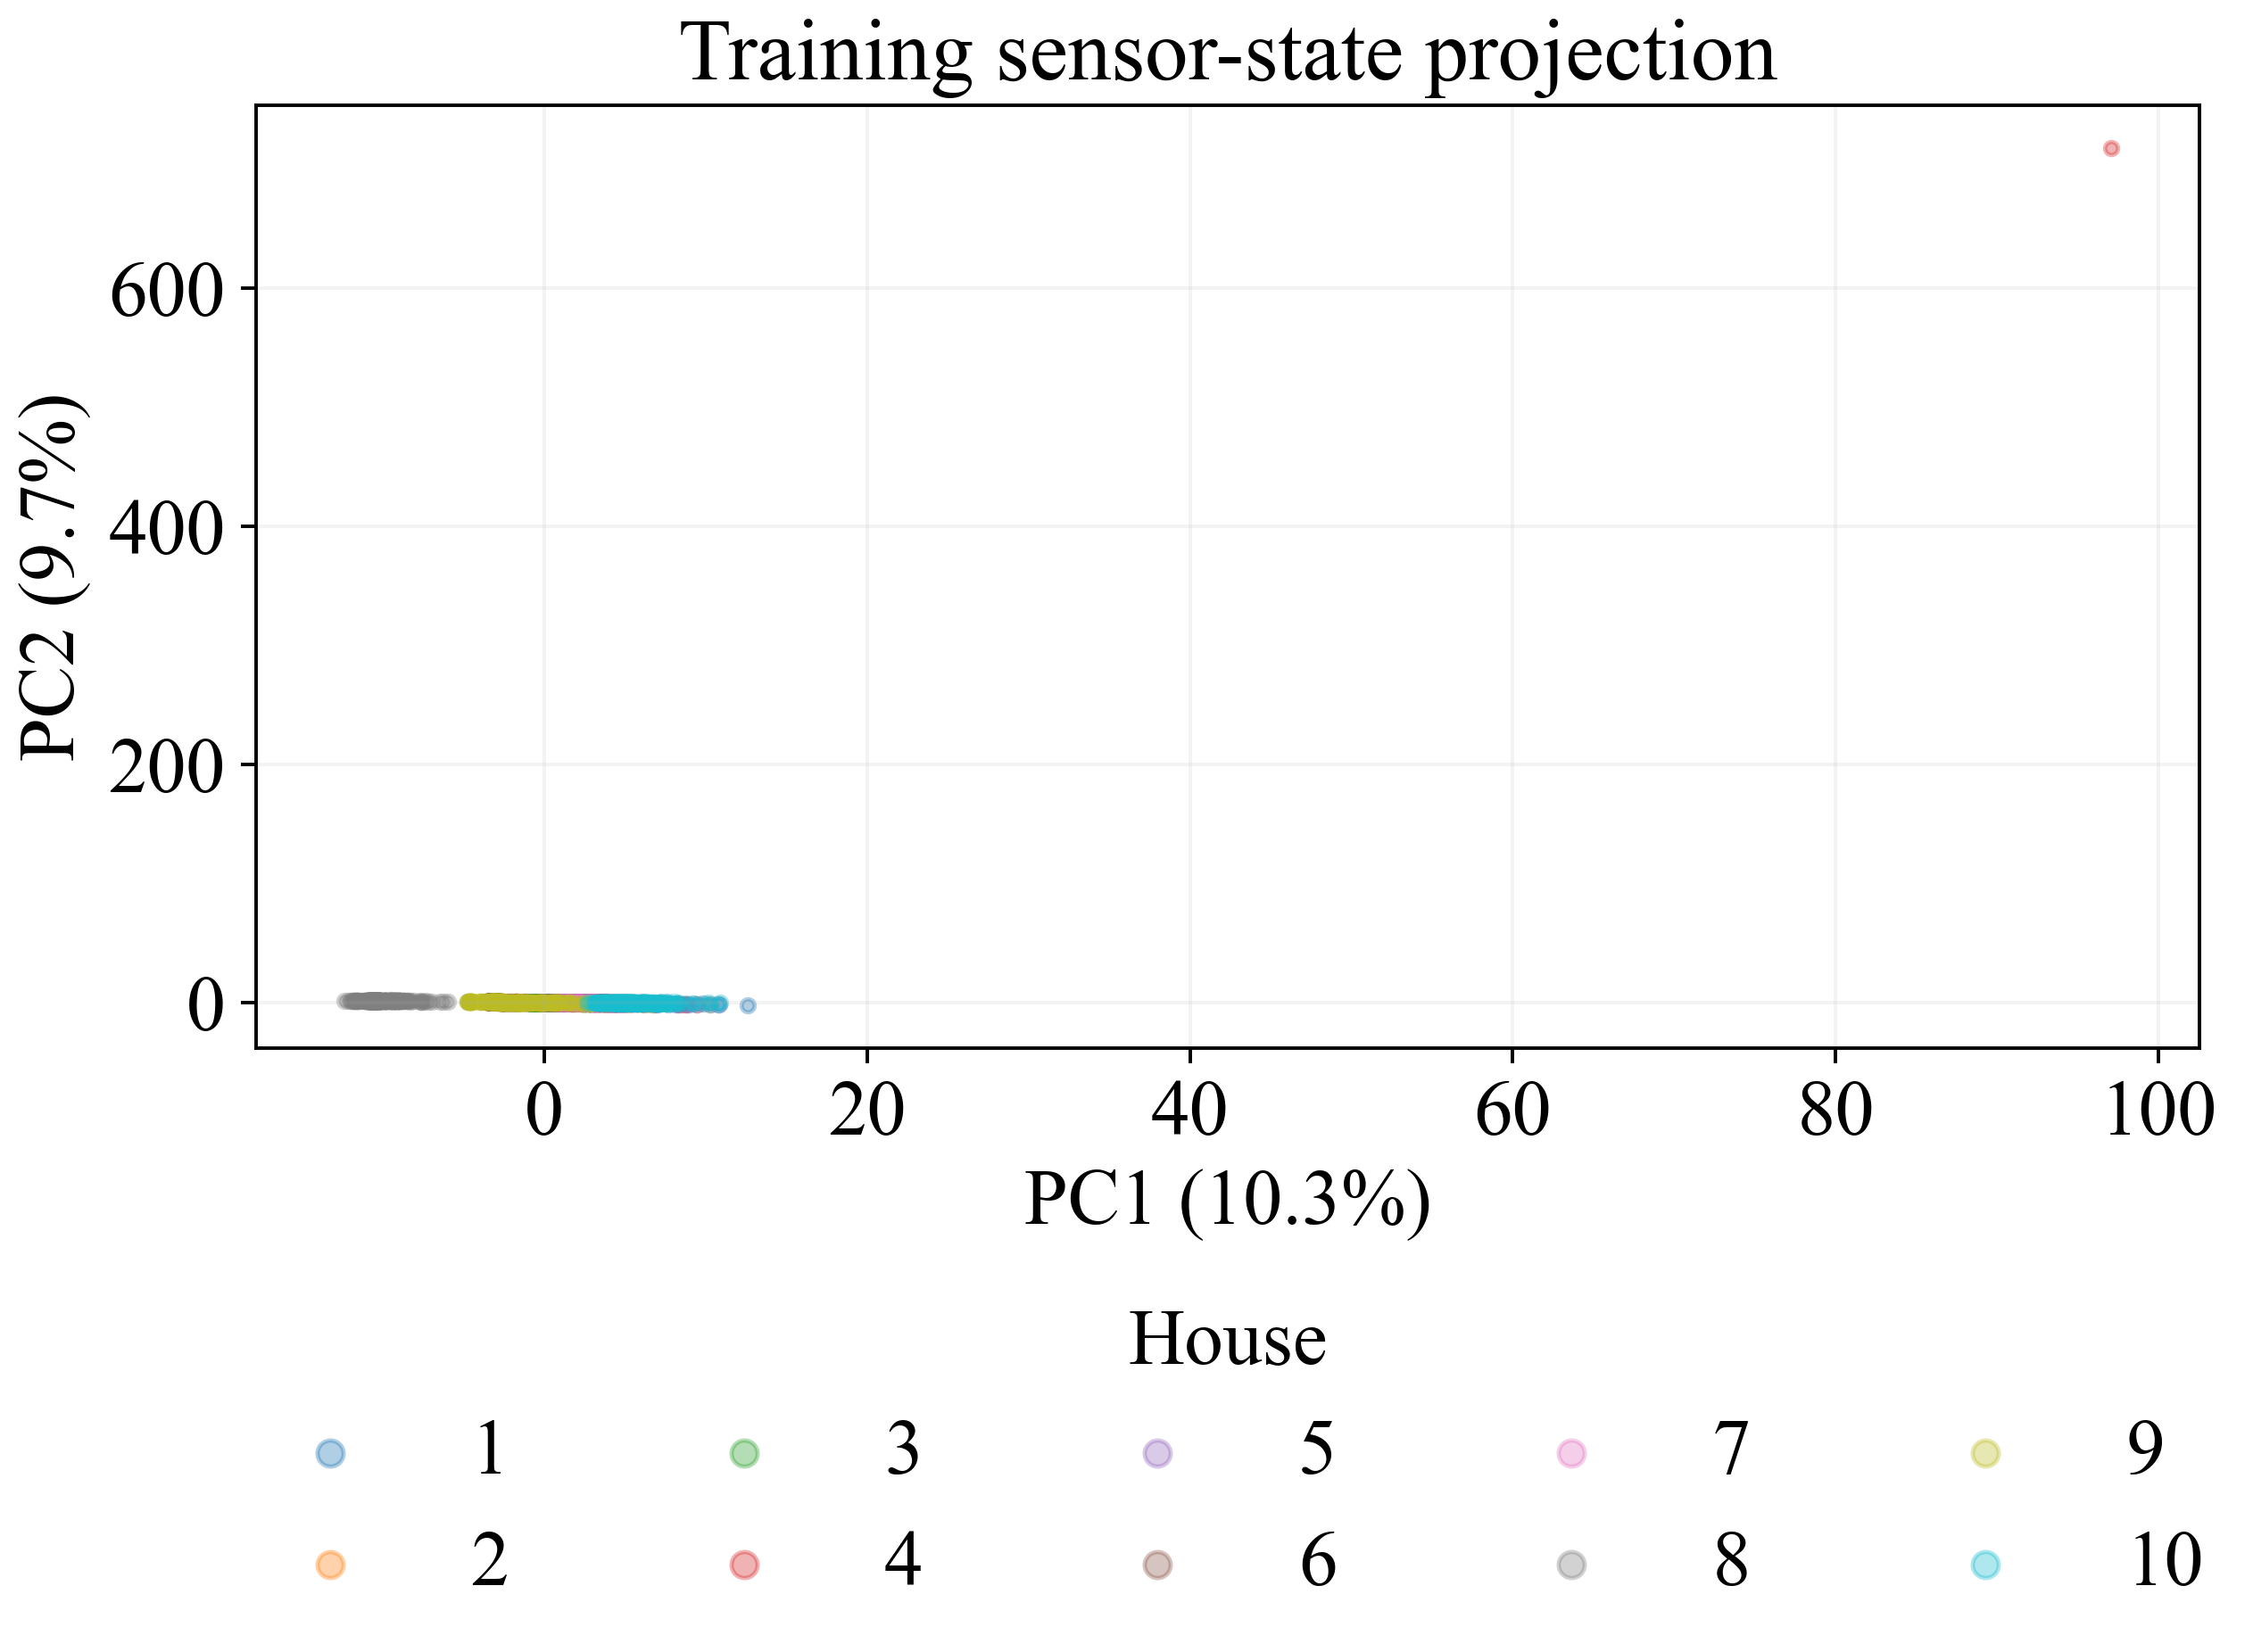

In [11]:
# VIF and PCA are fitted on training inputs; no validation rows enter these calculations.
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
vif_names=["aggregate_lag_1","aggregate_mean_15","aggregate_mean_240","aggregate_std_240",
           "current_aux_sum","current_aux_count","current_water_heater_sum","current_refrigerator_freezer_sum",
           "current_HVAC_air_conditioner_sum","hour_sin","hour_cos"]
vif_raw=analysis[vif_names].fillna(pd.Series(preprocessors[1].state["median"]))
vif_x=StandardScaler().fit_transform(vif_raw)
vif_rows=[]
for j,name in enumerate(vif_names):
    others=np.column_stack([np.ones(len(vif_x)),np.delete(vif_x,j,axis=1)])
    fitted=others@np.linalg.lstsq(others,vif_x[:,j],rcond=None)[0]
    r2=1-np.sum((vif_x[:,j]-fitted)**2)/np.sum(vif_x[:,j]**2)
    vif_rows.append({"Feature":feature_labels.get(name,name),"VIF":1/(1-r2) if 1-r2>1e-10 else np.inf})
vif=pd.DataFrame(vif_rows)
table(vif,"training_vif","Table 9. Training-only VIF for the prespecified feature panel.")
x_analysis=analysis[preprocessors[1].state["input_columns"]]
z=preprocessors[1].transform(x_analysis)
pca_scaler=StandardScaler().fit(z)
pca=PCA(svd_solver="full").fit(pca_scaler.transform(z))
scores=pca.transform(pca_scaler.transform(z))
cumulative=np.cumsum(pca.explained_variance_ratio_)
pca_summary=pd.DataFrame({"Explained variance threshold":[.8,.9,.95],
                          "Components":[int(np.searchsorted(cumulative,q)+1) for q in [.8,.9,.95]]})
table(pca_summary,"training_pca_dimension","Table 10. Components required to explain training standardized feature variance.",precision=2)
np.savez_compressed(PREP / "fold_1_diagnostic_pca.npz",mean=pca_scaler.mean_,scale=pca_scaler.scale_,
    components=pca.components_,pca_mean=pca.mean_,explained_variance_ratio=pca.explained_variance_ratio_)
fig,ax=plt.subplots(figsize=(7,4.8),layout="constrained")
ax.plot(np.arange(1,len(cumulative)+1),cumulative,color="#0072B2")
ax.axhline(.95,color="#D55E00",linestyle="--",label="95% of training variance")
ax.set_xlabel("Principal components");ax.set_ylabel("Cumulative explained variance")
ax.set_title("Training feature dimensionality")
ax.set_ylim(0,1.02);ax.grid(alpha=.2);ax.legend(frameon=False,loc="lower right")
save_figure(fig,"10_training_pca_variance")
fig,ax=plt.subplots(figsize=(7.5,5.3))
colours=mpl.colormaps["tab10"]
for house in range(1,11):
    idx=np.flatnonzero(analysis.house.eq(house).to_numpy())[::10]
    ax.scatter(scores[idx,0],scores[idx,1],s=9,alpha=.35,color=colours(house-1),label=str(house))
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("Training sensor-state projection")
ax.legend(title="House",loc="upper center",bbox_to_anchor=(.5,-.2),ncol=5,frameon=False,markerscale=2)
ax.grid(alpha=.15);fig.subplots_adjust(left=.15,right=.98,top=.9,bottom=.33)
save_figure(fig,"11_training_pca_projection")

**Interpretation.** The submeter sum and water heating show substantial linear redundancy in the computed VIF panel. The initial all-column PCA requires many components to meet the prespecified variance threshold. Its distant point is investigated immediately below before interpreting the projection.

### Projection leverage diagnostic

The full-range projection contains an unusually distant point. Before interpreting the map, inspect its standardized coordinates and the exact input columns responsible. No target or sensor reading is removed because of its position in PCA space.

In [12]:
# Identify leverage drivers before deciding how to render or interpret PCA.
standardized=pca_scaler.transform(z)
leverage_rows=[]
for idx in np.argsort(np.sum(scores[:,:2]**2,axis=1))[-3:][::-1]:
    for j in np.argsort(np.abs(standardized[idx]))[-6:][::-1]:
        name=z.columns[j]
        leverage_rows.append({"House":int(analysis.iloc[idx].house),"Timestamp":str(analysis.iloc[idx].timestamp),
            "Input":name,"Transformed value":float(z.iloc[idx,j]),"Standardized value":float(standardized[idx,j]),
            "Training sample nonzero n":int(np.count_nonzero(z.iloc[:,j].to_numpy()))})
leverage=pd.DataFrame(leverage_rows)
table(leverage,"pca_leverage_diagnostic","Table 11. Inputs responsible for the three largest distances in the first two principal components.")

House,Timestamp,Input,Transformed value,Standardized value,Training sample nonzero n
4,2022-10-11 07:23:00,missing__aggregate_mean_15,1.0000,173.2022,1
4,2022-10-11 07:23:00,missing__aggregate_min_240,1.0000,173.2022,1
4,2022-10-11 07:23:00,missing__aggregate_mean_360,1.0000,173.2022,1
4,2022-10-11 07:23:00,missing__aggregate_std_360,1.0000,173.2022,1
4,2022-10-11 07:23:00,missing__aggregate_min_360,1.0000,173.2022,1
4,2022-10-11 07:23:00,missing__aggregate_max_360,1.0000,173.2022,1
10,2023-05-13 23:05:00,missing__aggregate_std_15,1.0000,122.4704,2
10,2023-05-13 23:05:00,aggregate_coverage_60,−54.0000,−11.6738,9699
10,2023-05-13 23:05:00,aggregate_coverage_15,−13.2158,−11.0364,5389
10,2023-05-13 23:05:00,aggregate_coverage_240,−35.5000,−7.1289,14912


**Finding and correction.** The extreme House 4 point is driven by rare missingness indicators. Unit-variance scaling gives these indicators large amplitudes, quantified in the preceding diagnostic. This does not reveal an extreme physical load and is not a reason to remove the observation. The initial all-column PCA remains a documented diagnostic. The final value projection excludes the separately analyzed indicator columns; modeled inputs retain those indicators. No predictive feature selection is based on this projection.

The previous association analysis shows strong lag-1 dependence and current-submeter-sum association, with substantial differences between linear and rank measures for water heating. That motivates strong persistence controls and nonlinear comparisons, without establishing predictive superiority. Within-house association varies markedly, and the computed VIF panel supports explicit regularized controls. Conditional quantile means are sensitive to right tails and may lie outside the interquartile band; the band is not a confidence interval.


Explained variance threshold,Components
0.80,29
0.90,42
0.95,54


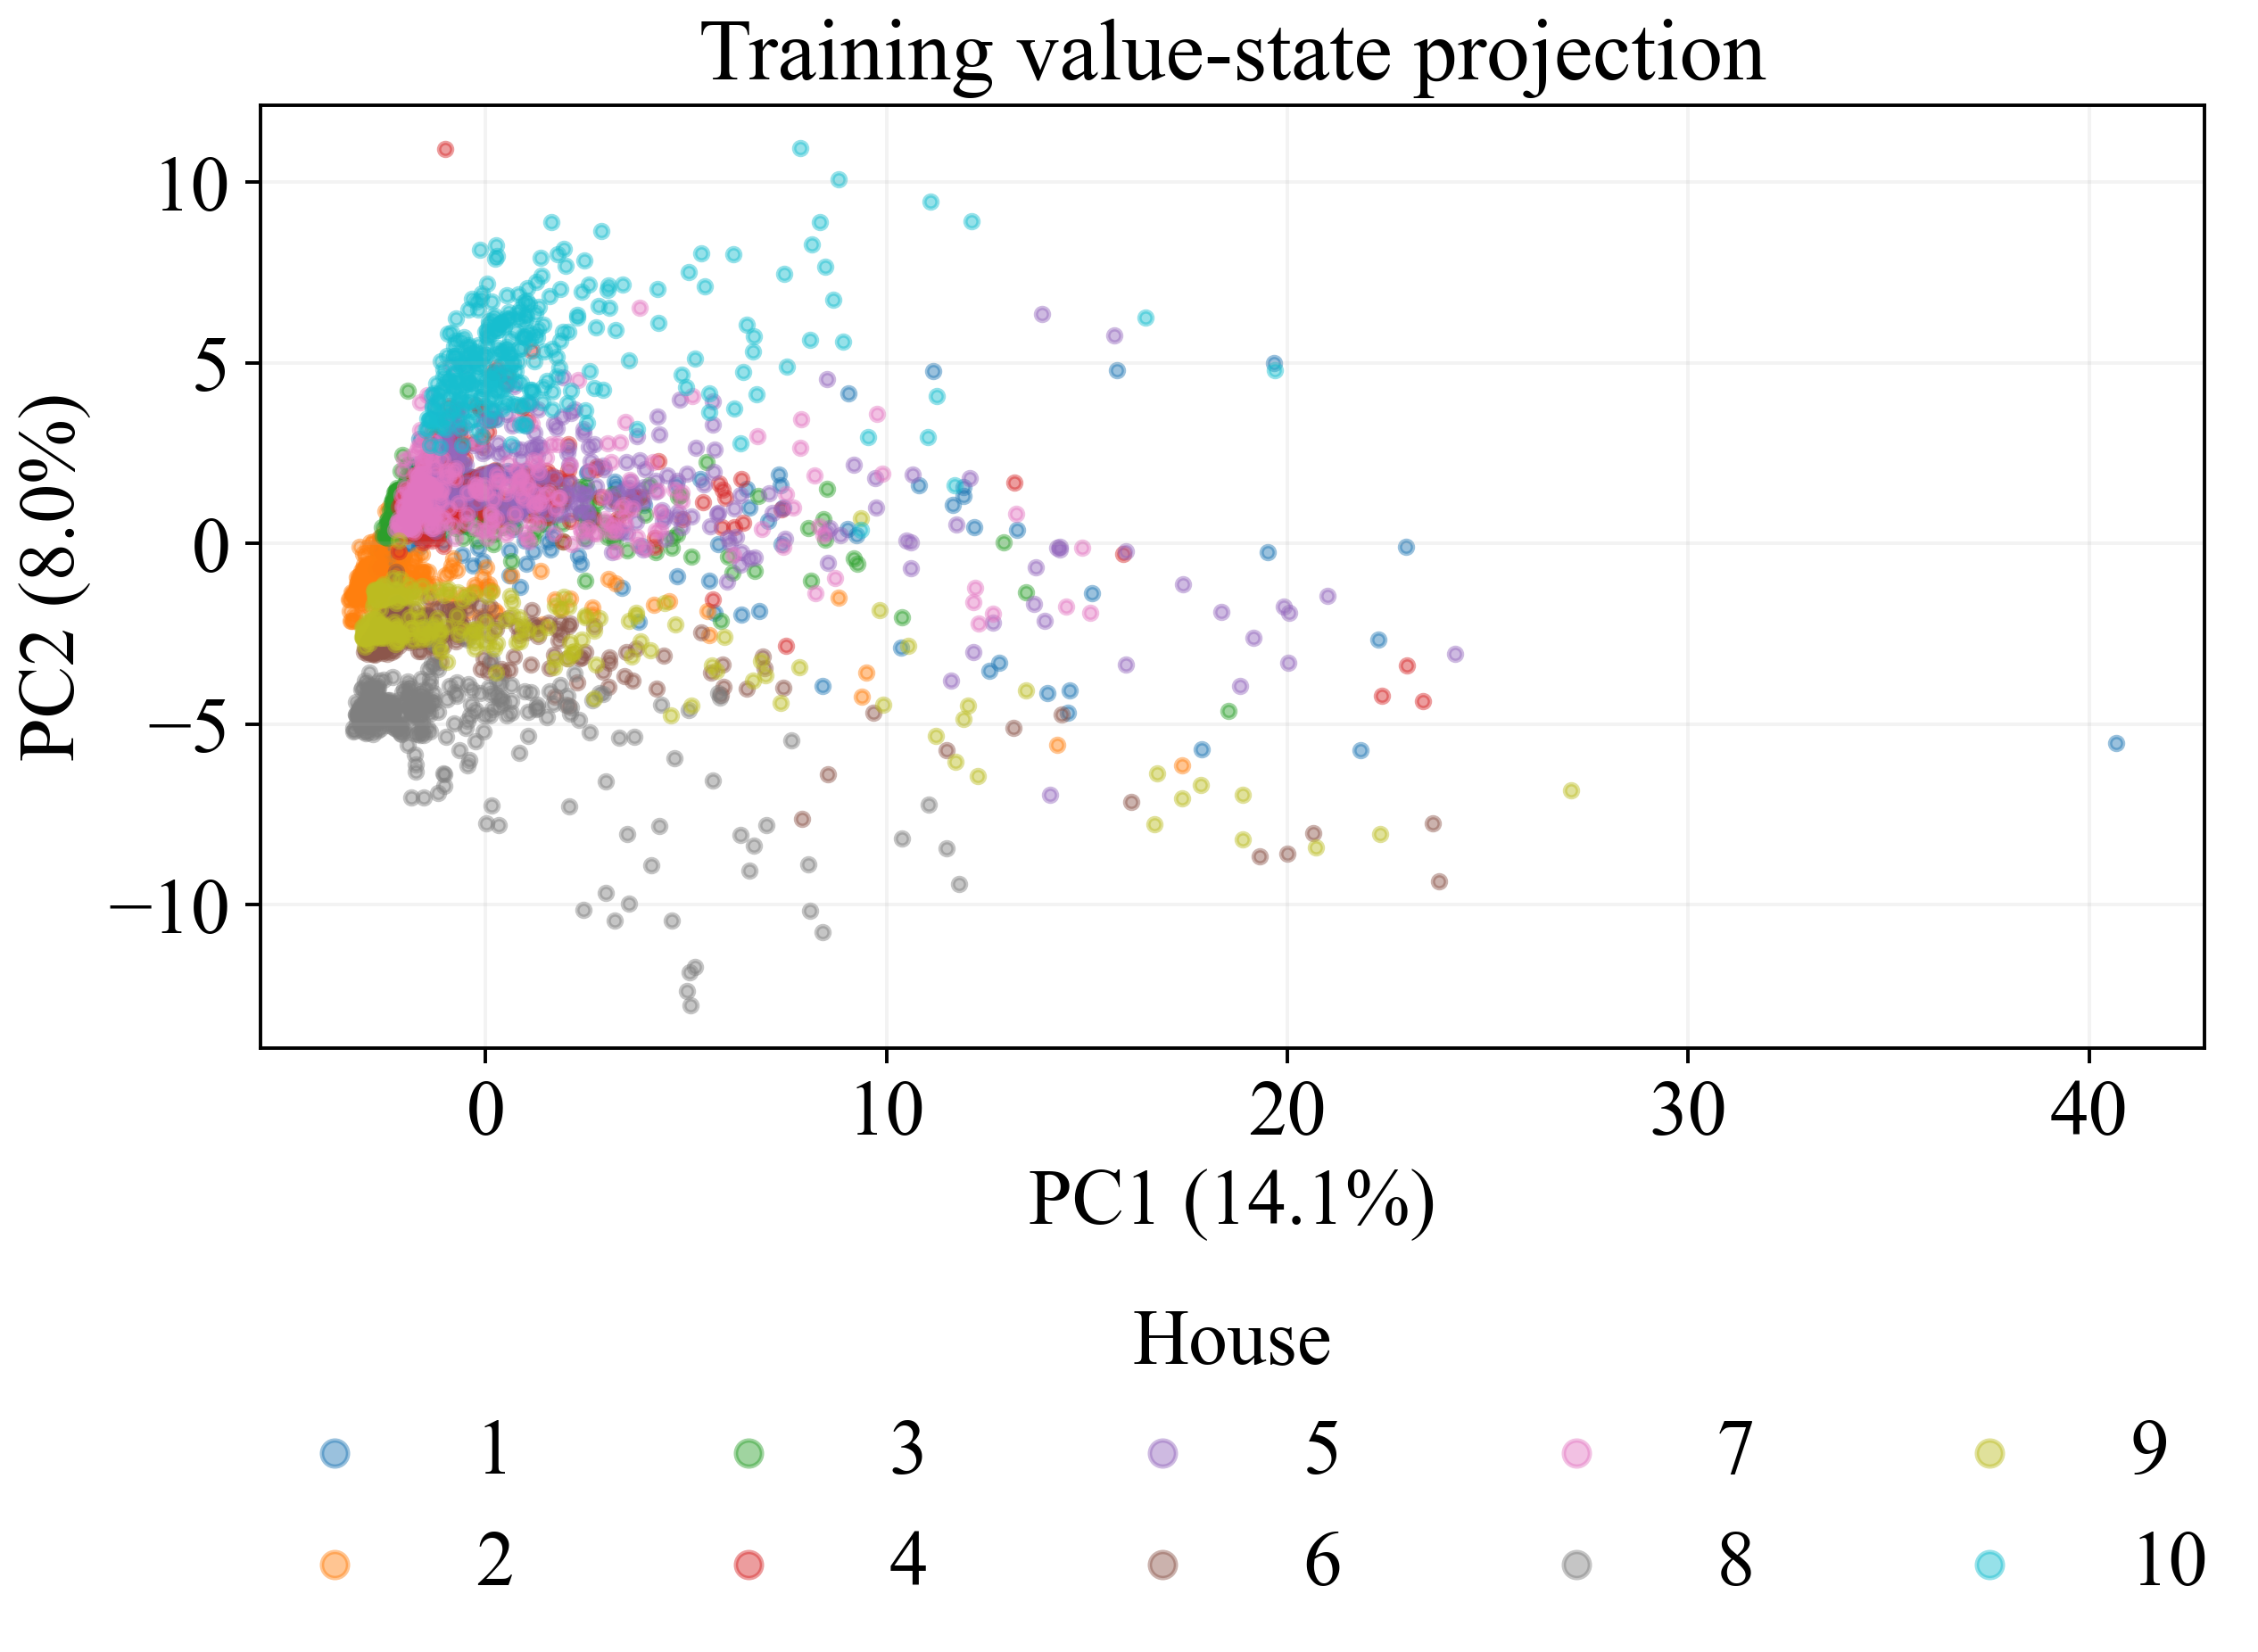

In [13]:
# A value-only projection prevents rare binary mask indicators from defining the plot.
pca_columns=preprocessors[1].state["value_columns"]
value_z=z[pca_columns]
value_scaler=StandardScaler().fit(value_z)
value_pca=PCA(svd_solver="full").fit(value_scaler.transform(value_z))
value_scores=value_pca.transform(value_scaler.transform(value_z))
value_cumulative=np.cumsum(value_pca.explained_variance_ratio_)
value_summary=pd.DataFrame({"Explained variance threshold":[.8,.9,.95],
    "Components":[int(np.searchsorted(value_cumulative,q)+1) for q in [.8,.9,.95]]})
table(value_summary,"value_only_pca_dimension","Table 12. Training value-only PCA dimensionality; binary missingness indicators are analyzed separately.",precision=2)
np.savez_compressed(PREP / "fold_1_diagnostic_value_pca.npz",mean=value_scaler.mean_,scale=value_scaler.scale_,
    components=value_pca.components_,pca_mean=value_pca.mean_,columns=np.array(pca_columns,dtype=str),
    explained_variance_ratio=value_pca.explained_variance_ratio_)
fig,ax=plt.subplots(figsize=(7.5,5.3))
for house in range(1,11):
    idx=np.flatnonzero(analysis.house.eq(house).to_numpy())[::10]
    ax.scatter(value_scores[idx,0],value_scores[idx,1],s=9,alpha=.45,color=mpl.colormaps["tab10"](house-1),label=str(house))
ax.set_xlabel(f"PC1 ({value_pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({value_pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("Training value-state projection")
ax.legend(title="House",loc="upper center",bbox_to_anchor=(.5,-.2),ncol=5,frameon=False,markerscale=2)
ax.grid(alpha=.15);fig.subplots_adjust(left=.15,right=.98,top=.9,bottom=.33)
save_figure(fig,"12_training_value_pca_projection")

**Interpretation.** With binary missingness indicators analyzed separately, the computed value-only PCA still requires many components to meet the prespecified variance threshold. The first two components show household-dependent structure but explain a limited share jointly. No predictive dimensions are dropped on this basis.

## 9. Temporal dependence without filling missing targets

Lag correlations use observed pairs on each complete one-minute training calendar. Missing targets are never interpolated. The pair-specific means in this estimator make it a missingness-aware descriptive lag correlation, not a stationary-process proof. Each pair lies inside the same training portion. Daily and weekly lags are included to assess long-range recurrence. The final bootstrap block length will additionally use development error dependence after models exist; target ACF alone is insufficient to fix it.

House,Lag (min),Observed pairs,Lag correlation
1,1,147006,0.9752
1,5,146927,0.8720
1,15,146818,0.6599
1,30,146696,0.4089
1,60,146502,0.2621
1,120,146131,0.1769
1,240,145557,0.1182
1,360,145225,0.0785
1,720,144524,0.1025
1,1440,143114,0.0656


House,Lag (min),Observed pairs,Lag correlation
2,1,68410,0.9457
2,5,68387,0.7372
2,15,68327,0.3838
2,30,68257,0.1267
2,60,68170,0.0739
2,120,67981,0.0359
2,240,67807,0.0106
2,360,67687,−0.0010
2,720,67309,0.0037
2,1440,66579,0.0217


House,Lag (min),Observed pairs,Lag correlation
3,1,143302,0.9555
3,5,143260,0.8143
3,15,143192,0.5335
3,30,143110,0.2817
3,60,142949,0.1392
3,120,142682,0.0966
3,240,142250,0.0608
3,360,141898,0.0321
3,720,140817,0.0076
3,1440,138862,0.0920


House,Lag (min),Observed pairs,Lag correlation
4,1,116711,0.9619
4,5,116612,0.8480
4,15,116598,0.5874
4,30,116573,0.3168
4,60,116531,0.0972
4,120,116471,0.0495
4,240,116345,−0.0059
4,360,116225,0.0191
4,720,115891,0.0496
4,1440,115186,0.2721


House,Lag (min),Observed pairs,Lag correlation
5,1,87599,0.9276
5,5,87558,0.7902
5,15,87508,0.5694
5,30,87449,0.3590
5,60,87330,0.1466
5,120,87088,0.0423
5,240,86608,−0.0033
5,360,86199,−0.0106
5,720,85122,0.0036
5,1440,83123,0.0881


House,Lag (min),Observed pairs,Lag correlation
6,1,38355,0.9734
6,5,38333,0.8394
6,15,38292,0.5882
6,30,38247,0.2910
6,60,38159,0.0656
6,120,37980,0.0863
6,240,37634,0.0231
6,360,37284,0.0105
6,720,36310,0.0258
6,1440,34909,0.0460


House,Lag (min),Observed pairs,Lag correlation
7,1,98212,0.9778
7,5,97867,0.8718
7,15,97759,0.5530
7,30,97624,0.1847
7,60,97324,0.0589
7,120,96923,0.0864
7,240,96680,0.1968
7,360,96362,0.0463
7,720,96032,0.1156
7,1440,95344,0.1330


House,Lag (min),Observed pairs,Lag correlation
8,1,69286,0.9095
8,5,69083,0.7496
8,15,68750,0.5409
8,30,68738,0.4162
8,60,68710,0.2853
8,120,68657,0.1570
8,240,68551,0.0228
8,360,68440,−0.0183
8,720,68089,0.0045
8,1440,67460,0.0656


House,Lag (min),Observed pairs,Lag correlation
9,1,79479,0.9780
9,5,79452,0.8778
9,15,79407,0.6857
9,30,79343,0.4475
9,60,79225,0.1462
9,120,79012,0.0449
9,240,78768,0.0087
9,360,78494,−0.0217
9,720,77731,−0.0297
9,1440,76307,0.0980


House,Lag (min),Observed pairs,Lag correlation
10,1,37682,0.9249
10,5,37450,0.7392
10,15,37815,0.4429
10,30,37862,0.1801
10,60,37661,0.0936
10,120,37569,0.0577
10,240,37397,−0.0161
10,360,37326,−0.0126
10,720,36954,−0.0173
10,1440,36376,0.0838


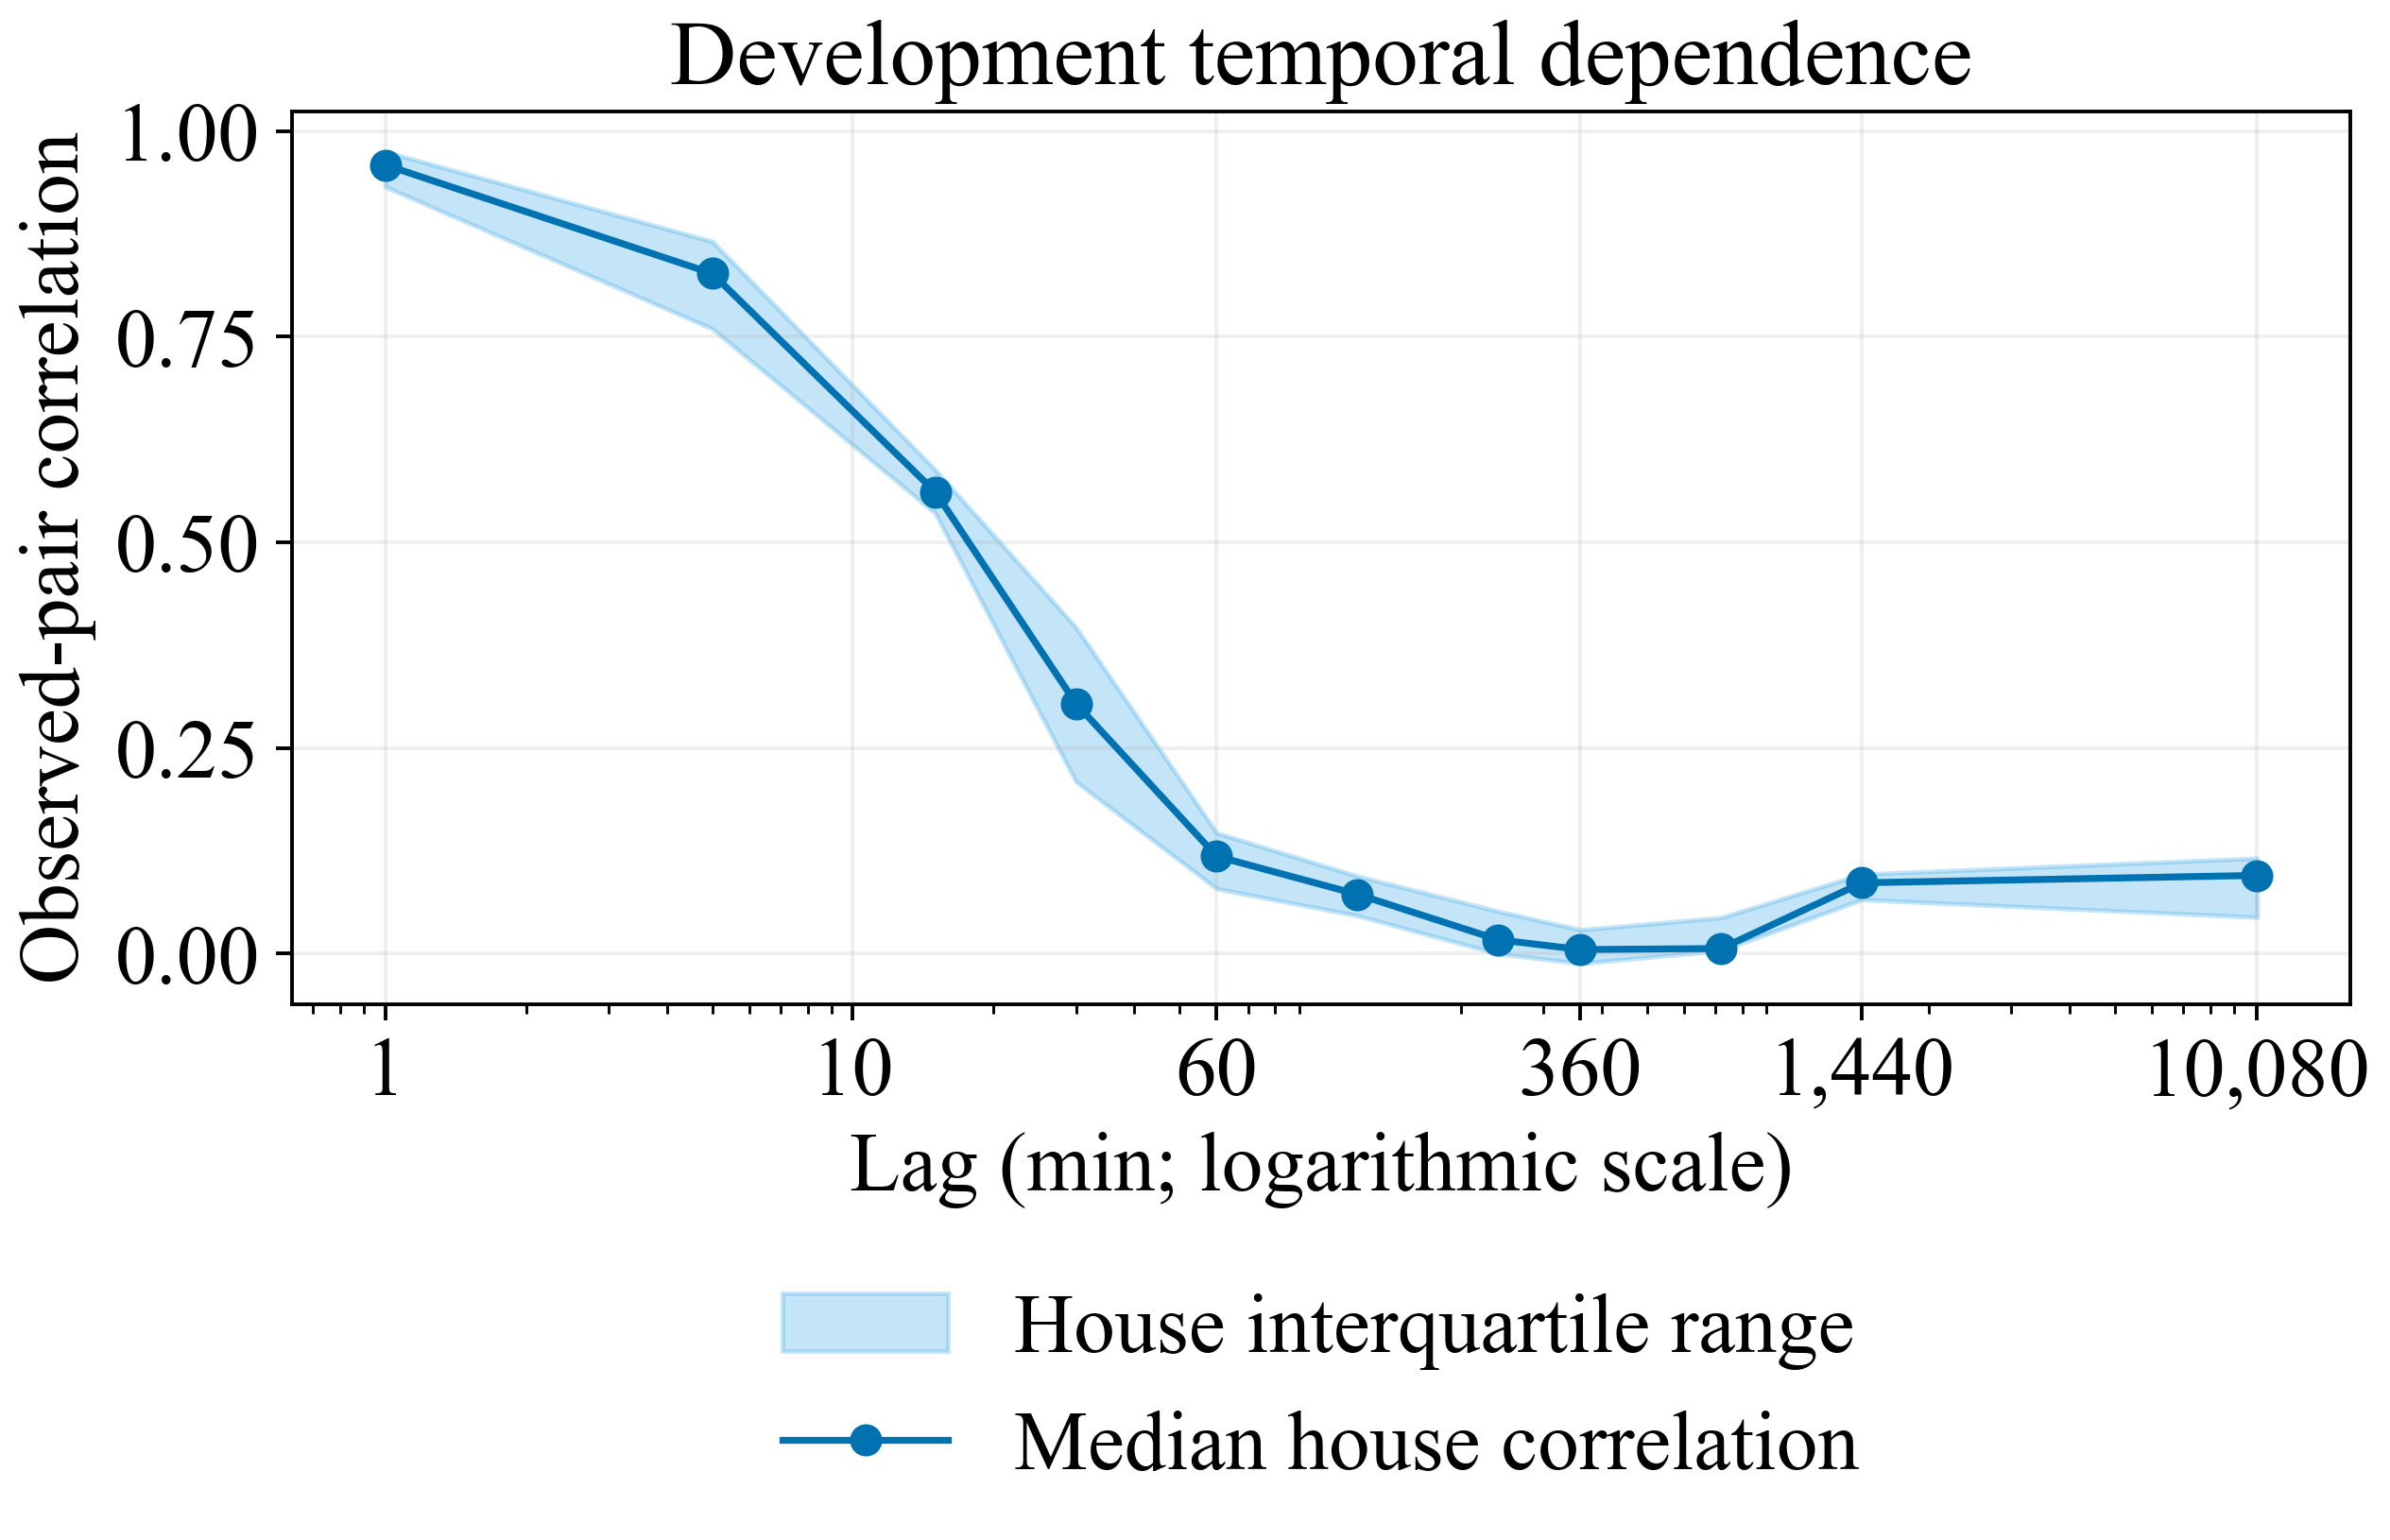

In [14]:
# Observed-pair temporal dependence, independently within each household's training interval.
lags=[1,5,15,30,60,120,240,360,720,1440,10080]
acf_rows=[]
for house,info in houses.items():
    mask=info["ids"].fold_1.eq("train")
    y=info["values"].loc[mask,"P_agg"].to_numpy()
    for lag in lags:
        a,b=y[lag:],y[:-lag]
        keep=np.isfinite(a)&np.isfinite(b)
        rho=np.corrcoef(a[keep],b[keep])[0,1] if keep.sum()>=100 else np.nan
        acf_rows.append({"House":house,"Lag (min)":lag,"Observed pairs":int(keep.sum()),"Lag correlation":rho})
acf=pd.DataFrame(acf_rows)
for house in range(1,11):
    table(acf[acf.House.eq(house)],f"training_acf_house_{house:02d}",f"Table 13.{house}. House {house}: observed-pair training lag correlations.")
acf_summary=acf.groupby("Lag (min)")["Lag correlation"].agg(median="median",q25=lambda s:s.quantile(.25),q75=lambda s:s.quantile(.75))
fig,ax=plt.subplots(figsize=(7.5,5))
ax.fill_between(acf_summary.index,acf_summary.q25,acf_summary.q75,color="#56B4E9",alpha=.35,label="House interquartile range")
ax.plot(acf_summary.index,acf_summary["median"],marker="o",color="#0072B2",label="Median house correlation")
ax.set_xscale("log");ax.set_xticks([1,10,60,360,1440,10080],labels=["1","10","60","360","1,440","10,080"])
ax.set_xlabel("Lag (min; logarithmic scale)");ax.set_ylabel("Observed-pair correlation")
ax.set_title("Development temporal dependence")
ax.grid(alpha=.2);ax.legend(loc="upper center",bbox_to_anchor=(.5,-.24),frameon=False)
fig.subplots_adjust(left=.15,right=.98,top=.9,bottom=.36)
save_figure(fig,"13_training_temporal_dependence")

## 10. Missingness co-occurrence and observability

Pairwise missingness association uses only simultaneously installed auxiliary channels within a house; structurally absent types are not counted as outages. Correlations are first computed per house and then averaged by semantic pair, so long records do not dominate. Environmental channels are excluded from the power-observability count. The unknown House 8 duplicate group contributes once. Mask co-occurrence can reflect acquisition processes, coverage rules or sensor failures; it does not identify a causal mechanism.

Type A,Type B,Houses,correlation,joint_missing
HVAC/air_conditioner,HVAC/air_conditioner,5,0.3887,0.0728
HVAC/air_conditioner,dishwasher,2,−0.0119,0.0566
HVAC/air_conditioner,kettle,1,−0.1605,0.0205
HVAC/air_conditioner,refrigerator/freezer,7,0.2529,0.1306
HVAC/air_conditioner,washing_machine,7,0.2245,0.0901
HVAC/air_conditioner,water_heater,7,0.1629,0.2185
dishwasher,refrigerator/freezer,2,0.0213,0.0325
dishwasher,washing_machine,2,0.1401,0.0361
dishwasher,water_heater,2,0.1080,0.1111
kettle,refrigerator/freezer,1,−0.0464,0.0109


House,Installed unique auxiliaries,Available auxiliaries,Targets,Fraction (%),Mean target (kW)
1,5,0,2,0.0014,0.1207
1,5,1,24,0.0163,0.1649
1,5,2,5712,3.8774,0.1739
1,5,3,26936,18.2846,0.1574
1,5,4,111458,75.6596,0.2466
1,5,5,3183,2.1607,2.0667


House,Installed unique auxiliaries,Available auxiliaries,Targets,Fraction (%),Mean target (kW)
2,5,0,20,0.0290,0.0947
2,5,1,176,0.2551,0.1384
2,5,2,6817,9.8794,0.0705
2,5,3,19050,27.6079,0.0904
2,5,4,25874,37.4975,0.1262
2,5,5,17065,24.7312,0.1730


House,Installed unique auxiliaries,Available auxiliaries,Targets,Fraction (%),Mean target (kW)
3,5,0,210,0.1461,0.0693
3,5,1,5259,3.6598,0.1842
3,5,2,16483,11.4706,0.2227
3,5,3,28168,19.6022,0.2749
3,5,4,71882,50.0230,0.2447
3,5,5,21696,15.0983,0.2058


House,Installed unique auxiliaries,Available auxiliaries,Targets,Fraction (%),Mean target (kW)
4,5,0,1424,1.2020,0.2548
4,5,1,4911,4.1454,0.2180
4,5,2,10057,8.4891,0.2556
4,5,3,42556,35.9213,0.2899
4,5,4,47035,39.7020,0.2612
4,5,5,12487,10.5402,0.3232


House,Installed unique auxiliaries,Available auxiliaries,Targets,Fraction (%),Mean target (kW)
5,5,0,3,0.0034,0.8076
5,5,1,10622,12.1149,0.3424
5,5,2,21425,24.4363,0.5529
5,5,3,32952,37.5834,0.3680
5,5,4,21705,24.7556,0.5442
5,5,5,970,1.1063,2.4602


... (2 outputs left out)

House,Installed unique auxiliaries,Available auxiliaries,Targets,Fraction (%),Mean target (kW)
8,3,0,166,0.2348,0.8485
8,3,1,3345,4.7319,1.0001
8,3,2,9115,12.8943,0.3592
8,3,3,58064,82.1389,0.1797


House,Installed unique auxiliaries,Available auxiliaries,Targets,Fraction (%),Mean target (kW)
9,3,0,1076,1.3475,0.2840
9,3,1,8194,10.2617,0.2447
9,3,2,33818,42.3519,0.2449
9,3,3,36762,46.0388,0.2520


House,Installed unique auxiliaries,Available auxiliaries,Targets,Fraction (%),Mean target (kW)
10,6,0,57,0.1270,0.2999
10,6,1,496,1.1054,0.3315
10,6,2,2651,5.9082,0.3259
10,6,3,9055,20.1805,0.3076
10,6,4,17034,37.9630,0.3018
10,6,5,6079,13.5480,0.2925
10,6,6,9498,21.1678,0.3025


House,Nominal auxiliaries,Unique streams,Canonical types,No current auxiliary (%),All unique auxiliaries (%)
1,5,5,4,0.0014,2.1607
2,5,5,5,0.0290,24.7312
3,5,5,4,0.1461,15.0983
4,5,5,4,1.2020,10.5402
5,5,5,5,0.0034,1.1063
6,3,3,3,0.0000,99.6641
7,5,5,4,5.6235,22.7005
8,4,3,3,0.2348,82.1389
9,3,3,3,1.3475,46.0388
10,6,6,5,0.1270,21.1678


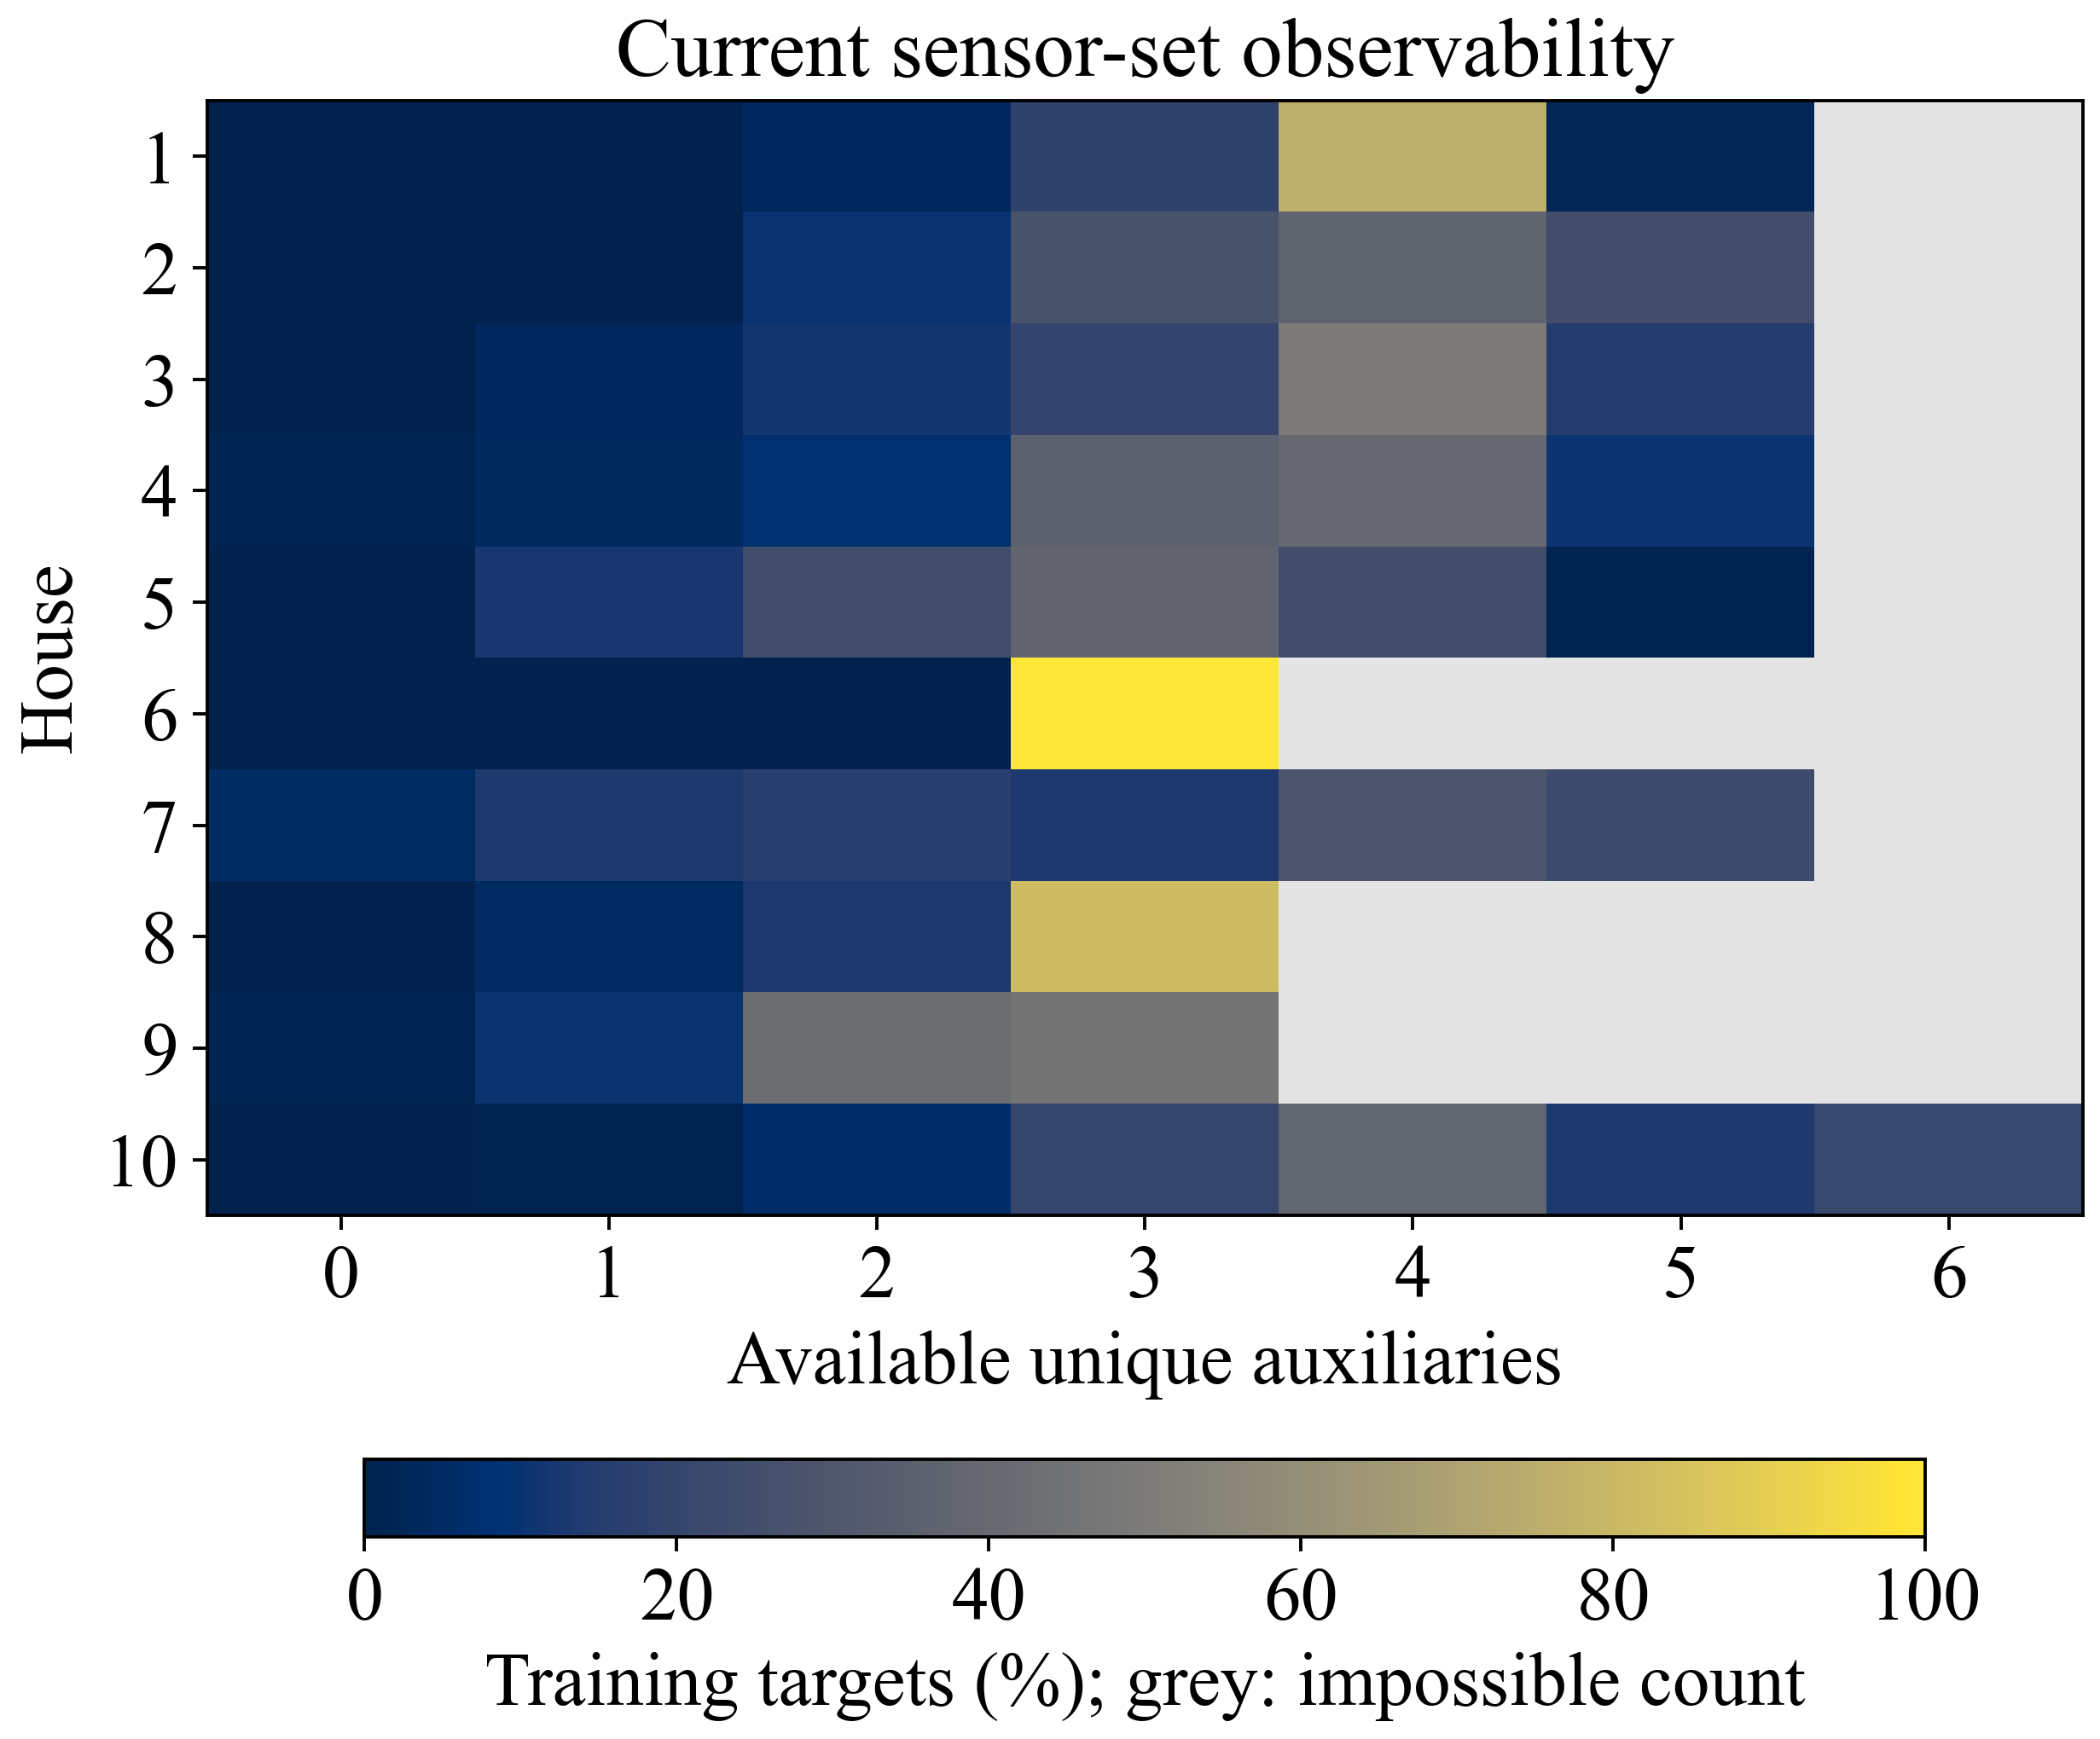

In [15]:
# Analyze current observability and co-missingness from full first-fold training calendars.
missing_rows=[];observability_rows=[];composition_rows=[]
for house,info in houses.items():
    train=info["ids"].fold_1.eq("train")
    reps=list(duplicate_maps[1][house])
    miss=~info["available"].loc[train,reps]
    corr=miss.astype(float).corr()
    for a,b in combinations(reps,2):
        ta,tb=sorted([duplicate_maps[1][house][a]["type"],duplicate_maps[1][house][b]["type"]])
        missing_rows.append({"House":house,"Type A":ta,"Type B":tb,"Missingness correlation":corr.loc[a,b],
            "Both missing fraction":float((miss[a]&miss[b]).mean()),"Calendar minutes":len(miss)})
    select=train&info["eligible"]
    count=info["available"].loc[select,reps].sum(axis=1)
    y=info["values"].loc[select,"P_agg"]
    for k in range(len(reps)+1):
        group=y[count.eq(k)]
        observability_rows.append({"House":house,"Installed unique auxiliaries":len(reps),"Available auxiliaries":k,
            "Targets":len(group),"Fraction (%)":100*len(group)/len(y),"Mean target (kW)":group.mean()})
    composition_rows.append({"House":house,"Nominal auxiliaries":len(semantic_map.query("house == @house and role == 'auxiliary_power'")),
        "Unique streams":len(reps),"Canonical types":len({v["type"] for v in duplicate_maps[1][house].values()}),
        "No current auxiliary (%)":100*count.eq(0).mean(),"All unique auxiliaries (%)":100*count.eq(len(reps)).mean()})
missingness=pd.DataFrame(missing_rows)
missingness.to_csv(TABLES / "missingness_pair_details.csv",index=False)
# First average multiple same-type pairs inside each house, then give houses equal weight.
missing_by_house=missingness.groupby(["House","Type A","Type B"],as_index=False).agg(
    correlation=("Missingness correlation","mean"),joint_missing=("Both missing fraction","mean"))
missing_summary=missing_by_house.groupby(["Type A","Type B"],as_index=False).agg(
    Houses=("House","nunique"),correlation=("correlation","mean"),joint_missing=("joint_missing","mean"))
table(missing_summary,"missingness_cooccurrence","Table 14. Equal-house missingness associations for installed semantic sensor pairs.")
observability=pd.DataFrame(observability_rows)
for house in range(1,11):
    table(observability[observability.House.eq(house)],f"training_observability_house_{house:02d}",
          f"Table 15.{house}. House {house}: current auxiliary availability and observed training target means.")
composition_train=pd.DataFrame(composition_rows)
table(composition_train,"training_unique_composition","Table 16. Unique sensor-set composition and observable extreme states in training.")
matrix=observability.pivot(index="House",columns="Available auxiliaries",values="Fraction (%)")
cmap=mpl.colormaps["cividis"].copy();cmap.set_bad("#e4e4e4")
fig,ax=plt.subplots(figsize=(7,5.8),layout="constrained")
im=ax.imshow(matrix.to_numpy(),cmap=cmap,vmin=0,vmax=100,aspect="auto")
ax.set_xticks(range(len(matrix.columns)),labels=matrix.columns);ax.set_yticks(range(10),labels=matrix.index)
ax.set_xlabel("Available unique auxiliaries");ax.set_ylabel("House");ax.set_title("Current sensor-set observability")
bar=fig.colorbar(im,ax=ax,orientation="horizontal",pad=.05,fraction=.07)
bar.set_label("Training targets (%); grey: impossible count")
save_figure(fig,"14_training_observability")

**Interpretation.** Observed-pair lag-1 correlations are strong across the inspected houses. At 360 minutes several are near zero or negative, while some houses retain daily/weekly recurrence. Persistence therefore needs a serious comparison, and one context length cannot be assumed optimal. Missingness is also informative: House 1's mean target differs markedly between the complete and partially available auxiliary strata, as quantified in the table. This is an observational association shaped by the quality rules, not a causal effect of observing a sensor. Include an observable-mask-only control when assessing model mechanisms.

The final value-only PCA reaches its variance threshold only after retaining many components; the exact component counts and explained shares are computed above. The plot displays every tenth sample within each house, while fitting uses the full balanced sample. It is a partial projection, not evidence that all domains are separable.

## 11. Remaining independent preprocessing fits

In [16]:
# Fit fold 2 using its own training IDs; fold 1 parameters are never reused.
fit_fold_preprocessing(2)

Fold,Training targets,Input columns,Retained value columns,Missingness indicators,Target scale (kW)
1,904525,172,107,73,0.6497
2,1379921,172,107,73,0.7277


**Interpretation.** Fold 2 fitting uses its own full training population and yields the same output schema with a different fitted target scale; borrowing the first fold scale would therefore change preprocessing.

In [17]:
# Fit fold 3 using its own training IDs and independently recognized duplicate map.
fit_fold_preprocessing(3)

Fold,Training targets,Input columns,Retained value columns,Missingness indicators,Target scale (kW)
1,904525,172,107,73,0.6497
2,1379921,172,107,73,0.7277
3,1855057,172,107,73,0.7549


**Interpretation.** Fold 3 fitting uses its own full training population and target scale, calculated above. All three states retain separate exact training-ID files and numeric parameters.

## 12. Development shift with fixed training transformations

Compare training and subsequent inner-validation covariates using medians standardized by the already fitted training scale. This is a descriptive shift analysis inside development, not a rule for retuning preprocessing. Outer-validation and locked labels are not used. Availability shift is reported separately from observed value shift. Calendar span and season differ between households, so observed differences are not solely an instrumentation effect.

House,Feature,Train observed n,Inner observed n,Median shift / train scale,Availability change (pp)
1,Aggregate: lag 1 min,147007,23254,−0.4303,0.0759
2,Aggregate: lag 1 min,68411,12074,−0.1813,0.6416
3,Aggregate: lag 1 min,143303,26177,−0.1091,−0.4570
4,Aggregate: lag 1 min,116711,19819,−0.0567,−1.2011
5,Aggregate: lag 1 min,87600,15138,−0.0183,−0.9063
6,Aggregate: lag 1 min,38356,11516,−0.1349,−3.4535
7,Aggregate: lag 1 min,98213,18390,0.2338,2.4900
8,Aggregate: lag 1 min,69287,11976,0.2386,−0.0521
9,Aggregate: lag 1 min,79480,13366,0.1018,−0.2719
10,Aggregate: lag 1 min,37683,6688,−0.2070,0.4832


House,Feature,Train observed n,Inner observed n,Median shift / train scale,Availability change (pp)
1,Current submeter sum,147313,23264,−0.9792,−0.0888
2,Current submeter sum,68982,12100,−0.1809,0.0290
3,Current submeter sum,143488,26370,−0.0405,0.1461
4,Current submeter sum,117046,20065,0.0000,−0.2760
5,Current submeter sum,87674,15285,0.0007,−0.0293
6,Current submeter sum,38409,11945,0.0426,0.0000
7,Current submeter sum,98665,19064,0.0258,5.5920
8,Current submeter sum,70524,12186,0.0449,−0.0842
9,Current submeter sum,78774,13288,0.3371,0.0330
10,Current submeter sum,44813,7916,0.0287,0.1018


House,Feature,Train observed n,Inner observed n,Median shift / train scale,Availability change (pp)
1,Available auxiliary count,147315,23285,0.0000,0.0000
2,Available auxiliary count,69002,12100,0.0000,0.0000
3,Available auxiliary count,143698,26370,1.0000,0.0000
4,Available auxiliary count,118470,20366,0.0000,0.0000
5,Available auxiliary count,87677,15290,0.0000,0.0000
6,Available auxiliary count,38409,11945,0.0000,0.0000
7,Available auxiliary count,104544,19070,0.0000,0.0000
8,Available auxiliary count,70690,12225,0.0000,0.0000
9,Available auxiliary count,79850,13465,1.0000,0.0000
10,Available auxiliary count,44870,7918,1.0000,0.0000


House,Feature,Train observed n,Inner observed n,Median shift / train scale,Availability change (pp)
1,Current water heater,4607,1084,10.4045,1.5280
2,Current water heater,39512,7118,0.0000,1.5643
3,Current water heater,24332,24157,0.0000,74.6752
4,Current water heater,95245,16404,0.0000,0.1501
5,Current water heater,9084,818,8.0556,−5.0109
6,Current water heater,38296,11484,0.0000,−3.5652
7,Current water heater,54151,6311,0.0000,−18.7035
8,Current water heater,0,0,Unavailable,0.0000
9,Current water heater,59059,11143,0.0000,8.7929
10,Current water heater,11864,3218,0.0000,14.2007


House,Feature,Train observed n,Inner observed n,Median shift / train scale,Availability change (pp)
1,Current refrigerator,138458,23258,−1.0071,5.8963
2,Current refrigerator,66691,11946,−0.2269,2.0765
3,Current refrigerator,115659,25822,−0.0553,17.4343
4,Current refrigerator,57158,13747,0.0000,19.2529
5,Current refrigerator,47820,2855,0.4705,−35.8688
6,Current refrigerator,38395,11940,0.0000,−0.0054
7,Current refrigerator,52179,18579,0.0001,47.5142
8,Current refrigerator,67303,11600,0.0487,−0.3211
9,Current refrigerator,54294,13101,0.3434,29.3017
10,Current refrigerator,40124,7681,0.0116,7.5840


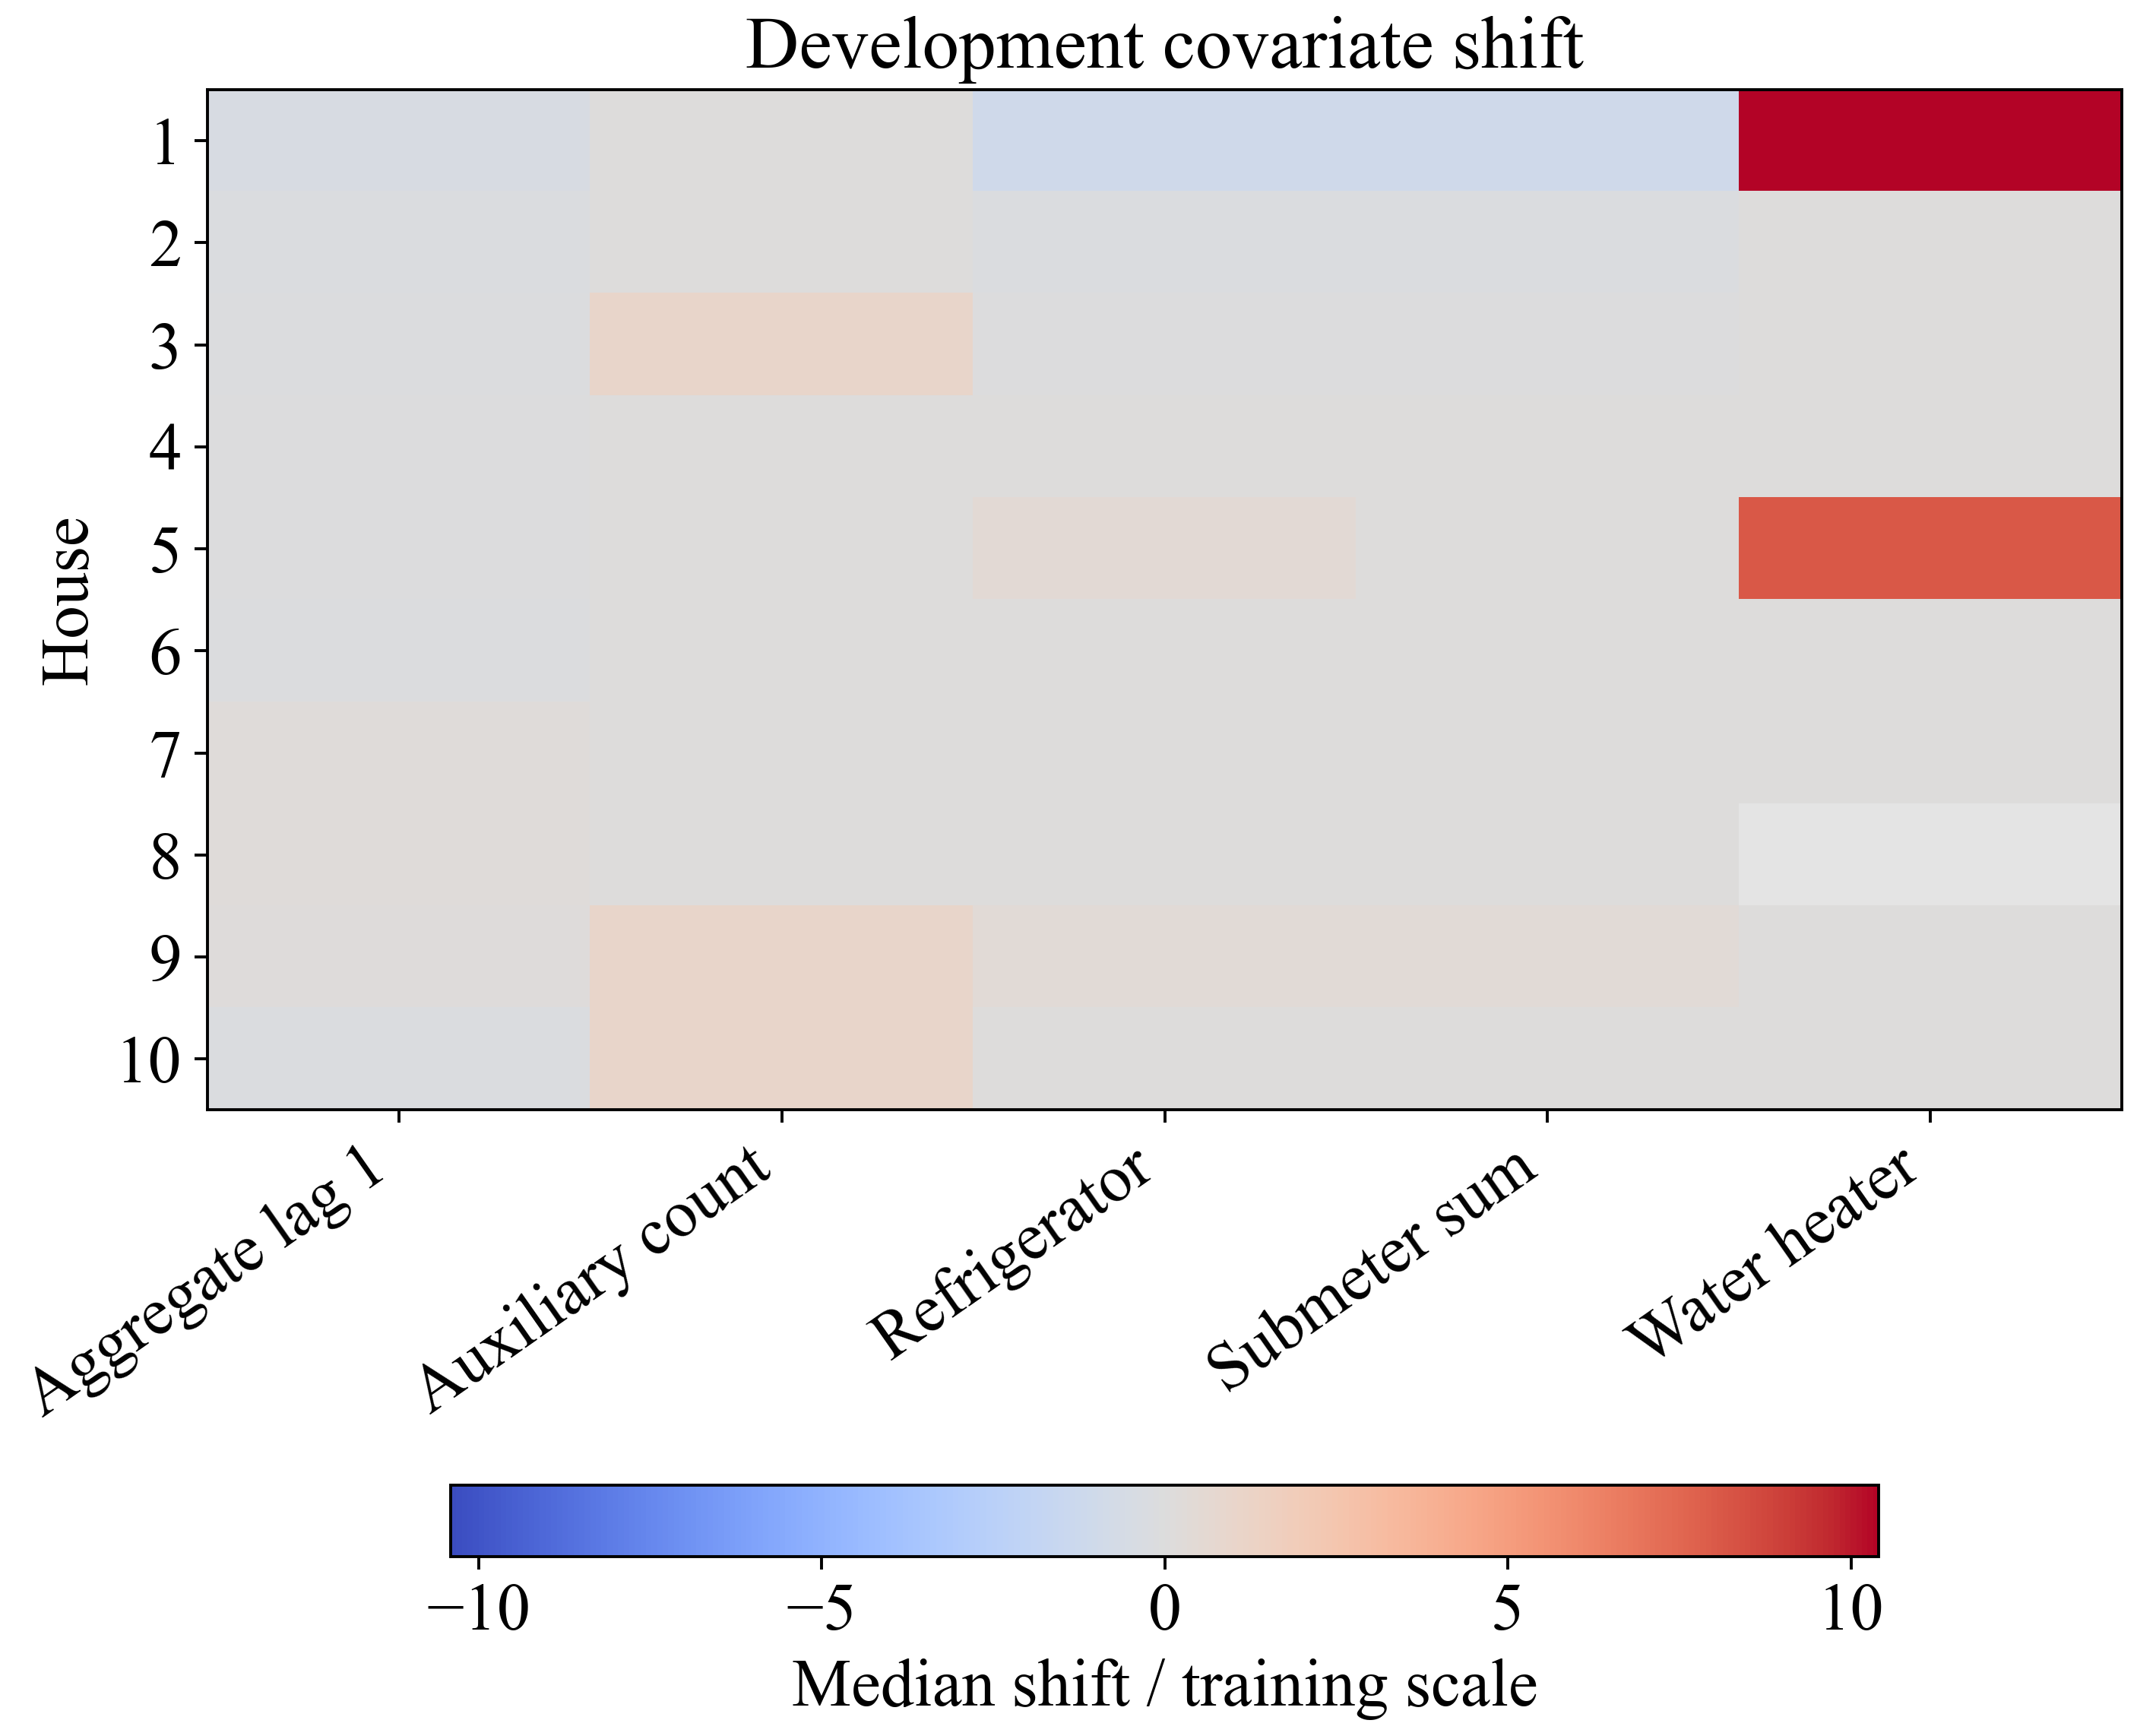

In [18]:
# Inspect inner-validation covariate shift without fitting on validation inputs or targets.
shift_rows=[]
shift_features=["aggregate_lag_1","current_aux_sum","current_aux_count","current_water_heater_sum","current_refrigerator_freezer_sum"]
for house,info in houses.items():
    x=house_features(house,1)
    train=info["eligible"] & info["ids"].fold_1.eq("train")
    valid=info["eligible"] & info["ids"].fold_1.eq("inner_validation")
    for name in shift_features:
        tr,va=x.loc[train,name],x.loc[valid,name]
        scale=preprocessors[1].state["scale"][name]
        shift_rows.append({"House":house,"Feature":feature_labels[name],
            "Train observed n":int(tr.notna().sum()),"Inner observed n":int(va.notna().sum()),
            "Median shift / train scale":((va.median() if va.notna().any() else np.nan)-(tr.median() if tr.notna().any() else np.nan))/scale,
            "Availability change (pp)":100*(va.notna().mean()-tr.notna().mean())})
shift=pd.DataFrame(shift_rows)
for feature in shift.Feature.unique():
    stem=re.sub(r"[^a-z0-9]+","_",feature.lower()).strip("_")
    table(shift[shift.Feature.eq(feature)],"inner_shift_"+stem,f"Table 17. Inner-validation shift: {feature}.")
shift_matrix=shift.pivot(index="House",columns="Feature",values="Median shift / train scale")
limit=max(1.,np.nanmax(np.abs(shift_matrix.to_numpy())))
fig,ax=plt.subplots(figsize=(8,6.5),layout="constrained")
cmap=mpl.colormaps["coolwarm"].copy();cmap.set_bad("#e4e4e4")
im=ax.imshow(shift_matrix.to_numpy(),cmap=cmap,vmin=-limit,vmax=limit,aspect="auto")
ax.set_yticks(range(10),labels=shift_matrix.index)
short={"Aggregate: lag 1 min":"Aggregate lag 1","Available auxiliary count":"Auxiliary count",
       "Current refrigerator":"Refrigerator","Current submeter sum":"Submeter sum","Current water heater":"Water heater"}
ax.set_xticks(range(len(shift_matrix.columns)),labels=[short[c] for c in shift_matrix.columns],rotation=35,ha="right")
ax.set_ylabel("House");ax.set_title("Development covariate shift")
bar=fig.colorbar(im,ax=ax,orientation="horizontal",fraction=.07,pad=.05)
bar.set_label("Median shift / training scale")
save_figure(fig,"15_inner_validation_covariate_shift")

**Interpretation.** Inner-validation water-heater availability rises substantially in House 3, while refrigerator availability falls in House 5. Water-heater median shifts in Houses 1 and 5 are also large relative to their fitted training scales; exact shifts are in the computed table. House 8 has no resolved water-heater stream: its light-grey heatmap cell and coefficient are unavailable rather than zero; near-neutral colours elsewhere represent small observed shifts. The analysis does not refit any transformation.

## 13. Training-fitted missingness distributions

Natural missingness parameters use only channel availability in each training partition, without reading target magnitudes. Gap distributions retain their long tails; the fixed 5/30/120-minute stress scenarios are separate controlled interventions. Raw unavailable runs include quality exclusions and insufficient coverage, so they are not asserted to be documented communication outages. Types are pooled across houses with explicit counts. Validation and external missingness cannot change these fitted distributions.

In [19]:
# Fit missingness rates, run lengths and per-house observed patterns inside each training fold.
mask_fit_rows=[]
for fold in [1,2,3]:
    grouped={};patterns={}
    for house,info in houses.items():
        train=info["ids"][f"fold_{fold}"].eq("train")
        sensors=["P_agg",*duplicate_maps[fold][house]]
        available=info["available"].loc[train,sensors]
        # Pattern frequencies preserve within-house co-missingness without target values.
        bit_patterns=(available.to_numpy(dtype=np.uint16)*(1<<np.arange(len(sensors)))).sum(axis=1)
        codes,frequency=np.unique(bit_patterns,return_counts=True)
        patterns[str(house)]={"sensors":sensors,"codes":codes.tolist(),"counts":frequency.tolist()}
        for sensor in sensors:
            canonical="aggregate" if sensor=="P_agg" else duplicate_maps[fold][house][sensor]["type"]
            entry=grouped.setdefault(canonical,{"minutes":0,"unavailable":0,"gap_lengths":[]})
            missing=~available[sensor].to_numpy()
            edges=np.diff(np.r_[False,missing,False].astype(np.int8))
            lengths=np.flatnonzero(edges==-1)-np.flatnonzero(edges==1)
            entry["minutes"]+=len(missing);entry["unavailable"]+=int(missing.sum());entry["gap_lengths"].extend(lengths.tolist())
    fitted={"fold":fold,"fit_id_sha256":preprocessors[fold].state["fit_id_sha256"],"types":{},"house_patterns":patterns}
    for canonical,entry in grouped.items():
        lengths=np.asarray(entry["gap_lengths"],dtype=int)
        vals,counts=np.unique(lengths,return_counts=True)
        rate=entry["unavailable"]/entry["minutes"]
        fitted["types"][canonical]={"unavailable_fraction":rate,"gap_lengths":vals.tolist(),"gap_counts":counts.tolist()}
        mask_fit_rows.append({"Fold":fold,"Type":canonical,"Training channel-minutes":entry["minutes"],
            "Unavailable (%)":100*rate,"Gap events":len(lengths),"Gap median (min)":float(np.median(lengths)) if len(lengths) else 0,
            "Gap q95 (min)":float(np.quantile(lengths,.95)) if len(lengths) else 0})
    (PREP/f"fold_{fold}_mask_distribution.json").write_text(json.dumps(fitted,indent=2)+"\n")
mask_fit=pd.DataFrame(mask_fit_rows)
for fold in [1,2,3]:
    table(mask_fit[mask_fit.Fold.eq(fold)],f"fold_{fold}_natural_mask_fit",f"Table 18.{fold}. Fold {fold}: training-fitted availability and unavailable-run distributions.")

Fold,Type,Training channel-minutes,Unavailable (%),Gap events,Gap median (min),Gap q95 (min)
1,aggregate,983618,8.0410,18474,1.0000,3.0000
1,HVAC/air_conditioner,1349448,20.9735,33656,1.0000,7.0000
1,water_heater,910997,62.6555,73270,1.0000,15.0000
1,refrigerator/freezer,983618,29.4596,10684,1.0000,3.0000
1,washing_machine,983618,25.9638,13175,1.0000,4.0000
1,kettle,70028,38.0791,578,1.0000,3.0000
1,dishwasher,147870,11.0205,7554,1.0000,4.0000
1,unknown,72621,10.3634,3400,1.0000,5.0000


Fold,Type,Training channel-minutes,Unavailable (%),Gap events,Gap median (min),Gap q95 (min)
2,aggregate,1479034,6.7012,28353,1.0000,3.0000
2,HVAC/air_conditioner,2028502,16.6200,49112,1.0000,6.0000
2,water_heater,1369742,57.9050,112050,1.0000,17.0000
2,refrigerator/freezer,1479034,24.9358,16429,1.0000,3.0000
2,washing_machine,1479034,21.1539,19898,1.0000,4.0000
2,kettle,105403,25.3608,641,1.0000,3.0000
2,dishwasher,222526,13.0915,9270,1.0000,4.0000
2,unknown,109292,10.2148,5160,1.0000,5.0000


Fold,Type,Training channel-minutes,Unavailable (%),Gap events,Gap median (min),Gap q95 (min)
3,aggregate,1974447,6.0468,34980,1.0000,3.0000
3,HVAC/air_conditioner,2707551,14.3278,62055,1.0000,6.0000
3,water_heater,1828484,54.3683,153631,1.0000,16.0000
3,refrigerator/freezer,1974447,21.9804,23038,1.0000,3.0000
3,washing_machine,1974447,19.0800,27526,1.0000,4.0000
3,kettle,140777,19.0109,672,1.0000,3.0000
3,dishwasher,297182,19.6903,10704,1.0000,4.0000
3,unknown,145963,10.0649,6756,1.0000,5.0000


**Interpretation.** The independent preprocessing fits have identical output schemas but different fitted scales and training populations. Inner-validation water-heater availability increases substantially in House 3, as does refrigerator availability in House 7. These observed development shifts justify evaluating availability strata, while the stored training parameters remain unchanged. Across folds the computed pooled aggregate unavailable fraction decreases; natural-mask distributions must therefore remain fold-specific.

## 14. Shared observable batches for sequence and tabular models

An input batch contains only permitted historical values, observation masks, coverage, elapsed age, semantic types, current observed auxiliary values and deterministic context. The current aggregate value, mask and coverage are forcibly absent. A separate training/evaluation label path will supply targets; labels are never included in this input object.

A block of length B hides the current aggregate and its previous B−1 minutes. Point missingness hides the current value only. Auxiliary retention is a Bernoulli probability applied to naturally available channels; realized counts are reported rather than pretending fractional sensors exist. Sensor dropout applies the same channel decision to its history; mixed masking chooses history dropout deterministically per query. A deterministic keyed function of observation ID, seed and original channel name ensures paired masks across models and invariance to sensor order. Original names are randomization keys, not learned embeddings. All tabular history summaries are rebuilt from exactly these masked histories. The 360-minute input envelope permits networks to use candidate shorter contexts without changing allowed information.

In [20]:
# Construct label-free observed sensor tensors with deterministic, order-independent masking.
def keyed_uniform(*parts):
    key="|".join(map(str,parts)).encode()
    return int.from_bytes(hashlib.sha256(key).digest()[:8],"little")/2**64

def observed_sensor_batch(info,mapping,queries,target_scale,fold=1,history_minutes=360,
                          aggregate_gap=1,auxiliary_retention=1.,seed=17,mode="point",sensor_order=None):
    assert mode in {"point","block","sensor_dropout","mixed"}
    assert 1<=aggregate_gap<=history_minutes<=360 and 0<=auxiliary_retention<=1
    queries=np.asarray(queries,dtype=int)
    assert (queries>=history_minutes).all() and (queries<len(info["values"])).all()
    sensors=["P_agg",*sorted(mapping)] if sensor_order is None else list(sensor_order)
    assert set(sensors)=={"P_agg",*mapping} and len(sensors)==len(mapping)+1
    aggregate_index=sensors.index("P_agg")
    history_indices=queries[:,None]-np.arange(history_minutes,0,-1)[None,:]
    raw=info["values"][sensors].to_numpy(dtype=np.float64)
    available=info["available"][sensors].to_numpy(dtype=bool)
    coverage=info["coverage"][sensors].to_numpy(dtype=np.float64)
    hvalues=raw[history_indices].transpose(0,2,1)
    hmask=available[history_indices].transpose(0,2,1).copy()
    hcoverage=coverage[history_indices].transpose(0,2,1)
    if aggregate_gap>1: hmask[:,aggregate_index,-(aggregate_gap-1):]=False
    current_mask=available[queries].copy()
    current_mask[:,aggregate_index]=False
    current_values=raw[queries].copy()
    for b,q in enumerate(queries):
        identity=info["ids"].iloc[q].observation_id
        drop_history=(mode=="sensor_dropout") or (mode=="mixed" and keyed_uniform(identity,seed,"history")<.5)
        for j,sensor in enumerate(sensors):
            if sensor=="P_agg":continue
            keep=keyed_uniform(identity,seed,sensor)<auxiliary_retention
            current_mask[b,j] &= keep
            if drop_history and not keep:hmask[b,j,:]=False
    positions=np.arange(history_minutes)[None,None,:]
    last=np.maximum.accumulate(np.where(hmask,positions,-history_minutes-1),axis=-1)
    age=np.minimum(positions-last,history_minutes+1)/(history_minutes+1)
    history=np.stack([np.where(hmask,hvalues/target_scale,0),hmask.astype(float),
                      np.where(hmask,np.nan_to_num(hcoverage),0),age],axis=-1).astype(np.float32)
    current_values=np.where(current_mask,current_values/target_scale,0).astype(np.float32)
    types=["aggregate" if s=="P_agg" else mapping[s]["type"] for s in sensors]
    type_ids=np.array([schema["power_types"].index(t) for t in types],dtype=np.int64)
    role_ids=np.array([0 if s=="P_agg" else 1 for s in sensors],dtype=np.int64)
    ts=info["values"].index[queries]
    context=[]
    for b,(q,t) in enumerate(zip(queries,ts)):
        hour=t.hour+t.minute/60
        row=[np.sin(2*np.pi*hour/24),np.cos(2*np.pi*hour/24),
             np.sin(2*np.pi*t.dayofweek/7),np.cos(2*np.pi*t.dayofweek/7),
             np.sin(2*np.pi*(t.dayofyear-1)/365.2425),np.cos(2*np.pi*(t.dayofyear-1)/365.2425)]
        for lag in [1440,10080]:
            previous=q-lag
            ok=previous>=0 and info["ids"].iloc[previous][f"fold_{fold}"]==info["ids"].iloc[q][f"fold_{fold}"]
            ok=ok and bool(info["available"].iloc[previous].P_agg)
            row += [float(info["values"].iloc[previous].P_agg/target_scale) if ok else 0.,float(ok)]
        for sensor,unit_scale in [("temperature (C)",50),("humidity (%)",100)]:
            ok=sensor in info["available"] and bool(info["available"].iloc[q][sensor])
            row += [float(info["values"].iloc[q][sensor]/unit_scale) if ok else 0.,float(ok)]
        context.append(row)
    batch={"history":history,"current_values":current_values,"current_mask":current_mask,
           "type_ids":type_ids,"role_ids":role_ids,"unit_ids":np.zeros(len(sensors),dtype=np.int64),
           "context":np.asarray(context,dtype=np.float32),"sensor_names":sensors,"target_scale":float(target_scale)}
    assert np.isfinite(history).all() and np.isfinite(batch["context"]).all()
    assert not current_mask[:,aggregate_index].any() and not current_values[:,aggregate_index].any()
    return batch

def masked_tabular_rows(base_rows,batch,mapping):
    x=base_rows.copy()
    history=batch["history"]
    assert history.shape[2]==360
    mask=history[:,:,:,1].astype(bool)
    values=np.where(mask,history[:,:,:,0].astype(np.float64)*batch["target_scale"],np.nan)
    current=np.where(batch["current_mask"],batch["current_values"].astype(np.float64)*batch["target_scale"],np.nan)
    sensors=batch["sensor_names"];agg=sensors.index("P_agg")
    def summarize(a,width,stat):
        a=a[:,-width:];valid=np.isfinite(a);count=valid.sum(axis=1);filled=np.where(valid,a,0)
        if stat=="mean":return np.divide(filled.sum(axis=1),count,out=np.full(len(a),np.nan),where=count>0)
        if stat=="std":
            mean=np.divide(filled.sum(axis=1),count,out=np.zeros(len(a)),where=count>0)
            squares=np.where(valid,(a-mean[:,None])**2,0).sum(axis=1)
            return np.sqrt(np.divide(squares,count-1,out=np.full(len(a),np.nan),where=count>1))
        if stat=="min":return np.where(count>0,np.where(valid,a,np.inf).min(axis=1),np.nan)
        if stat=="max":return np.where(count>0,np.where(valid,a,-np.inf).max(axis=1),np.nan)
    def last_value(a):
        valid=np.isfinite(a);last=np.where(valid,np.arange(a.shape[1]),-1).max(axis=1)
        return np.where(last>=0,a[np.arange(len(a)),np.maximum(0,last)],np.nan),np.where(last>=0,a.shape[1]-last,a.shape[1]+1)
    for lag in [1,2,5,15,30,60,120,240,360]:x[f"aggregate_lag_{lag}"]=values[:,agg,-lag]
    for width in [15,60,240,360]:
        for stat in ["mean","std","min","max"]:x[f"aggregate_{stat}_{width}"]=summarize(values[:,agg,:],width,stat)
        x[f"aggregate_coverage_{width}"]=mask[:,agg,-width:].mean(axis=1)
    x["aggregate_last"],x["aggregate_age"]=last_value(values[:,agg,:])
    # Day/week retrieval is supplied by the same label-free context, with explicit presence bits.
    for j,lag in [(6,1440),(8,10080)]:
        x[f"aggregate_lag_{lag}"]=np.where(batch["context"][:,j+1]>0,batch["context"][:,j]*batch["target_scale"],np.nan)
    aux=[j for j,s in enumerate(sensors) if s!="P_agg"]
    x["current_aux_count"]=np.isfinite(current[:,aux]).sum(axis=1)
    x["current_aux_sum"]=np.where(x.current_aux_count>0,np.nansum(current[:,aux],axis=1),np.nan)
    for canonical in POWER_TYPES:
        idx=[sensors.index(s) for s in mapping if mapping[s]["type"]==canonical]
        tag=canonical.replace("/","_")
        if not idx:continue
        c=current[:,idx];cnt=np.isfinite(c).sum(axis=1)
        x[f"current_{tag}_sum"]=np.where(cnt>0,np.nansum(c,axis=1),np.nan)
        x[f"current_{tag}_count"]=cnt
        hv=values[:,idx,:]
        summed=np.where(np.isfinite(hv).any(axis=1),np.nansum(hv,axis=1),np.nan)
        for width in [15,60,240]:x[f"past_{tag}_mean_{width}"]=summarize(summed,width,"mean")
        x[f"past_{tag}_std_240"]=summarize(summed,240,"std")
        x[f"past_{tag}_last"]=last_value(summed)[0]
        x[f"past_{tag}_coverage_240"]=mask[:,idx,-240:].mean(axis=(1,2))
    return x.astype(np.float32)

# Deterministic empirical-run sampler, fitted independently in each training fold.
def sample_fitted_gap_lengths(fold,canonical,n,seed=17,max_context=360):
    fitted=json.loads((PREP/f"fold_{fold}_mask_distribution.json").read_text())["types"][canonical]
    rng=np.random.default_rng(seed)
    observed=rng.random(n)>=fitted["unavailable_fraction"]
    counts=np.asarray(fitted["gap_counts"],dtype=float)
    if counts.sum()==0:return np.ones(n,dtype=int)
    lengths=rng.choice(fitted["gap_lengths"],size=n,p=counts/counts.sum())
    return np.where(observed,1,np.minimum(lengths+1,max_context)).astype(int)

### Batch-level causality, zero availability and permutation tests

The following tests compare the unmasked tensor-derived summaries with the deterministic table, compare block-masked summaries with direct masking of raw minute inputs, perturb hidden and future values, reverse sensor order and exercise zero available auxiliaries. Tolerances account only for float32 tensor storage; no model accuracy is being tested.

In [21]:
# Validate information parity and masking semantics before any predictive fitting.
batch_test_rows=[]
for house in [1,3,8,10]:
    info=houses[house];mapping=duplicate_maps[1][house];scale=preprocessors[1].state["target_scale"]
    queries=np.array([11000,12000,13000],dtype=int)
    base=house_features(house,1).iloc[queries]
    batch=observed_sensor_batch(info,mapping,queries,scale)
    tab=masked_tabular_rows(base,batch,mapping)
    np.testing.assert_allclose(tab,base,rtol=2e-4,atol=2e-5,equal_nan=True)
    reverse=list(batch["sensor_names"])[::-1]
    rb=observed_sensor_batch(info,mapping,queries,scale,auxiliary_retention=.5,mode="mixed",aggregate_gap=30,sensor_order=reverse)
    normal=observed_sensor_batch(info,mapping,queries,scale,auxiliary_retention=.5,mode="mixed",aggregate_gap=30)
    permutation=[reverse.index(s) for s in normal["sensor_names"]]
    for name in ["history","current_values","current_mask"]:
        np.testing.assert_array_equal(normal[name],rb[name][:,permutation])
    for name in ["type_ids","role_ids","unit_ids"]:np.testing.assert_array_equal(normal[name],rb[name][permutation])
    np.testing.assert_allclose(masked_tabular_rows(base,normal,mapping),masked_tabular_rows(base,rb,mapping),rtol=1e-6,atol=1e-6,equal_nan=True)
    zero=observed_sensor_batch(info,mapping,queries,scale,auxiliary_retention=0,mode="sensor_dropout",aggregate_gap=120)
    assert not zero["current_mask"].any()
    ai=zero["sensor_names"].index("P_agg")
    assert not zero["history"][:,ai,-119:,1].any()
    assert not zero["history"][:,np.array(zero["role_ids"])==1,:,1].any()
    # Direct raw-input block comparison for one query.
    q=queries[0];start=q-1100
    mini={k:(v.iloc[start:q+2].copy() if isinstance(v,(pd.DataFrame,pd.Series)) else v) for k,v in info.items()}
    local_q=1100
    hidden=pd.Series(False,index=mini["values"].index);hidden.iloc[local_q-29:local_q+1]=True
    direct=causal_features(mini["values"],mini["available"],mini["coverage"],mapping,aggregate_hidden=hidden).iloc[[local_q]]
    mb=observed_sensor_batch(mini,mapping,[local_q],scale,aggregate_gap=30)
    derived=masked_tabular_rows(direct,mb,mapping)
    np.testing.assert_allclose(derived,direct,rtol=2e-4,atol=2e-5,equal_nan=True)
    clean=observed_sensor_batch(mini,mapping,[local_q],scale,aggregate_gap=30)
    perturbed={k:(v.copy() if isinstance(v,(pd.DataFrame,pd.Series)) else v) for k,v in mini.items()}
    perturbed["values"].iloc[local_q:, :]=99999
    # Retain current auxiliaries/environment, perturb only current aggregate and all future values.
    perturbed["values"].iloc[local_q,:]=mini["values"].iloc[local_q,:]
    perturbed["values"].iloc[local_q,mini["values"].columns.get_loc("P_agg")]=99999
    tested=observed_sensor_batch(perturbed,mapping,[local_q],scale,aggregate_gap=30)
    for name in ["history","current_values","current_mask","context"]:np.testing.assert_array_equal(clean[name],tested[name])
    batch_test_rows.append({"House":house,"Queries":len(queries),"Unique power tokens":len(batch["sensor_names"]),
        "History minutes":batch["history"].shape[2],"Channels per history step":batch["history"].shape[3],"Context dimension":batch["context"].shape[1]})
np.testing.assert_array_equal(sample_fitted_gap_lengths(1,"aggregate",1000),sample_fitted_gap_lengths(1,"aggregate",1000))
table(pd.DataFrame(batch_test_rows),"sensor_batch_contract","Table 19. Validated label-free tensor dimensions and shared observable summaries.",precision=0)

House,Queries,Unique power tokens,History minutes,Channels per history step,Context dimension
1,3,6,360,4,14
3,3,6,360,4,14
8,3,4,360,4,14
10,3,7,360,4,14


**Interpretation.** The tested sensor sets contain four to seven unique power tokens including aggregate, with 360 historical steps, four fields per step and 14 context fields. Point-case tensor summaries match tabular calculations within float32 tolerance. Tests also confirm exact sensor-order equivariance of the observed input construction, zero delivered auxiliary values when retention is zero, removal of the previous 119 aggregate observations in a 120-minute block, and invariance to hidden-current/future perturbations. This tests preprocessing, not the equivariance or calibration of a neural network that has not yet been trained.

## 15. Cross-sensor dependence on jointly observed measurements

Use actual simultaneous auxiliary values, after fold-1 training-only deduplication. Pairs with fewer than 100 observed samples or a constant stream have undefined correlation and are omitted from the coefficient average with their status retained. Multiple physical pairs of the same semantic types are averaged within a house, then households receive equal weight. This avoids treating long records or two air conditioners as extra independent households.

In [22]:
# Pairwise auxiliary value dependence complements the separate missingness analysis.
cross_rows=[]
for house,info in houses.items():
    mapping=duplicate_maps[1][house]
    train=info["ids"].fold_1.eq("train")
    for a,b in combinations(sorted(mapping),2):
        pair=info["values"].loc[train,[a,b]].dropna()
        ta,tb=sorted([mapping[a]["type"],mapping[b]["type"]])
        valid=len(pair)>=100 and pair[a].nunique()>1 and pair[b].nunique()>1
        cross_rows.append({"House":house,"Sensor A":a,"Sensor B":b,"Type A":ta,"Type B":tb,
            "Paired n":len(pair),"Pearson":pair.corr().iloc[0,1] if valid else np.nan,
            "Spearman":pair.corr(method="spearman").iloc[0,1] if valid else np.nan})
cross=pd.DataFrame(cross_rows)
cross.to_csv(TABLES / "cross_sensor_pair_details.csv",index=False)
for house in range(1,11):
    table(cross[cross.House.eq(house)][["House","Sensor A","Sensor B","Paired n","Pearson","Spearman"]],
          f"cross_sensor_house_{house:02d}",f"Table 20.{house}. House {house}: jointly observed auxiliary correlations in training.")
house_cross=cross.groupby(["House","Type A","Type B"],as_index=False).agg(Pearson=("Pearson","mean"),Spearman=("Spearman","mean"))
cross_summary=house_cross.groupby(["Type A","Type B"],as_index=False).agg(
    Houses=("House","nunique"),Defined_houses=("Spearman","count"),Pearson=("Pearson","mean"),Spearman=("Spearman","mean"))
table(cross_summary,"cross_sensor_summary","Table 21. Equal-house auxiliary dependence by semantic type pair.")

House,Sensor A,Sensor B,Paired n,Pearson,Spearman
1,ac_1,ac_2,117672,0.2850,0.2275
1,ac_1,boiler,4611,0.2186,−0.3055
1,ac_1,fridge,138904,0.0680,−0.0063
1,ac_1,washing_machine,147512,0.0320,−0.0042
1,ac_2,boiler,3401,0.2727,−0.0392
1,ac_2,fridge,114210,0.0140,−0.0015
1,ac_2,washing_machine,117152,0.0436,0.0205
1,boiler,fridge,4174,−0.0510,−0.0822
1,boiler,washing_machine,4556,0.1477,0.1270
1,fridge,washing_machine,138793,−0.0158,−0.0990


House,Sensor A,Sensor B,Paired n,Pearson,Spearman
2,ac_1,boiler,35208,0.0021,0.0112
2,ac_1,fridge,59425,−0.0062,−0.0268
2,ac_1,kettle,36354,−0.0008,0.0041
2,ac_1,washing_machine,43901,−0.0015,−0.0073
2,boiler,fridge,38554,0.0185,0.0022
2,boiler,kettle,24902,0.0168,0.0078
2,boiler,washing_machine,28667,−0.0095,−0.0562
2,fridge,kettle,41312,0.0090,0.0413
2,fridge,washing_machine,48053,0.0090,0.0008
2,kettle,washing_machine,37026,−0.0017,−0.0090


House,Sensor A,Sensor B,Paired n,Pearson,Spearman
3,ac_1,ac_2,121007,0.2207,0.0955
3,ac_1,boiler,23680,−0.0463,−0.1323
3,ac_1,fridge,104860,−0.0060,−0.0020
3,ac_1,washing_machine,98552,0.0968,−0.0242
3,ac_2,boiler,24441,−0.1625,−0.1536
3,ac_2,fridge,115746,0.0539,0.0882
3,ac_2,washing_machine,113912,0.0165,0.0320
3,boiler,fridge,23555,−0.0129,−0.0145
3,boiler,washing_machine,23185,−0.0116,−0.0200
3,fridge,washing_machine,102255,0.0022,0.0098


House,Sensor A,Sensor B,Paired n,Pearson,Spearman
4,ac_1,ac_2,106038,0.0033,0.0858
4,ac_1,boiler,94581,0.0290,0.0853
4,ac_1,fridge,50885,−0.0293,−0.0185
4,ac_1,washing_machine,30770,−0.0059,0.1933
4,ac_2,boiler,94556,0.0697,0.0130
4,ac_2,fridge,50575,−0.0167,−0.0321
4,ac_2,washing_machine,30599,0.0893,0.0690
4,boiler,fridge,45716,−0.0251,−0.0056
4,boiler,washing_machine,27299,0.1040,0.0286
4,fridge,washing_machine,18994,0.0072,0.0021


House,Sensor A,Sensor B,Paired n,Pearson,Spearman
5,ac_1,boiler,1822,−0.5470,−0.4437
5,ac_1,dishwasher,24366,−0.0013,0.0708
5,ac_1,fridge,20697,0.0444,−0.0194
5,ac_1,washing_machine,28195,−0.0023,0.0101
5,boiler,dishwasher,8737,−0.0523,0.0678
5,boiler,fridge,7195,−0.0696,−0.0242
5,boiler,washing_machine,8049,−0.0249,−0.0575
5,dishwasher,fridge,43388,0.0039,0.0043
5,dishwasher,washing_machine,71064,−0.0042,−0.0778
5,fridge,washing_machine,47181,0.0012,0.0041


House,Sensor A,Sensor B,Paired n,Pearson,Spearman
6,boiler,fridge,38331,0.0114,0.0075
6,boiler,washing_machine,38344,−0.0153,−0.0420
6,fridge,washing_machine,39113,0.0274,0.0117


House,Sensor A,Sensor B,Paired n,Pearson,Spearman
7,ac_1,ac_2,62962,0.1259,0.6830
7,ac_1,boiler,38967,−0.0062,0.0080
7,ac_1,fridge,52416,0.0303,0.2074
7,ac_1,washing_machine,65292,0.0131,0.2212
7,ac_2,boiler,42423,−0.0043,0.0033
7,ac_2,fridge,50899,0.0190,0.1959
7,ac_2,washing_machine,67498,−0.0043,0.2670
7,boiler,fridge,27212,−0.0100,−0.0056
7,boiler,washing_machine,37992,−0.0028,0.0012
7,fridge,washing_machine,51410,−0.0125,0.0656


House,Sensor A,Sensor B,Paired n,Pearson,Spearman
8,ac_1,fridge,61936,−0.0231,0.0272
8,ac_1,washing_machine,61532,0.0530,0.1107
8,fridge,washing_machine,64574,0.0444,0.0949


House,Sensor A,Sensor B,Paired n,Pearson,Spearman
9,boiler,fridge,37904,0.0197,0.0021
9,boiler,washing_machine,53434,0.0404,0.0148
9,fridge,washing_machine,53081,−0.0069,0.0082


House,Sensor A,Sensor B,Paired n,Pearson,Spearman
10,ac_1,ac_2,17069,−0.0003,−0.0014
10,ac_1,boiler,11872,−0.0029,0.0038
10,ac_1,dishwasher,16502,−0.0041,−0.0065
10,ac_1,fridge,16447,−0.0124,−0.0091
10,ac_1,washing_machine,15833,−0.0018,−0.0069
10,ac_2,boiler,12604,−0.0011,−0.0122
10,ac_2,dishwasher,44696,−0.0021,−0.0011
10,ac_2,fridge,45864,−0.0115,−0.0069
10,ac_2,washing_machine,44333,0.0000,0.0008
10,boiler,dishwasher,12166,−0.0110,−0.0188


Type A,Type B,Houses,Defined_houses,Pearson,Spearman
HVAC/air_conditioner,HVAC/air_conditioner,5,5,0.1269,0.2181
HVAC/air_conditioner,dishwasher,2,2,−0.0022,0.0335
HVAC/air_conditioner,kettle,1,1,−0.0008,0.0041
HVAC/air_conditioner,refrigerator/freezer,7,7,0.0133,0.0231
HVAC/air_conditioner,washing_machine,7,7,0.0194,0.0553
HVAC/air_conditioner,water_heater,7,7,−0.0517,−0.0996
dishwasher,refrigerator/freezer,2,2,0.0102,0.0144
dishwasher,washing_machine,2,2,−0.0052,−0.0367
dishwasher,water_heater,2,2,−0.0317,0.0245
kettle,refrigerator/freezer,1,1,0.0090,0.0413


**Interpretation.** Most equal-house auxiliary correlations are small, but individual houses differ: the House 7 air conditioners show a positive rank association, while House 5 A/C versus boiler has a negative linear association. The full coefficient and observed-pair support tables quantify these cases. Shared missingness is generally stronger than many value correlations. These findings motivate testing conditional covariance and its diagonal ablation; they do not establish that a richer covariance model will improve predictions.

## 16. Reusable artifacts

Each fold's fitted numeric state, its exact training IDs, its missingness distributions and small deterministic input/parity fixtures are saved. Notebook 03 reproduces these fixtures before fitting any baseline. The fixtures contain development data only and do not include protected targets. Unseen canonical sensor types at later inference will use the trained `unknown` embedding while their original metadata remain recorded; no randomly initialized type embedding will be presented as learned transfer.

The full preprocessing feature set remains available: the projection was diagnostic and did not delete features. Architecture choice, hyperparameter budgets, calibration, uncertainty, acquisition and final performance are still untested.

In [23]:
# Save deterministic reference inputs and enforce training-ID lineage before the baseline handoff.
parity_manifest=[]
for fold,prep in preprocessors.items():
    ids_path=PREP/f"fold_{fold}_fit_ids.parquet"
    assert hashlib.sha256(ids_path.read_bytes()).hexdigest()==prep.state["fit_id_sha256"]
    fitted_ids=pd.read_parquet(ids_path)
    assert len(fitted_ids)==prep.state["fit_rows"] and fitted_ids.observation_id.is_unique
    for house,sub in fitted_ids.groupby("house"):
        legal=houses[house]["ids"].loc[houses[house]["ids"][f"fold_{fold}"].eq("train"),"observation_id"]
        assert sub.observation_id.isin(legal).all()
    prep.state["seen_power_types"]=sorted({"aggregate",*[v["type"] for mapping in duplicate_maps[fold].values() for v in mapping.values()]})
    prep.save(PREP/f"fold_{fold}_preprocessing.json")
    for house in [1,3,8,10]:
        queries=np.array([11000,12000,13000])
        x=house_features(house,fold).iloc[queries]
        b=observed_sensor_batch(houses[house],duplicate_maps[fold][house],queries,prep.state["target_scale"],fold=fold,
                                aggregate_gap=30,auxiliary_retention=.5,mode="mixed")
        masked=masked_tabular_rows(x,b,duplicate_maps[fold][house])
        transformed=prep.transform(masked).to_numpy()
        fixture=PREP/f"fold_{fold}_house_{house:02d}_parity.npz"
        np.savez_compressed(fixture,queries=queries,input_columns=np.array(masked.columns,dtype=str),
            transformed_columns=np.array(prep.transform(masked).columns,dtype=str),masked=masked.to_numpy(),transformed=transformed,
            history=b["history"],current_values=b["current_values"],current_mask=b["current_mask"],
            type_ids=b["type_ids"],role_ids=b["role_ids"],unit_ids=b["unit_ids"],context=b["context"])
        parity_manifest.append({"fold":fold,"house":house,"fixture":str(fixture.relative_to(ROOT)),
                               "sha256":hashlib.sha256(fixture.read_bytes()).hexdigest()})
(ROOT / "Manifests/nb02_parity_fixtures.json").write_text(json.dumps(parity_manifest,indent=2)+"\n")
pd.DataFrame(figure_qa).to_csv(ROOT / "Manifests/nb02_figure_qa.csv",index=False)
preprocessing_gate={"status":"development_preprocessing_ready_for_clean_kernel_reload",
    "folds":[1,2,3],"deterministic_features":172,"transformed_features":180,
    "fitted_target_counts":[int(row["Training targets"]) for row in fit_summary_rows],
    "tests":["current-target invariance","current-target-quality invariance","future invariance","column/sensor permutation",
             "block masking","zero auxiliary availability","tabular/tensor information parity","within-partition day/week retrieval"],
    "protected_target_values_accessed":False,"predictive_models_fitted":0,
    "next_required_check":"Notebook 03 clean-kernel reload of every fold state and all 12 parity fixtures",
    "preprocessing_files":{str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest()
                           for p in sorted(PREP.glob("*.json"))}}
(ROOT / "Manifests/nb02_gate.json").write_text(json.dumps(preprocessing_gate,indent=2)+"\n");

**Summary.** Feature dependence, redundancy, train-fitted projections, temporal structure, missingness, composition, internal covariate shift and information boundaries have been investigated. Three independently fitted preprocessing states and 12 parity fixtures are saved. Notebook 03 continues with the hardware-cost benchmark and baseline fitting. No predictive performance, architecture benefit or external generalization is established yet.

## Extended analysis: causal stress paths and selector features

This extension keeps the split IDs, fitted normalization and duplicate recognition fixed. Additional past-only telemetry delays, sensor losses and exclusion of the ambiguous House 8 token operate on observations before prediction, never on targets. All model families must receive the same altered observations in a given sensitivity comparison. Predictive effects are evaluated in NB03–05.

In [4]:
# Independent extension setup: immutable historical inputs, separate output namespace.
from pathlib import Path
import hashlib, json, os, gc
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.text import Text
from IPython.display import display, Image, Markdown, clear_output
from PIL import Image as PILImage
ROOT=Path.cwd()
if ROOT.name=="Notebooks":ROOT=ROOT.parent
assert ROOT.is_dir()
V2_RUN="guldana_n3_20261009_v02"
V2_RECORD=ROOT/"Manifests/Runs"/V2_RUN
V2_TABLES=ROOT/"Tables"/V2_RUN/"02_causal_sensitivity"
V2_DATA=ROOT/"Data/Processed"/V2_RUN/"causal_sensitivity"
for folder in [V2_TABLES,V2_DATA,ROOT/"Figures/PNG"/V2_RUN,ROOT/"Figures/PDF"/V2_RUN]:folder.mkdir(parents=True,exist_ok=True)
def v2_sha(path):
    digest=hashlib.sha256()
    with open(path,"rb") as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b""):digest.update(chunk)
    return digest.hexdigest()
V2_PROTOCOL=json.loads((ROOT/"Configs/strengthening_v2.json").read_text())
V2_OLD_LOCK=json.loads((V2_RECORD/"historical_artifact_lock.json").read_text())
V2_SPLIT=json.loads((ROOT/"Manifests/split_freeze.json").read_text())
for relative,digest in V2_SPLIT["files"].items():assert v2_sha(ROOT/relative)==digest,relative
assert len(list((ROOT/"Notebooks").glob("*.ipynb")))==6
font=font_manager.findfont("Times New Roman",fallback_to_default=False)
assert Path(font).is_file()
mpl.rcParams.update({"font.family":"Times New Roman","font.size":18,"axes.titlesize":20,
    "axes.labelsize":18,"xtick.labelsize":18,"ytick.labelsize":18,"legend.fontsize":18,
    "figure.dpi":350,"savefig.dpi":350,"axes.unicode_minus":True,"pdf.fonttype":42})
def v2_table(frame,name,caption,precision=4):
    frame.to_csv(V2_TABLES/f"{name}.csv",index=False)
    frame.to_latex(V2_TABLES/f"{name}.tex",index=False,caption=caption,float_format=lambda x:f"{x:.{precision}f}")
    display(frame.style.format(precision=precision,na_rep="Not identifiable").hide(axis="index").set_caption(caption))
def v2_figure(fig,name):
    fig.canvas.draw()
    for text in fig.findobj(Text):
        if text.get_visible() and text.get_text().strip():
            assert 18<=text.get_fontsize()<=20
            assert font_manager.FontProperties(fname=font_manager.findfont(text.get_fontproperties(),fallback_to_default=False)).get_name()=="Times New Roman"
    png=ROOT/"Figures/PNG"/V2_RUN/f"{name}.png";pdf=ROOT/"Figures/PDF"/V2_RUN/f"{name}.pdf"
    fig.savefig(png,dpi=350,bbox_inches="tight",pad_inches=.06)
    fig.savefig(pdf,dpi=350,bbox_inches="tight",pad_inches=.06)
    with PILImage.open(png) as im:assert all(abs(d-350)<.02 for d in im.info["dpi"])
    plt.close(fig);display(Image(filename=str(png)))

OLD_RUN="guldana_n3_20261007_v01"
schema=json.loads((ROOT/"Configs/sensor_schema.json").read_text())
PREP=ROOT/"Models/preprocessing"/OLD_RUN
states={fold:json.loads((PREP/f"fold_{fold}_preprocessing.json").read_text()) for fold in [1,2,3]}
for fold,state in states.items():
    path=PREP/f"fold_{fold}_preprocessing.json"
    assert v2_sha(path)==V2_OLD_LOCK["files"][str(path.relative_to(ROOT))]
    assert v2_sha(PREP/f"fold_{fold}_fit_ids.parquet")==state["fit_id_sha256"]


In [2]:
# Construct label-free observed sensor tensors with deterministic, order-independent masking.
def keyed_uniform(*parts):
    key="|".join(map(str,parts)).encode()
    return int.from_bytes(hashlib.sha256(key).digest()[:8],"little")/2**64


def observed_sensor_batch(info,mapping,queries,target_scale,fold=1,history_minutes=360,
                          aggregate_gap=1,auxiliary_retention=1.,seed=17,mode="point",sensor_order=None):
    assert mode in {"point","block","sensor_dropout","mixed"}
    assert 1<=aggregate_gap<=history_minutes<=360 and 0<=auxiliary_retention<=1
    queries=np.asarray(queries,dtype=int)
    assert (queries>=history_minutes).all() and (queries<len(info["values"])).all()
    sensors=["P_agg",*sorted(mapping)] if sensor_order is None else list(sensor_order)
    assert set(sensors)=={"P_agg",*mapping} and len(sensors)==len(mapping)+1
    aggregate_index=sensors.index("P_agg")
    history_indices=queries[:,None]-np.arange(history_minutes,0,-1)[None,:]
    raw=info["values"][sensors].to_numpy(dtype=np.float64)
    available=info["available"][sensors].to_numpy(dtype=bool)
    coverage=info["coverage"][sensors].to_numpy(dtype=np.float64)
    hvalues=raw[history_indices].transpose(0,2,1)
    hmask=available[history_indices].transpose(0,2,1).copy()
    hcoverage=coverage[history_indices].transpose(0,2,1)
    if aggregate_gap>1: hmask[:,aggregate_index,-(aggregate_gap-1):]=False
    current_mask=available[queries].copy()
    current_mask[:,aggregate_index]=False
    current_values=raw[queries].copy()
    for b,q in enumerate(queries):
        identity=info["ids"].iloc[q].observation_id
        drop_history=(mode=="sensor_dropout") or (mode=="mixed" and keyed_uniform(identity,seed,"history")<.5)
        for j,sensor in enumerate(sensors):
            if sensor=="P_agg":continue
            keep=keyed_uniform(identity,seed,sensor)<auxiliary_retention
            current_mask[b,j] &= keep
            if drop_history and not keep:hmask[b,j,:]=False
    positions=np.arange(history_minutes)[None,None,:]
    last=np.maximum.accumulate(np.where(hmask,positions,-history_minutes-1),axis=-1)
    age=np.minimum(positions-last,history_minutes+1)/(history_minutes+1)
    history=np.stack([np.where(hmask,hvalues/target_scale,0),hmask.astype(float),
                      np.where(hmask,np.nan_to_num(hcoverage),0),age],axis=-1).astype(np.float32)
    current_values=np.where(current_mask,current_values/target_scale,0).astype(np.float32)
    types=["aggregate" if s=="P_agg" else mapping[s]["type"] for s in sensors]
    type_ids=np.array([schema["power_types"].index(t) for t in types],dtype=np.int64)
    role_ids=np.array([0 if s=="P_agg" else 1 for s in sensors],dtype=np.int64)
    ts=info["values"].index[queries]
    context=[]
    for b,(q,t) in enumerate(zip(queries,ts)):
        hour=t.hour+t.minute/60
        row=[np.sin(2*np.pi*hour/24),np.cos(2*np.pi*hour/24),
             np.sin(2*np.pi*t.dayofweek/7),np.cos(2*np.pi*t.dayofweek/7),
             np.sin(2*np.pi*(t.dayofyear-1)/365.2425),np.cos(2*np.pi*(t.dayofyear-1)/365.2425)]
        for lag in [1440,10080]:
            previous=q-lag
            ok=previous>=0 and info["ids"].iloc[previous][f"fold_{fold}"]==info["ids"].iloc[q][f"fold_{fold}"]
            ok=ok and bool(info["available"].iloc[previous].P_agg)
            row += [float(info["values"].iloc[previous].P_agg/target_scale) if ok else 0.,float(ok)]
        for sensor,unit_scale in [("temperature (C)",50),("humidity (%)",100)]:
            ok=sensor in info["available"] and bool(info["available"].iloc[q][sensor])
            row += [float(info["values"].iloc[q][sensor]/unit_scale) if ok else 0.,float(ok)]
        context.append(row)
    batch={"history":history,"current_values":current_values,"current_mask":current_mask,
           "type_ids":type_ids,"role_ids":role_ids,"unit_ids":np.zeros(len(sensors),dtype=np.int64),
           "context":np.asarray(context,dtype=np.float32),"sensor_names":sensors,"target_scale":float(target_scale)}
    assert np.isfinite(history).all() and np.isfinite(batch["context"]).all()
    assert not current_mask[:,aggregate_index].any() and not current_values[:,aggregate_index].any()
    return batch


# A delay changes available information, never the target or its observation ID.
def sensitivity_batch(info,mapping,queries,scale,fold,delay=0,retention=1.,gap=1,
                      exclude_ambiguous=False,seed=17,sensor_order=None):
    assert delay in [0,1,2] and gap in [1,5,15,30,60,120,240,360]
    queries=np.asarray(queries,dtype=int)
    if len(queries)>1:
        parts=[sensitivity_batch(info,mapping,[q],scale,fold,delay,retention,gap,exclude_ambiguous,seed,sensor_order) for q in queries]
        result=dict(parts[0])
        for key in ["history","current_values","current_mask","context"]:result[key]=np.concatenate([part[key] for part in parts],axis=0)
        return result
    q=int(queries[0]);start=max(0,q-10082)
    info={key:value.iloc[start:q+1].copy() for key,value in info.items()}
    queries=queries-start
    selected={s:m for s,m in mapping.items() if not(exclude_ambiguous and len(m["members"])>1)}
    local={k:v for k,v in info.items()}
    for name in ["values","available","coverage"]:
        local[name]=info[name].copy()
        if delay and selected:
            cols=list(selected)
            shifted=info[name][cols].shift(delay,fill_value=False) if name=="available" else info[name][cols].shift(delay)
            local[name][cols]=shifted
    result=observed_sensor_batch(local,selected,queries,scale,fold=fold,history_minutes=360,
        aggregate_gap=gap,auxiliary_retention=retention,seed=seed,mode="sensor_dropout",sensor_order=sensor_order)
    return result


def selector_features(batch):
    """Permutation-invariant, label-free observability summaries; no fitted constants."""
    h=batch["history"].astype(np.float64);mask=h[:,:,:,1].astype(bool)
    agg=batch["sensor_names"].index("P_agg");aux=np.asarray(batch["role_ids"])==1
    av=mask[:,agg];count=av.sum(axis=1);total=(h[:,agg,:,0]*av).sum(axis=1)
    mean=np.divide(total,count,out=np.zeros(len(h)),where=count>0)
    second=np.divide((h[:,agg,:,0]**2*av).sum(axis=1),count,out=np.zeros(len(h)),where=count>0)
    last=np.where(av,np.arange(av.shape[1]),-1).max(axis=1)
    last_value=np.where(last>=0,h[np.arange(len(h)),agg,np.maximum(last,0),0],0)
    current_mask=batch["current_mask"][:,aux];current=batch["current_values"][:,aux]
    installed=int(aux.sum())
    frame=pd.DataFrame({"aggregate_age":np.where(last>=0,360-last,361),
        "aggregate_last_scaled":last_value,"aggregate_coverage":count/360,
        "aggregate_mean_scaled":mean,"aggregate_std_scaled":np.sqrt(np.maximum(second-mean**2,0)),
        "installed_auxiliary_count":installed,"current_auxiliary_count":current_mask.sum(axis=1),
        "current_auxiliary_sum_scaled":(current*current_mask).sum(axis=1),
        "auxiliary_history_coverage":mask[:,aux].mean(axis=(1,2)) if installed else np.zeros(len(h))})
    for j in range(batch["context"].shape[1]):frame[f"context_{j}"]=batch["context"][:,j]
    assert np.isfinite(frame.to_numpy()).all()
    return frame.astype(np.float32)



In [3]:
# Test all folds and households on real development queries, before new model fitting.
check_rows=[];lineage_rows=[];fixture_files={}
cohort=pd.read_parquet(ROOT/"Manifests/modeling_cohort.parquet")
for house in range(1,11):
    clear_output(wait=True);display(Markdown(f"Causal sensitivity checks: household {house}/10."))
    source=ROOT/f"Data/Interim/development_minutes_refined/plegma_house_{house:02d}.parquet"
    assert v2_sha(source)==V2_OLD_LOCK["files"][str(source.relative_to(ROOT))]
    data=pd.read_parquet(source,columns=["timestamp","sensor","mean","available","coverage_fraction"])
    ids=pd.read_parquet(ROOT/f"Manifests/observation_ids/plegma_house_{house:02d}.parquet")
    ids=ids.loc[ids.split.eq("development")].set_index("timestamp")
    info={"ids":ids,"values":data.pivot(index="timestamp",columns="sensor",values="mean").reindex(ids.index),
          "available":data.pivot(index="timestamp",columns="sensor",values="available").reindex(ids.index).fillna(False).astype(bool),
          "coverage":data.pivot(index="timestamp",columns="sensor",values="coverage_fraction").reindex(ids.index)}
    for fold in [1,2,3]:
        state=states[fold];mapping=state["duplicate_maps"][str(house)];scale=state["target_scale"]
        legal=pd.read_parquet(PREP/f"fold_{fold}_fit_ids.parquet",filters=[("house","==",house)])
        assert legal.observation_id.isin(ids.loc[ids[f"fold_{fold}"].eq("train"),"observation_id"]).all()
        lineage_rows.append({"Fold":fold,"House":house,"Verified training IDs":len(legal),"All in training":True})
        # Metadata chooses the first eligible query per role, independently of target magnitude.
        query_rows=cohort.loc[cohort.house.eq(house)&cohort.fold.eq(fold)].groupby("role",sort=True).head(1)
        queries=query_rows.row_position.to_numpy(dtype=int)
        assert (queries>=360).all()
        for delay in [0,1,2]:
            for retention in [1.,.75,.5,.25,0.]:
                for exclude in ([False,True] if house==8 else [False]):
                    gap=30
                    batch=sensitivity_batch(info,mapping,queries,scale,fold,delay,retention,gap,exclude)
                    features=selector_features(batch)
                    # Current target value, target quality and every later row are forbidden inputs.
                    for q in queries:
                        start=max(0,q-10081);mini={k:v.iloc[start:q+3].copy() for k,v in info.items()}
                        q_local=q-start
                        clean=sensitivity_batch(mini,mapping,[q_local],scale,fold,delay,retention,gap,exclude)
                        changed={k:v.copy() for k,v in mini.items()}
                        changed["values"].iloc[q_local+1:]=123456.
                        changed["available"].iloc[q_local+1:]=False
                        changed["coverage"].iloc[q_local+1:]=0.
                        for key,value in [("values",123456.),("available",False),("coverage",0.)]:
                            changed[key].iloc[q_local,changed[key].columns.get_loc("P_agg")]=value
                        tested=sensitivity_batch(changed,mapping,[q_local],scale,fold,delay,retention,gap,exclude)
                        for key in ["history","current_values","current_mask","context"]:
                            np.testing.assert_array_equal(clean[key],tested[key])
                        np.testing.assert_array_equal(selector_features(clean),selector_features(tested))
                    reverse=batch["sensor_names"][::-1]
                    permuted=sensitivity_batch(info,mapping,queries,scale,fold,delay,retention,gap,exclude,sensor_order=reverse)
                    np.testing.assert_allclose(features,selector_features(permuted),rtol=1e-6,atol=1e-6)
                    assert not batch["current_mask"][:,batch["sensor_names"].index("P_agg")].any()
                    if retention==0:
                        assert not batch["current_mask"].any()
                        assert not batch["history"][:,batch["role_ids"]==1,:,1].any()
                    check_rows.append({"Fold":fold,"House":house,"Delay":delay,"Retention":retention,
                        "Exclude ambiguity":exclude,"Queries":len(queries),"Causality":True,"Permutation":True,"Finite":True})
        # Preserve compact fixtures for exact downstream source-parity checks.
        batch=sensitivity_batch(info,mapping,queries,scale,fold,delay=2,retention=.5,gap=30,exclude_ambiguous=True)
        dest=V2_DATA/f"fold_{fold}_house_{house:02d}.npz"
        np.savez_compressed(dest,queries=queries,features=selector_features(batch).to_numpy(),
            columns=selector_features(batch).columns.to_numpy(dtype=str),**{k:batch[k] for k in ["history","current_values","current_mask","context","type_ids","role_ids"]})
        fixture_files[str(dest.relative_to(ROOT))]=v2_sha(dest)
    del data,info;gc.collect()
clear_output(wait=True)
checks=pd.DataFrame(check_rows);lineage=pd.DataFrame(lineage_rows)
checks.to_csv(V2_TABLES/"all_causal_sensitivity_checks.csv",index=False)
lineage.to_csv(V2_TABLES/"fold_training_lineage.csv",index=False)
summary=checks.groupby("Fold",as_index=False).agg(Households=("House","nunique"),Scenarios=("House","size"),
    Query_checks=("Queries","sum"),Causality=("Causality","all"),Permutation=("Permutation","all"),Finite=("Finite","all"))
v2_table(summary,"causal_sensitivity_summary","All additional paths preserve current-target and future invariance, sensor permutation, finite summaries and zero-auxiliary behavior. Numeric perturbations are unit-test sentinels, not synthetic energy observations.",precision=0)


Fold,Households,Scenarios,Query_checks,Causality,Permutation,Finite
1,10,165,495,True,True,True
2,10,165,495,True,True,True
3,10,165,495,True,True,True


**Interpretation rule.** Passing these checks establishes information-contract invariance on the tested real-data queries, not absence of every possible software defect or predictive robustness. Checks of the training identifiers cover the complete fitted populations in all three folds. Delay and sensor loss are stress tests of already measured observations; no energy value is fabricated or imputed into the target. The 23 selector features are functions of the common observable batch and fold-training target scale. Any later learned gate is fitted and selected within development and evaluated on unchanged outer IDs.

In [4]:
# The new representation reuses verified train-fitted scales without refitting on later roles.
for relative,digest in V2_SPLIT["files"].items():assert v2_sha(ROOT/relative)==digest
record={"run_id":V2_RUN,"status":"new_causal_paths_verified","kernel_pid":os.getpid(),
    "fixtures":fixture_files,"scenario_cases":len(checks),"feature_count":len(selector_features(batch).columns),
    "split_freeze_sha256":v2_sha(ROOT/"Manifests/split_freeze.json"),
    "locked_targets_accessed":False,"fitted_preprocessing":"unchanged fold-local historical states",
    "next":"NB03 fit learned selectors inside development training; select on inner validation only"}
(V2_RECORD/"nb02_sensitivity_gate.json").write_text(json.dumps(record,indent=2)+"\n");


## Common-observation arm: fixed 60-minute dense power history

The earlier native comparison shares query IDs but uses different effective dense histories. The following prespecified arm removes that information-budget difference. All models receive the same last 60 measured history steps, current auxiliary powers and masks, semantic installation metadata and 14-entry context. Existing age channels may summarize earlier **availability**; day/week power retrievals remain explicit shared context. The inputs are therefore not restricted to the last calendar hour.

The classical feature map below consumes only these tensors. It pools by semantic type and uses no household identifier, inherited 240/360-minute power summary or hidden target. Within-type pooling is a representation choice and may discard detail that a learned encoder preserves; the permitted observations are identical. Last-value fallback is a training-only global median, without a household-specific target prior. The unrestricted baselines remain in the native arm. The verification uses real training queries only; hidden-field replacements are structural invariance checks, not synthetic training or evaluation data.

In [5]:
# One observable representation, shared verbatim with later matched-window controls.
COMMON_OBSERVATION_KEYS=("history","current_values","current_mask","installed","type_ids","role_ids","unit_ids","context")
def common60_features(inputs,target_scale,n_types=15):
    """Pure label-free map of the same cropped sensor tensors and shared context."""
    h=np.asarray(inputs["history"],dtype=np.float64)[:,:,-60:,:]
    assert h.shape[2:]==(60,4)
    installed=np.asarray(inputs["installed"],dtype=bool)
    types=np.asarray(inputs["type_ids"],dtype=int)
    observed=(h[:,:,:,1]>0)&installed[:,:,None]
    current_mask=np.asarray(inputs["current_mask"],dtype=bool)&installed
    aggregate=installed&(types==0)
    assert np.all(aggregate.sum(axis=1)==1) and not (current_mask&aggregate).any()
    assert np.isfinite(h[:,:,:,0][observed]).all()
    current=np.asarray(inputs["current_values"],dtype=np.float64)
    assert np.isfinite(current[current_mask]).all()
    context=np.asarray(inputs["context"],dtype=np.float64)
    assert context.shape==(len(h),14) and np.isfinite(context).all()
    power=np.where(observed,h[:,:,:,0],0.)*float(target_scale)
    current=np.where(current_mask,current,0.)*float(target_scale)
    # Undo the full-training target scale before chronological prefix controls.
    # Temperature and humidity use fixed physical constants (50 C and 100 percent).
    context=context.copy();context[:,[6,8]]*=float(target_scale)
    features={f"context_{j:02d}":context[:,j] for j in range(14)}
    for semantic in range(n_types):
        selected=installed&(types==semantic);count=selected.sum(axis=1)
        visible=observed&selected[:,:,None]
        counts=visible.sum(axis=1);summed=np.where(visible,power,0.).sum(axis=1)
        valid=counts>0;values=np.where(valid,summed,np.nan)
        tag=f"type_{semantic:02d}"
        features[tag+"_installed"]=count
        features[tag+"_current_count"]=(current_mask&selected).sum(axis=1)
        features[tag+"_current_sum"]=np.where(features[tag+"_current_count"]>0,np.where(selected,current,0.).sum(axis=1),np.nan)
        for lag in [1,2,5,15,30,60]:features[tag+f"_lag_{lag}"]=values[:,-lag]
        last=np.where(valid,np.arange(60),-1).max(axis=1)
        features[tag+"_last"]=np.where(last>=0,values[np.arange(len(h)),np.maximum(0,last)],np.nan)
        features[tag+"_window_age"]=np.where(last>=0,60-last,61)
        # Availability ages are shared with the neural inputs; no associated older power is recovered.
        age=np.clip(h[:,:,-1,3]*361+1,0,361)
        features[tag+"_availability_age_min"]=np.where(count>0,np.where(selected,age,np.inf).min(axis=1),np.nan)
        features[tag+"_availability_age_max"]=np.where(count>0,np.where(selected,age,-np.inf).max(axis=1),np.nan)
        for width in [15,60]:
            v=valid[:,-width:];a=np.where(v,values[:,-width:],0.);number=v.sum(axis=1)
            mean=np.divide(a.sum(axis=1),number,out=np.zeros(len(h)),where=number>0)
            features[tag+f"_mean_{width}"]=np.where(number>0,mean,np.nan)
            square=np.where(v,(a-mean[:,None])**2,0.).sum(axis=1)
            variance=np.divide(square,number-1,out=np.zeros(len(h)),where=number>1)
            features[tag+f"_std_{width}"]=np.where(number>1,np.sqrt(np.maximum(variance,0)),np.nan)
            features[tag+f"_min_{width}"]=np.where(number>0,np.where(v,a,np.inf).min(axis=1),np.nan)
            features[tag+f"_max_{width}"]=np.where(number>0,np.where(v,a,-np.inf).max(axis=1),np.nan)
            features[tag+f"_coverage_{width}"]=np.divide(counts[:,-width:].sum(axis=1),width*count,out=np.zeros(len(h)),where=count>0)
            coverage=np.where(visible[:,:,-width:],h[:,:,-width:,2],0.).sum(axis=(1,2))
            features[tag+f"_measurement_coverage_{width}"]=np.divide(coverage,width*count,out=np.zeros(len(h)),where=count>0)
    frame=pd.DataFrame(features,dtype=np.float32)
    assert not np.isinf(frame.to_numpy()).any()
    return frame


In [6]:
COMMON60_PROTOCOL=json.loads((ROOT/"Configs/common_observation_60_v2.json").read_text())
common60_source="".join(next(cell for cell in json.loads((ROOT/"Notebooks/02_feature_analysis_and_leakage_safe_preprocessing.ipynb").read_text())["cells"] if cell.get("id")=="af25c701")["source"])
COMMON60_SOURCE_HASH=hashlib.sha256(common60_source.encode()).hexdigest()
common60_audit=[];common60_bindings={}
for fold in [1,2,3]:
    state=states[fold]
    for seed in [17,43,101]:
        folder=ROOT/"Data/Processed"/OLD_RUN/"neural_inputs_v1"/f"fold_{fold}_seed_{seed}"
        record=json.loads((folder/"manifest.json").read_text())
        metadata_path=ROOT/"Data/Processed"/OLD_RUN/"modeling_inputs"/f"fold_{fold}_seed_{seed}.parquet"
        assert v2_sha(metadata_path)==record["metadata_sha256"]
        metadata=pd.read_parquet(metadata_path);chosen=[]
        for house,part in metadata.loc[metadata.role.eq("train")].groupby("house"):
            rank=part.observation_id.map(lambda identity:hashlib.sha256((str(identity)+"|common60_gate").encode()).hexdigest())
            chosen.extend(rank.sort_values().index[:3])
        assert len(chosen)==30
        arrays={key:np.load(folder/(key+".npy"),mmap_mode="r",allow_pickle=False) for key in COMMON_OBSERVATION_KEYS}
        batch={key:np.array(value[chosen],copy=True) for key,value in arrays.items()}
        actual=common60_features(batch,state["target_scale"])
        cropped={key:value.copy() for key,value in batch.items()};cropped["history"]=cropped["history"][:,:,-60:,:]
        pd.testing.assert_frame_equal(actual,common60_features(cropped,state["target_scale"]))
        changed={key:value.copy() for key,value in batch.items()}
        changed["history"][:,:,:-60,:]=np.nan
        changed["history"][:,:,:,0]=np.where(changed["history"][:,:,:,1]>0,changed["history"][:,:,:,0],np.nan)
        changed["current_values"]=np.where(changed["current_mask"],changed["current_values"],np.nan)
        changed["label_values"]=np.full_like(changed["current_values"],np.nan)
        pd.testing.assert_frame_equal(actual,common60_features(changed,state["target_scale"]))
        rescaled={key:value.copy() for key,value in batch.items()}
        rescaled["history"][:,:,:,0]/=2.;rescaled["current_values"]/=2.;rescaled["context"][:,[6,8]]/=2.
        np.testing.assert_allclose(actual,common60_features(rescaled,2*state["target_scale"]),rtol=1e-6,atol=1e-6,equal_nan=True)
        order=np.arange(batch["installed"].shape[1])[::-1]
        permuted={key:(value if key=="context" else value[:,order]) for key,value in batch.items()}
        np.testing.assert_allclose(actual,common60_features(permuted,state["target_scale"]),rtol=1e-6,atol=1e-6,equal_nan=True)
        common60_audit.append({"Fold":fold,"Seed":seed,"Real training queries":30,"Features":actual.shape[1],"Crop parity":True,"Hidden/outside power invariant":True,"Semantic permutation invariant":True,"Target scale cancels":True})
        common60_bindings[str((folder/"manifest.json").relative_to(ROOT))]=v2_sha(folder/"manifest.json")
        del arrays,batch,cropped,changed,permuted,rescaled;gc.collect()
v2_table(pd.DataFrame(common60_audit),"common60_observation_audit","Training-only verification of the registered common observation map. Older dense power and hidden current aggregate cannot affect the derived controls.",precision=0)
common60_gate={"status":"common60_tensor_map_verified","run_id":V2_RUN,"protocol_sha256":v2_sha(ROOT/"Configs/common_observation_60_v2.json"),"source_sha256":COMMON60_SOURCE_HASH,"queries":270,"folds":3,"seeds":3,"cache_manifests":common60_bindings,"same_locked_splits":True,"fits_performed":False,"target_normalization_scale_cancels":True,"older_age_metadata_and_shared_seasonal_retrievals_retained":True}
(V2_RECORD/"nb02_common60_observation_gate.json").write_text(json.dumps(common60_gate,indent=2)+"\n");
display(Markdown("**Interpretation.** The feature map is invariant to hidden current powers and to power history outside the allowed hour, and is invariant to a joint permutation of sensor tensors and semantics. Rescaling the normalization and inversely rescaling its encoded powers leaves every physical feature unchanged; seasonal power context is explicitly restored to kW before crossfit. This verifies the information contract on 270 real training queries. It does not establish comparative accuracy; all changed classical models require new train-only fits and complete OOF predictions."))


Fold,Seed,Real training queries,Features,Crop parity,Hidden/outside power invariant,Semantic permutation invariant,Target scale cancels
1,17,30,389,True,True,True,True
1,43,30,389,True,True,True,True
1,101,30,389,True,True,True,True
2,17,30,389,True,True,True,True
2,43,30,389,True,True,True,True
2,101,30,389,True,True,True,True
3,17,30,389,True,True,True,True
3,43,30,389,True,True,True,True
3,101,30,389,True,True,True,True


**Interpretation.** The feature map is invariant to hidden current powers and to power history outside the allowed hour, and is invariant to a joint permutation of sensor tensors and semantics. Rescaling the normalization and inversely rescaling its encoded powers leaves every physical feature unchanged; seasonal power context is explicitly restored to kW before crossfit. This verifies the information contract on 270 real training queries. It does not establish comparative accuracy; all classical models using this map require train-only fits and complete OOF predictions.